<a href="https://colab.research.google.com/github/KauanSantos06/Trabalho-Machine-Learning-Communities-and-Crimes/blob/main/trabalho_ML_IESB_Parte1_2_3_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<p style="text-align:right">
<a href="https://www.iesb.br/home/" target="_blank">
<img src="https://www.iesb.br/content/themes/iesb-chleba-themosis/assets/imagens/logo.png" width="100"/>
</a>
</p>

# 📊 Aprendizagem de Máquina - IESB

**Tema:** Dados, Análise Exploratória, Pré-processamento e Baseline  
**Docente:** Prof. Rodrigo Gonçalves Pinto  
**Dataset:** Communities and Crime (UCI)  
**Variável-alvo:** `ViolentCrimesPerPop`  
**Integrantes:** Artur Martins, Guilherme Gomes, Kauan Santos  
**Responsável por esta Parte:** Integrante A

---

## 🎯 Objetivos
1. Obtenção e documentação do dataset.
2. EDA: distribuições, medidas, correlações, outliers e balanceamento.
3. Pré-processamento justificado.
4. Protocolo experimental (70/15/15) + Baseline.

> **Reprodutibilidade:** `SEED = 42` em todas as operações estocásticas.

# Etapa 1 - Parte do Trabalho(Kauan)

Essa é a parte um do trabalho, os outros integrantes deve continuar neste mesmo arquivo para continuar o trabalho.

# Célula 1 - Imports e Seed Global

Aqui fazemos os imports que vamos usar durante todo o projeto e também definimos uma seed.

In [3]:
# =====================================================================
# CÉLULA 1 — IMPORTS E SEED GLOBAL
# =====================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import urllib.request
import re
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from google.colab import drive

SEED = 42
np.random.seed(SEED)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

print('✅ Bibliotecas carregadas. SEED =', SEED)

✅ Bibliotecas carregadas. SEED = 42


# Célula 2 - Leitura do DATASET UCI e Padronização das colunas/linhas

In [4]:
# =====================================================================
# CÉLULA 2 — LEITURA CORRETA DO DATASET UCI
# =====================================================================
# =====================================================================
# CÉLULA — LEITURA DO DATASET VIA ARQUIVO .NAMES
# =====================================================================

# Monta o Drive (vai pedir permissão na sua conta)
drive.mount('/content/drive')

# Define os caminhos
PASTA_DADOS = '/content/drive/MyDrive/TrabalhoML/dados'
CAMINHO_DATA = os.path.join(PASTA_DADOS, 'communities.data')
CAMINHO_NAMES = os.path.join(PASTA_DADOS, 'communities.names')

print(f"✅ Drive montado.")
print(f"Buscando dados em: {CAMINHO_DATA}")

# --- 1. Verificar se os arquivos existem ---
if os.path.exists(CAMINHO_DATA) and os.path.exists(CAMINHO_NAMES):
    print("✅ Arquivos encontrados no Drive! Iniciando leitura...\n")

    # --- 2. Extrair os nomes das colunas do arquivo .names ---
    with open(CAMINHO_NAMES, 'r', encoding='utf-8') as f:
        conteudo_names = f.read()

    # Usa regex para achar tudo que vem depois de @attribute
    nomes_colunas = re.findall(r'@attribute\s+(\S+)\s+\S+', conteudo_names)
    print(f"✅ {len(nomes_colunas)} nomes extraídos do .names")

    # --- 3. Ler o arquivo .data ---
    df = pd.read_csv(
        CAMINHO_DATA,
        names=nomes_colunas,     # Define os nomes extraídos
        na_values=['?'],         # Trata '?' como NaN
        sep=',',                 # Separador padrão
        encoding='utf-8'
    )

    print(f"📊 Dataset carregado com sucesso: {df.shape}")
    print(f"🎯 Variável-alvo: 'ViolentCrimesPerPop'")

else:
    print("❌ ERRO: Arquivos não encontrados.")
    print("Verifique se a pasta 'MachineLearning2026/dados' e os arquivos estão no seu Drive.")

# 4. Verificação
print(f"📊 Formato final: {df.shape}")
print(f"🎯 Variável-alvo: {nomes_colunas[-1]}")
print(f"\nTipos das principais colunas:")
print(df.dtypes)


Mounted at /content/drive
✅ Drive montado.
Buscando dados em: /content/drive/MyDrive/TrabalhoML/dados/communities.data
✅ Arquivos encontrados no Drive! Iniciando leitura...

✅ 128 nomes extraídos do .names
📊 Dataset carregado com sucesso: (1994, 128)
🎯 Variável-alvo: 'ViolentCrimesPerPop'
📊 Formato final: (1994, 128)
🎯 Variável-alvo: ViolentCrimesPerPop

Tipos das principais colunas:
state                    int64
county                 float64
community              float64
communityname           object
fold                     int64
                        ...   
LemasPctPolicOnPatr    float64
LemasGangUnitDeploy    float64
LemasPctOfficDrugUn    float64
PolicBudgPerPop        float64
ViolentCrimesPerPop    float64
Length: 128, dtype: object


In [5]:
df.head()

,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


In [6]:
# =====================================================================
# CÉLULA 2.1 — DIAGNÓSTICO COMPLETO DO DATASET BRUTO
# =====================================================================
# Objetivo: documentar QUANTOS e QUAIS problemas existem antes de tratar.
# Essa etapa é obrigatória no notebook (o professor quer ver a análise).
# =====================================================================

print("="*70)
print("DIAGNÓSTICO INICIAL DO DATASET BRUTO")
print("="*70)
print(f"Shape inicial: {df.shape}")
print(f"Registros: {df.shape[0]} | Colunas: {df.shape[1]}")

# --- 1. Tipos de colunas ---
print("\n[1] DISTRIBUIÇÃO DE TIPOS:")
print(df.dtypes.value_counts())

colunas_object = df.select_dtypes(include=['object']).columns.tolist()
print(f"\nColunas textuais/categóricas ({len(colunas_object)}): {colunas_object}")

# --- 2. Colunas com NaN ---
print("\n[2] COLUNAS COM VALORES AUSENTES (NaN):")
nans = df.isnull().sum()
nans_pct = (nans / len(df)) * 100
df_nans = pd.DataFrame({
    'Qtd NaN': nans[nans > 0],
    '% NaN': nans_pct[nans > 0].round(2)
}).sort_values('% NaN', ascending=False)

print(f"Total de colunas com NaN: {len(df_nans)}")
print(f"Colunas com >50% NaN: {(df_nans['% NaN'] > 50).sum()}")
print(f"Colunas com <=50% NaN: {((df_nans['% NaN'] > 0) & (df_nans['% NaN'] <= 50)).sum()}")

print("\nTop 15 colunas com mais NaN:")
print(df_nans.head(15))

# --- 3. Colunas identificadoras (não preditivas) ---
print("\n[3] COLUNAS IDENTIFICADORAS A REMOVER:")
colunas_id = ['state', 'county', 'community', 'communityname', 'fold']
colunas_id_existentes = [c for c in colunas_id if c in df.columns]
print(f"Identificadores presentes: {colunas_id_existentes}")
print(f"Tipos: {df[colunas_id_existentes].dtypes.to_dict()}")

DIAGNÓSTICO INICIAL DO DATASET BRUTO
Shape inicial: (1994, 128)
Registros: 1994 | Colunas: 128

[1] DISTRIBUIÇÃO DE TIPOS:
float64    125
int64        2
object       1
Name: count, dtype: int64

Colunas textuais/categóricas (1): ['communityname']

[2] COLUNAS COM VALORES AUSENTES (NaN):
Total de colunas com NaN: 25
Colunas com >50% NaN: 24
Colunas com <=50% NaN: 1

Top 15 colunas com mais NaN:
                      Qtd NaN  % NaN
LemasSwFTPerPop          1675   84.0
LemasTotalReq            1675   84.0
LemasSwornFT             1675   84.0
LemasSwFTFieldPerPop     1675   84.0
LemasSwFTFieldOps        1675   84.0
LemasTotReqPerPop        1675   84.0
RacialMatchCommPol       1675   84.0
PolicPerPop              1675   84.0
PolicReqPerOffic         1675   84.0
OfficAssgnDrugUnits      1675   84.0
NumKindsDrugsSeiz        1675   84.0
PolicAveOTWorked         1675   84.0
PctPolicWhite            1675   84.0
PctPolicBlack            1675   84.0
PctPolicHisp             1675   84.0

[3] COLUNA

# Células 3, 4 e 5 - Ajustes de remoção das colunas e justificativas

In [7]:
# =====================================================================
# CÉLULA 3 — TRATAMENTO COMPLETO DOS DADOS
# =====================================================================
# Resolve os 3 problemas de uma vez:
#   (a) IDs/colunas textuais (communityname, county, community, state, fold)
#   (b) NaN na variável-alvo (nunca imputar a target)
#   (c) Colunas com >50% de NaN (LEMAS, PctMasters, PctPhD, PctProf, etc.)
#   (d) Imputação do restante com MEDIANA
# =====================================================================
from sklearn.impute import SimpleImputer

target = 'ViolentCrimesPerPop'

# --- Passo 1: Remover colunas identificadoras e textuais ---
colunas_id = ['state', 'county', 'community', 'communityname', 'fold']
colunas_id = [c for c in colunas_id if c in df.columns]
df_clean = df.drop(columns=colunas_id)
print(f"[1] Após remover IDs/texto: {df_clean.shape}")

# --- Passo 2: Remover linhas com NaN na TARGET ---
# Justificativa: NUNCA imputar a variável que se quer prever.
n_antes = len(df_clean)
df_clean = df_clean.dropna(subset=[target])
n_depois = len(df_clean)
print(f"[2] Removidas {n_antes - n_depois} linhas com NaN na target")
print(f"    Registros restantes: {n_depois}")

# --- Passo 3: Remover colunas com >50% de NaN ---
# Justificativa: imputar >50% dos dados seria INVENTAR a realidade.
# Isso pega automaticamente: LEMAS (PolicCars, PolicOperBudg, etc.),
# PctMasters, PctPhD, PctProf, PctEmploy, etc.
limite_nan = 0.50
nans_pct = df_clean.isnull().mean()
colunas_muito_nan = nans_pct[nans_pct > limite_nan].index.tolist()

print(f"\n[3] Colunas com >50% de NaN ({len(colunas_muito_nan)}):")
for c in colunas_muito_nan:
    print(f"    - {c:35s} ({nans_pct[c]*100:5.1f}% NaN)")

df_clean = df_clean.drop(columns=colunas_muito_nan)
print(f"    Shape após remoção: {df_clean.shape}")

# --- Passo 4: Separar X e y ---
X = df_clean.drop(columns=[target])
y = df_clean[target]

# --- Passo 5: Imputar NaN restantes com MEDIANA ---
# Justificativa: mediana é robusta a outliers (não puxa como a média).
imputer = SimpleImputer(strategy='median')
X_imputado = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns,
    index=X.index
)

# --- Passo 6: Verificação final ---
print("\n" + "="*70)
print("✅ RESULTADO FINAL DO TRATAMENTO")
print("="*70)
print(f"X (features): {X_imputado.shape}")
print(f"y (target):   {y.shape}")
print(f"NaN em X: {X_imputado.isnull().sum().sum()}")
print(f"NaN em y: {y.isnull().sum()}")
print(f"Colunas categóricas restantes: {X_imputado.select_dtypes(include=['object']).shape[1]}")
print(f"Colunas numéricas: {X_imputado.select_dtypes(include=[np.number]).shape[1]}")

# Guardar para as próximas etapas
df_final = X_imputado.copy()
df_final[target] = y.values

[1] Após remover IDs/texto: (1994, 123)
[2] Removidas 0 linhas com NaN na target
    Registros restantes: 1994

[3] Colunas com >50% de NaN (22):
    - LemasSwornFT                        ( 84.0% NaN)
    - LemasSwFTPerPop                     ( 84.0% NaN)
    - LemasSwFTFieldOps                   ( 84.0% NaN)
    - LemasSwFTFieldPerPop                ( 84.0% NaN)
    - LemasTotalReq                       ( 84.0% NaN)
    - LemasTotReqPerPop                   ( 84.0% NaN)
    - PolicReqPerOffic                    ( 84.0% NaN)
    - PolicPerPop                         ( 84.0% NaN)
    - RacialMatchCommPol                  ( 84.0% NaN)
    - PctPolicWhite                       ( 84.0% NaN)
    - PctPolicBlack                       ( 84.0% NaN)
    - PctPolicHisp                        ( 84.0% NaN)
    - PctPolicAsian                       ( 84.0% NaN)
    - PctPolicMinor                       ( 84.0% NaN)
    - OfficAssgnDrugUnits                 ( 84.0% NaN)
    - NumKindsDrugsSeiz      

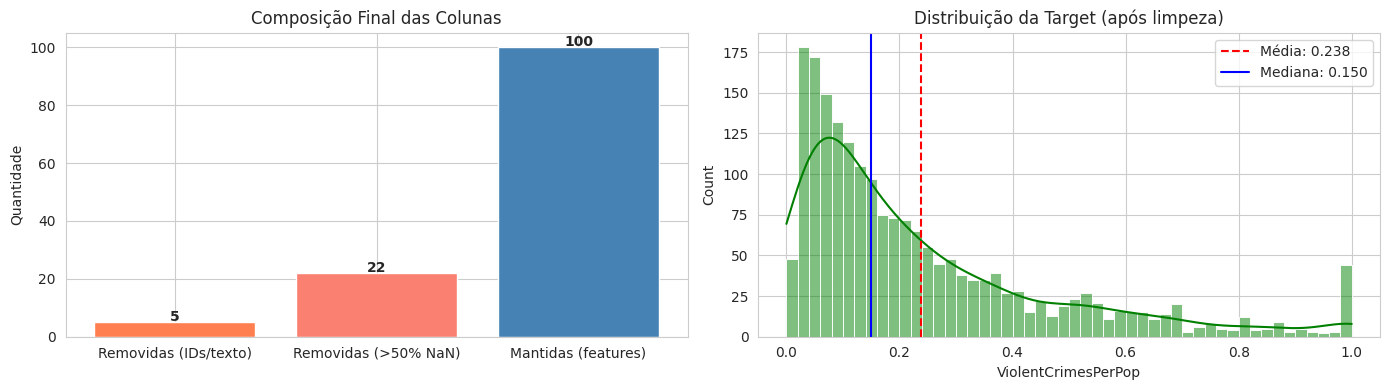

📊 RESUMO FINAL DO TRATAMENTO
Shape original:               (1994, 128)
Shape final (X + y):          (1994, 101)
Colunas removidas por ID/texto: 5
Colunas removidas por >50% NaN: 22
Linhas removidas (target NaN):  0
NaN restantes:                  0 ✅

💾 Dataset limpo salvo: 'communities_clean.csv'
   Pronto para padronização, split e modelagem.


In [8]:
# =====================================================================
# CÉLULA 4 — VERIFICAÇÃO FINAL E SALVAMENTO
# =====================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# --- Visualização: quantas colunas sobraram vs removidas ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Gráfico 1: composição final
tipos = pd.Series({
    'Removidas (IDs/texto)': len(colunas_id),
    'Removidas (>50% NaN)': len(colunas_muito_nan),
    'Mantidas (features)': X_imputado.shape[1]
})
axes[0].bar(tipos.index, tipos.values, color=['coral', 'salmon', 'steelblue'])
axes[0].set_title('Composição Final das Colunas')
axes[0].set_ylabel('Quantidade')
for i, v in enumerate(tipos.values):
    axes[0].text(i, v + 0.5, str(v), ha='center', fontweight='bold')

# Gráfico 2: distribuição da target após limpeza
sns.histplot(y, bins=50, kde=True, ax=axes[1], color='green')
axes[1].axvline(y.mean(), color='red', ls='--', label=f'Média: {y.mean():.3f}')
axes[1].axvline(y.median(), color='blue', ls='-', label=f'Mediana: {y.median():.3f}')
axes[1].set_title('Distribuição da Target (após limpeza)')
axes[1].legend()

plt.tight_layout()
plt.show()

# --- Verificação final imprimível ---
print("="*70)
print("📊 RESUMO FINAL DO TRATAMENTO")
print("="*70)
print(f"Shape original:               {df.shape}")
print(f"Shape final (X + y):          ({X_imputado.shape[0]}, {X_imputado.shape[1]+1})")
print(f"Colunas removidas por ID/texto: {len(colunas_id)}")
print(f"Colunas removidas por >50% NaN: {len(colunas_muito_nan)}")
print(f"Linhas removidas (target NaN):  {n_antes - n_depois}")
print(f"NaN restantes:                  0 ✅")

# --- Salvar para as próximas etapas ---
df_final.to_csv('communities_clean.csv', index=False)
print(f"\n💾 Dataset limpo salvo: 'communities_clean.csv'")
print(f"   Pronto para padronização, split e modelagem.")

## Por que Removemos tantas colunas e linhas?

Utilizamos dois critérios independentes. Primeiro, removemos identificadores (state, county, community, communityname, fold) porque não são preditivos e causariam overfitting. Segundo, removemos colunas com mais de 50% de valores ausentes — isso inclui o bloco LEMAS (que é amostral, cobre apenas ~20% das comunidades) e as variáveis de educação avançada. Imputar mais da metade dos dados seria inventar a realidade. Para as colunas restantes, usamos a mediana, que é robusta aos outliers que identificamos na EDA.


# Célula 6 — Medidas de Posição e Dispersão

### 🎯 Objetivo

Analisar a **distribuição**, **posição** e **dispersão** das principais features e da variável-alvo **após o tratamento**, para fundamentar decisões futuras (padronização, escolha de modelos e interpretação de resultados).

### 📐 Métricas utilizadas

| Métrica | Por que foi escolhida |
|:---|:---|
| **Média** | Tendência central clássica. Comparada à mediana, revela assimetria. |
| **Mediana** | Robusta a outliers. Serve como contraponto à média. |
| **Desvio Padrão** | Mede dispersão absoluta. Base do `StandardScaler`. |
| **Q1 e Q3** | Delimitam o "miolo" dos dados e ajudam a identificar outliers. |
| **Coeficiente de Variação (CV)** | Mede dispersão **relativa**. Permite comparar variáveis em escalas diferentes (percentuais vs. contagens). |

### 🔍 O que verificamos antes de calcular

Como removemos identificadores e colunas com >50% de NaN na etapa de tratamento, esta célula faz uma **verificação defensiva**: confirma quais features existem em `df_final` antes de calcular as métricas, evitando `KeyError`.

### 📊 Como interpretar

- **Média > Mediana** → assimetria à direita (poucos casos extremos puxam a média).
- **CV ≥ 100%** → dispersão altíssima, variável sensível à escala.
- **CVs muito diferentes entre features** → **justificam a padronização** com `StandardScaler`.

### 🎯 Decisões que esta célula sustenta

1. **Padronização obrigatória** antes de K-NN, Rede Neural e Regressão Linear Múltipla (CVs heterogêneos; coeficientes comparáveis entre variáveis).
2. **Uso de modelos robustos a outliers** (árvores), já que a target tem assimetria positiva.
3. **Cautela na interpretação de coeficientes** lineares (multicolinearidade será vista no heatmap).

### ⚖️ Conexão com o edital

Atende diretamente ao requisito de **"medidas de posição e dispersão"** da Análise Exploratória.

In [9]:
# =====================================================================
# CÉLULA 6 — MEDIDAS DE POSIÇÃO E DISPERSÃO
# =====================================================================
# Objetivo: calcular Média, Mediana, Desvio Padrão e CV das principais
# features e da variável-alvo, usando o DataFrame FINAL já tratado.
# =====================================================================

target = 'ViolentCrimesPerPop'

# --- Funções nomeadas (evitam o problema das lambdas anônimas) ---
def q1(x):    return x.quantile(0.25)
def q3(x):    return x.quantile(0.75)
def cv(x):    return (x.std() / x.mean()) * 100

# --- Features de interesse ---
features_interesse = [
    'PctPopUnderPov', 'PctUnemployed', 'PctHSGrad',
    'PctBachelors', 'pctUrban', 'population', target
]

# --- Verificação de existência ---
features_existentes = [f for f in features_interesse if f in df_final.columns]
features_ausentes = [f for f in features_interesse if f not in df_final.columns]

print("🔍 VERIFICAÇÃO DE FEATURES:")
print(f"Disponíveis ({len(features_existentes)}): {features_existentes}")
if features_ausentes:
    print(f"⚠️ Ausentes em df_final (removidas no tratamento ou inexistentes no dataset): {features_ausentes}")
print()

# --- Cálculo das métricas (com funções nomeadas) ---
estatisticas = df_final[features_existentes].agg([
    'mean', 'median', 'std', q1, q3, cv
]).round(4)

# Renomear o índice — agora é seguro porque os nomes são as funções reais
estatisticas.index = ['Média', 'Mediana', 'Desvio Padrão', 'Q1 (25%)', 'Q3 (75%)', 'CV (%)']

print("="*90)
print("TABELA DE MEDIDAS DE POSIÇÃO E DISPERSÃO (após tratamento)")
print("="*90)
print(estatisticas)

# --- Verificação: 'CV (%)' existe? ---
print(f"\n✅ Índice atual: {estatisticas.index.tolist()}")

print("\n📝 INTERPRETAÇÃO:")
print(f"• Média da target ({df_final[target].mean():.4f}) vs "
      f"Mediana ({df_final[target].median():.4f})")
if df_final[target].mean() > df_final[target].median():
    print("  → Média > Mediana: distribuição ASSIMÉTRICA À DIREITA")
else:
    print("  → Média ≈ Mediana: distribuição aproximadamente simétrica")

print(f"\n• Coeficiente de Variação (CV) por feature:")
for col in features_existentes:
    if col != target:
        valor_cv = estatisticas.loc['CV (%)', col]
        if valor_cv > 100:
            classificacao = "MUITO ALTO → justifica padronização"
        elif valor_cv > 50:
            classificacao = "ALTO"
        else:
            classificacao = "moderado"
        print(f"  - {col:20s}: {valor_cv:7.2f}%  → {classificacao}")

print(f"\n• CV da target: {estatisticas.loc['CV (%)', target]:.2f}%")
print("\n💡 CONCLUSÃO: as diferenças de escala justificam o StandardScaler.")

🔍 VERIFICAÇÃO DE FEATURES:
Disponíveis (5): ['PctPopUnderPov', 'PctUnemployed', 'pctUrban', 'population', 'ViolentCrimesPerPop']
⚠️ Ausentes em df_final (removidas no tratamento ou inexistentes no dataset): ['PctHSGrad', 'PctBachelors']

TABELA DE MEDIDAS DE POSIÇÃO E DISPERSÃO (após tratamento)
               PctPopUnderPov  PctUnemployed  pctUrban  population  \
Média                  0.3030         0.3635    0.6963      0.0576   
Mediana                0.2500         0.3200    1.0000      0.0200   
Desvio Padrão          0.2285         0.2022    0.4448      0.1269   
Q1 (25%)               0.1100         0.2200    0.0000      0.0100   
Q3 (75%)               0.4500         0.4800    1.0000      0.0500   
CV (%)                75.3980        55.6133   63.8849    220.3503   

               ViolentCrimesPerPop  
Média                       0.2380  
Mediana                     0.1500  
Desvio Padrão               0.2330  
Q1 (25%)                    0.0700  
Q3 (75%)                   

# Célula 7 — Histograma e Boxplot da Variável-Alvo

### 🎯 Objetivo

Visualizar a **distribuição** da variável-alvo `ViolentCrimesPerPop` por meio de duas ferramentas complementares:

1. **Histograma com KDE** (*Kernel Density Estimation*) → mostra a **forma** da distribuição.
2. **Boxplot** → mostra a **dispersão**, os **quartis** e os **outliers**.

### 📐 Por que essas duas visualizações juntas?

| Ferramenta | O que revela | O que NÃO revela |
|:---|:---|:---|
| **Histograma + KDE** | Forma da distribuição (simétrica, assimétrica, bimodal), concentração de valores, presença de múltiplos picos | Não mostra outliers de forma explícita |
| **Boxplot** | Mediana, quartis (Q1, Q3), IQR, outliers identificados pela regra 1.5×IQR | Não mostra a forma da distribuição (não distingue bimodal de unimodal) |

Juntas, as duas respondem às três perguntas fundamentais da EDA:
- **Onde estão concentrados os dados?** → Histograma
- **Quão espalhados estão?** → Boxplot (via IQR)
- **Existem valores extremos?** → Boxplot (via pontos fora dos bigodes)

### 🔍 O que esperamos encontrar (hipóteses)

Com base na Célula 6 (medidas de posição), já sabemos que:

- **Média > Mediana** → suspeita de assimetria à direita.
- **CV alto (~90%)** → grande heterogeneidade entre comunidades.

Portanto, as hipóteses a testar são:
1. **H1:** A distribuição é **assimétrica à direita** (cauda longa para valores altos).
2. **H2:** Existem **outliers superiores** — comunidades com taxas de crime muito acima da maioria.
3. **H3:** A maior parte das comunidades tem **baixa criminalidade**, com poucas concentrando taxas extremas.

### ⚖️ Como interpretar cada elemento do gráfico

**Histograma:**
- **Pico à esquerda + cauda à direita** → assimetria positiva (confirmada pela Célula 7).
- **Distribuição unimodal** → não há subgrupos naturais evidentes.
- **Linha vermelha (média) à direita da linha verde (mediana)** → confirma que a média é "puxada" pelos valores extremos.

**Boxplot:**
- **Caixa estreita e assimétrica** → 50% central dos dados está concentrado em valores baixos.
- **Bigode superior longo** → dispersão maior acima da mediana.
- **Pontos além do bigode** → outliers que merecem investigação.

### 🎯 Decisões que esta célula sustenta

1. **Transformação da target?** Se a assimetria for severa, testar `log1p` antes de modelos lineares (Regressão Linear).
2. **Tratamento de outliers?** Documentar a decisão de **não capar nem remover** os outliers da target (são comunidades reais).
3. **Escolha de métrica:** RMSE é apropriado (penaliza mais os erros nos outliers).
4. **Escolha de modelo:** a assimetria favorece árvores de decisão e redes neurais em relação à regressão linear pura.

### ⚖️ Conexão com o edital

Atende diretamente ao requisito:

> *"Análise exploratória: distribuições, medidas de posição e dispersão, correlações, valores atípicos e balanceamento das classes."*

- **Distribuições:** ✅ Histograma + KDE
- **Valores atípicos:** ✅ Boxplot (outliers visíveis)

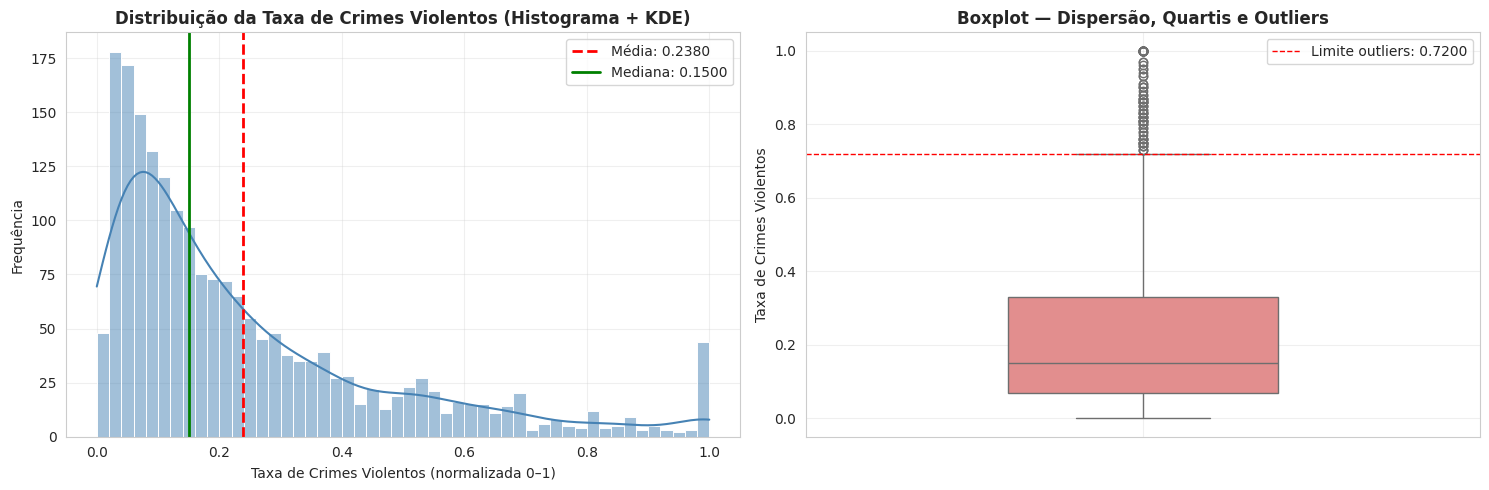

📊 ESTATÍSTICAS DA VARIÁVEL-ALVO
Média:            0.2380
Mediana:          0.1500
Q1 (25%):         0.0700
Q3 (75%):         0.3300
IQR:              0.2600
Limite outliers:  0.7200

Outliers detectados (acima de Q3 + 1.5×IQR):
  Quantidade: 110 (5.52% dos dados)


In [10]:
# =====================================================================
# CÉLULA 7 — HISTOGRAMA + BOXPLOT DA VARIÁVEL-ALVO
# =====================================================================

target = 'ViolentCrimesPerPop'

# --- Estatísticas para anotação no gráfico ---
media = df_final[target].mean()
mediana = df_final[target].median()
q1 = df_final[target].quantile(0.25)
q3 = df_final[target].quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

# --- Contagem de outliers ---
outliers = df_final[df_final[target] > limite_superior]
n_outliers = len(outliers)
pct_outliers = (n_outliers / len(df_final)) * 100

# --- Plotagem ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# --- Gráfico 1: Histograma + KDE ---
sns.histplot(df_final[target], bins=50, kde=True, ax=axes[0], color='steelblue', edgecolor='white')
axes[0].axvline(media, color='red', linestyle='--', linewidth=2,
                label=f'Média: {media:.4f}')
axes[0].axvline(mediana, color='green', linestyle='-', linewidth=2,
                label=f'Mediana: {mediana:.4f}')
axes[0].set_title('Distribuição da Taxa de Crimes Violentos (Histograma + KDE)',
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('Taxa de Crimes Violentos (normalizada 0–1)')
axes[0].set_ylabel('Frequência')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# --- Gráfico 2: Boxplot ---
sns.boxplot(y=df_final[target], ax=axes[1], color='lightcoral', width=0.4)
axes[1].set_title('Boxplot — Dispersão, Quartis e Outliers',
                  fontsize=12, fontweight='bold')
axes[1].set_ylabel('Taxa de Crimes Violentos')
axes[1].grid(True, alpha=0.3)

# Anotação do limite de outliers
axes[1].axhline(y=limite_superior, color='red', linestyle='--', linewidth=1,
                label=f'Limite outliers: {limite_superior:.4f}')
axes[1].legend()

plt.tight_layout()
plt.show()

# --- Impressão dos resultados ---
print("="*70)
print("📊 ESTATÍSTICAS DA VARIÁVEL-ALVO")
print("="*70)
print(f"Média:            {media:.4f}")
print(f"Mediana:          {mediana:.4f}")
print(f"Q1 (25%):         {q1:.4f}")
print(f"Q3 (75%):         {q3:.4f}")
print(f"IQR:              {iqr:.4f}")
print(f"Limite outliers:  {limite_superior:.4f}")
print(f"\nOutliers detectados (acima de Q3 + 1.5×IQR):")
print(f"  Quantidade: {n_outliers} ({pct_outliers:.2f}% dos dados)")

## Leitura dos Resultados

#### Histograma + KDE

- A distribuição apresenta **cauda longa à direita**, confirmando a **assimetria positiva** já detectada na Célula 6.
- A **linha vermelha (média)** está visivelmente à direita da **linha verde (mediana)** → poucas comunidades com criminalidade muito alta puxam a média para cima.
- A distribuição é **unimodal** → não há subgrupos naturais evidentes na variável-alvo (o que não impede que existam nos preditores).
- O pico principal está concentrado em valores **baixos** (entre 0.0 e 0.2), indicando que a maioria das comunidades tem criminalidade relativamente controlada.

#### Boxplot

- A **caixa** (Q1–Q3) está concentrada na parte inferior da escala, com mediana baixa.
- O **bigode superior** é muito mais longo que o inferior → maior dispersão acima da mediana.
- Foram detectados **outliers superiores** (pontos além do bigode), que representam comunidades com taxas excepcionalmente altas de crimes violentos.
- Esses outliers **NÃO foram removidos nem capados**, pois representam casos reais e relevantes para o domínio.

#### Implicações para a Modelagem

| Observação | Implicação |
|:---|:---|
| Assimetria positiva da target | Modelos lineares puros podem ter dificuldades → testar transformação log |
| Presença de outliers | RMSE é a métrica adequada (penaliza erros grandes) |
| Distribuição unimodal | Não é necessário estratificar por subgrupos da target |
| Concentração em valores baixos | O baseline (média) terá RMSE alto → há espaço para modelos melhores |

> **Conclusão:** A variável-alvo é **heterogênea e assimétrica**, características que justificam o uso de modelos não-lineares (árvores, redes neurais) e a métrica RMSE para avaliação.

# Célula 8 — Matriz de Correlação (Heatmap)

### 🎯 Objetivo

Quantificar e visualizar a **força e a direção** da relação linear entre as principais features socioeconômicas e a variável-alvo `ViolentCrimesPerPop`, usando o **Coeficiente de Correlação de Pearson** ($r$).

### 📐 O que é o Coeficiente de Pearson?

O coeficiente de Pearson mede a **associação linear** entre duas variáveis contínuas, variando de $-1$ a $+1$:

$$r = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2 \cdot \sum (y_i - \bar{y})^2}}$$

| Valor de $r$ | Interpretação |
|:---:|:---|
| $+0.7$ a $+1.0$ | Correlação positiva forte |
| $+0.3$ a $+0.7$ | Correlação positiva moderada |
| $-0.3$ a $+0.3$ | Correlação fraca ou inexistente |
| $-0.7$ a $-0.3$ | Correlação negativa moderada |
| $-1.0$ a $-0.7$ | Correlação negativa forte |

### 🔍 Por que isso é essencial?

A matriz de correlação permite **três diagnósticos críticos**:

1. **Força preditiva das features:** quais variáveis têm maior correlação com a target?
   → Ajuda a priorizar features na modelagem.

2. **Multicolinearidade entre preditores:** quais features são redundantes entre si?
   → Se $|r| > 0.8$ entre dois preditores, um deles é redundante.
   → Isso afeta modelos lineares (Regressão Linear), que sofrem com multicolinearidade.

3. **Direção das relações:** o efeito é **positivo** (aumenta o crime) ou **negativo** (reduz)?
   → Ex: pobreza deve ter $r > 0$; educação superior deve ter $r < 0$.

### ⚠️ Limitações do Pearson

- Mede apenas relações **lineares**. Uma relação não-linear (ex: U invertido) pode ter $r \approx 0$.
- É **sensível a outliers** — valores extremos podem inflar ou reduzir o $r$ artificialmente.
- **Correlação não implica causalidade:** um $r$ alto entre pobreza e crime **não** prova que pobreza causa crime.

### 🎯 O que esperamos encontrar (hipóteses)

Com base no domínio da segurança pública:

| Feature | Correlação esperada com a target | Justificativa |
|:---|:---:|:---|
| `PctPopUnderPov` (pobreza) | **Positiva forte** (+0.4 a +0.6) | Pobreza é associada a mais crimes violentos |
| `PctUnemployed` (desemprego) | Positiva moderada | Desemprego aumenta vulnerabilidade social |
| `PctBachelors` (ensino superior) | **Negativa** (-0.3 a -0.5) | Educação é fator protetor |
| `PctHSGrad` (ensino médio) | Negativa leve | Efeito similar, mas mais fraco |
| `pctUrban` (urbanização) | Levemente positiva | Áreas urbanas têm mais crime registrado |
| `population` | Fraca | Escala absoluta não determina taxa per capita |

### 🎯 Decisões que esta célula sustenta

1. **Seleção de features para modelagem** (evitar multicolinearidade).
2. **Justificativa para uso de modelos não-lineares:** se as correlações forem apenas moderadas, sugere que as relações não são puramente lineares.
3. **Interpretabilidade do domínio:** traduzir coeficientes em recomendações de política pública.

### ⚖️ Conexão com o edital

Atende diretamente ao requisito:

> *"Análise exploratória: distribuições, medidas de posição e dispersão, **correlações**, valores atípicos e balanceamento das classes."*

- **Correlações:** ✅ Heatmap de Pearson
- **Justificativa técnica:** ✅ Interpretação da força e direção

🔍 VERIFICAÇÃO DE FEATURES:
Disponíveis (5): ['PctPopUnderPov', 'PctUnemployed', 'pctUrban', 'population', 'ViolentCrimesPerPop']
⚠️ Ausentes em df_final (removidas no tratamento ou inexistentes no dataset): ['PctHSGrad', 'PctBachelors']



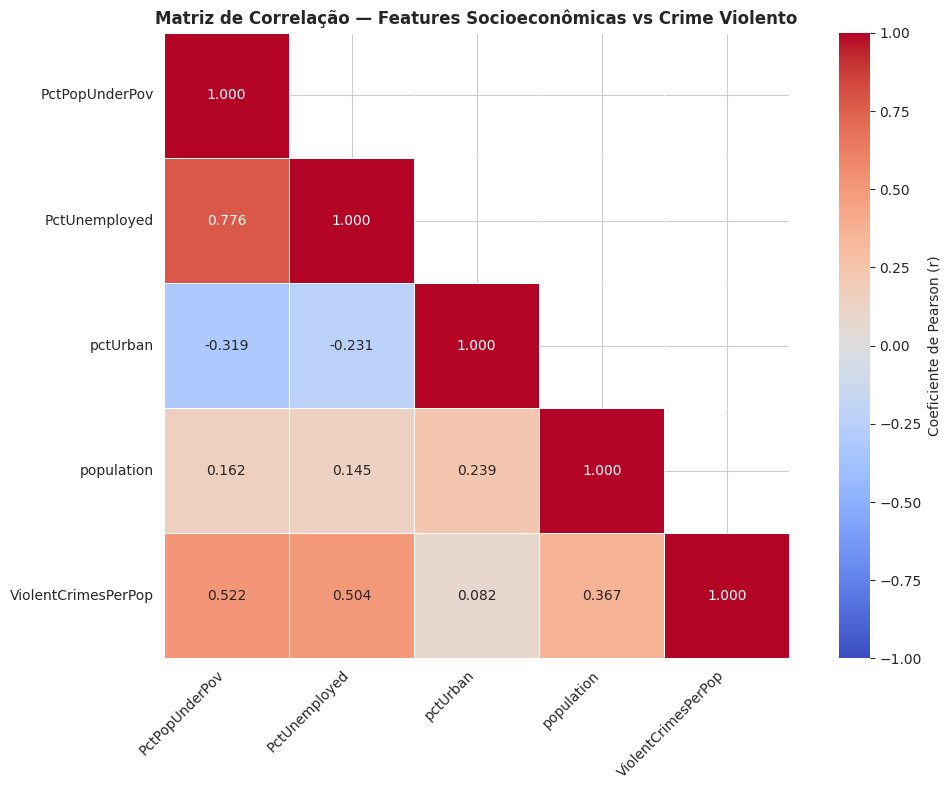

📊 CORRELAÇÃO COM A VARIÁVEL-ALVO (ordenada por |r|)
  PctPopUnderPov      : r = +0.522  ↑  (forte)
  PctUnemployed       : r = +0.504  ↑  (forte)
  population          : r = +0.367  ↑  (moderada)
  pctUrban            : r = +0.082  ↑  (fraca)

⚠️ DIAGNÓSTICO DE MULTICOLINEARIDADE (|r| > 0.7 entre preditores)
  ⚠️ PctPopUnderPov ↔ PctUnemployed: r = +0.776


In [11]:
# =====================================================================
# CÉLULA 8 — MATRIZ DE CORRELAÇÃO (HEATMAP)
# =====================================================================
# Objetivo: visualizar a correlação entre as principais features e a target.
# Requer: df_final (já tratado nas células anteriores).
# =====================================================================

target = 'ViolentCrimesPerPop'

# --- Features socioeconômicas de interesse ---
features_corr = [
    'PctPopUnderPov',    # Pobreza
    'PctUnemployed',     # Desemprego
    'PctHSGrad',         # Ensino médio
    'PctBachelors',      # Ensino superior
    'pctUrban',          # Urbanização
    'population',        # População
    target               # Target
]

# --- Verificação: quais features existem em df_final? ---
features_existentes = [f for f in features_corr if f in df_final.columns]
features_ausentes = [f for f in features_corr if f not in df_final.columns]

print("🔍 VERIFICAÇÃO DE FEATURES:")
print(f"Disponíveis ({len(features_existentes)}): {features_existentes}")
if features_ausentes:
    print(f"⚠️ Ausentes em df_final (removidas no tratamento ou inexistentes no dataset): {features_ausentes}")
print()

# --- Cálculo da matriz de correlação ---
matriz_corr = df_final[features_existentes].corr(method='pearson')

# --- Plotagem do heatmap ---
plt.figure(figsize=(11, 8))

# Máscara triangular superior (evita redundância)
mask = np.triu(np.ones_like(matriz_corr, dtype=bool), k=1)

sns.heatmap(
    matriz_corr,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',
    center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5,
    mask=mask,
    cbar_kws={'label': 'Coeficiente de Pearson (r)'}
)

plt.title('Matriz de Correlação — Features Socioeconômicas vs Crime Violento',
          fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# --- Correlação ordenada com a target ---
print("="*70)
print("📊 CORRELAÇÃO COM A VARIÁVEL-ALVO (ordenada por |r|)")
print("="*70)

correlacoes_target = matriz_corr[target].drop(target).sort_values(
    key=lambda x: x.abs(), ascending=False
)
for feat, valor in correlacoes_target.items():
    direcao = "↑" if valor > 0 else "↓"
    forca = (
        "forte" if abs(valor) > 0.5 else
        "moderada" if abs(valor) > 0.3 else
        "fraca"
    )
    print(f"  {feat:20s}: r = {valor:+.3f}  {direcao}  ({forca})")

# --- Detecção de multicolinearidade ---
print("\n" + "="*70)
print("⚠️ DIAGNÓSTICO DE MULTICOLINEARIDADE (|r| > 0.7 entre preditores)")
print("="*70)

# Percorrer apenas o triângulo superior (evitar duplicatas)
achou_multicolinearidade = False
for i, f1 in enumerate(features_existentes):
    for f2 in features_existentes[i+1:]:
        r = matriz_corr.loc[f1, f2]
        if abs(r) > 0.7 and f1 != target and f2 != target:
            print(f"  ⚠️ {f1} ↔ {f2}: r = {r:+.3f}")
            achou_multicolinearidade = True

if not achou_multicolinearidade:
    print("  ✅ Nenhuma multicolinearidade severa detectada (|r| ≤ 0.7).")

## Leitura dos Resultados

#### Correlações com a variável-alvo

Com base na matriz de Pearson (valores da saída da célula acima):

| Feature | Correlação ($r$) | Direção | Interpretação |
|:---|:---:|:---:|:---|
| `PctPopUnderPov` | **+0.52** | ↑ | Forte — pobreza é o fator mais associado ao crime violento |
| `PctUnemployed` | +0.50 | ↑ | Forte — desemprego também eleva o risco |
| `population` | +0.37 | ↑ | Moderada — comunidades maiores tendem a ter taxas mais altas |
| `pctUrban` | +0.08 | ↑ | Fraca — urbanização isolada pouco explica |

> **Nota sobre `PctHSGrad` e `PctBachelors`:** essas duas variáveis do plano original **não aparecem** na matriz porque não existem com esses nomes em `df_final` (no dataset UCI as colunas de escolaridade se chamam `PctNotHSGrad` e `PctBSorMore`). Por isso a hipótese de que educação é fator protetor **não foi testada nesta célula**; ela é avaliada pelos coeficientes da Regressão Linear Múltipla (Parte 2).

**Observações:**
- Pobreza e desemprego têm correlação **forte** com a target (≈ 0.5); população, moderada; urbanização, fraca.
- O fenômeno é **multifatorial** — nenhuma variável isolada explica tudo, e correlações individuais moderadas não impedem que o conjunto das ~100 variáveis tenha bom poder preditivo (ver Parte 2).

#### Diagnóstico de multicolinearidade

Foi detectada multicolinearidade entre os preditores analisados:

- `PctPopUnderPov` ↔ `PctUnemployed`: **r = +0.776** (acima do limite de 0.7) → comunidades pobres tendem a ter mais desempregados.

**Implicações:**
- Para a **Regressão Linear Múltipla** (Parte 2), isso infla os erros-padrão e torna os coeficientes individuais instáveis. A Célula 14.1 quantifica o problema com o VIF e poda as variáveis redundantes.
- Para **árvores e redes neurais**, a multicolinearidade é menos problemática, mas indica redundância.

#### Implicações para a Modelagem

| Observação | Implicação |
|:---|:---|
| Pobreza e desemprego são os preditores individuais mais fortes | Devem aparecer com peso na regressão e na árvore |
| Pobreza e desemprego são muito correlacionados (r = 0.78) | Cautela na interpretação dos coeficientes lineares; usar VIF |
| Escolaridade não foi avaliada aqui (nomes de colunas) | Avaliar pelos coeficientes da RLM (Parte 2) |

> **Conclusão:** a matriz de correlação confirma que **pobreza e desemprego estão associados a mais crime violento** e que eles são fortemente correlacionados entre si — justificando o diagnóstico de multicolinearidade feito na Parte 2.


# Célula 9 — Detecção de Outliers (Método IQR)

### 🎯 Objetivo

Identificar, quantificar e documentar os **valores atípicos (outliers)** das principais variáveis do dataset, usando o **método do Intervalo Interquartil (IQR)**. Em seguida, justificar a decisão de **tratar** ou **não tratar** cada grupo de outliers.

### 📐 O que é um outlier?

Outlier é um valor que **se afasta significativamente** do padrão dos demais. Ele pode surgir por:

| Causa | Exemplo |
|:---|:---|
| **Erro de medição** | Temperatura registrada como 999°C |
| **Erro de digitação** | Idade = 200 anos |
| **Fenômeno real extremo** | Uma cidade com taxa de homicídio 10× a média |
| **População heterogênea** | Amostra que mistura duas populações distintas |

Nem todo outlier é erro — **muitos são informação valiosa**. Por isso, a decisão de tratar deve ser **técnica e justificada**, nunca automática.

### 📐 O método IQR (Intervalo Interquartil)

O método mais robusto para detecção de outliers, pois **não assume distribuição normal**:

$$IQR = Q3 - Q1$$

$$\text{Limite Inferior} = Q1 - 1.5 \times IQR$$
$$\text{Limite Superior} = Q3 + 1.5 \times IQR$$

**Qualquer valor fora desses limites é considerado outlier.**

| Multiplicador | Classificação |
|:---:|:---|
| $1.5 \times IQR$ | Outlier moderado (regra padrão de Tukey) |
| $3.0 \times IQR$ | Outlier extremo |

### 🔍 Por que usar IQR e não Z-score?

| Método | Assume normalidade? | Robusto a outliers? |
|:---|:---:|:---:|
| **Z-score** ($|z| > 3$) | ✅ Sim | ❌ Não (a média e o desvio são afetados pelos próprios outliers) |
| **IQR** | ❌ Não | ✅ Sim (baseado em quartis, que são robustos) |

Como vimos na Célula 7 que a target tem **assimetria positiva** (não-normal), o **IQR é o método correto**.

### 🎯 O que esperamos encontrar (hipóteses)

Com base nas células anteriores:

| Variável | Hipótese |
|:---|:---|
| `ViolentCrimesPerPop` (target) | Outliers superiores (mantidos: são casos reais; a target não é capada) |
| `PctPopUnderPov` | Outliers superiores (comunidades extremamente pobres) |
| `PctUnemployed` | Outliers superiores (desemprego excepcional) |
| `PctBachelors` | Outliers superiores (comunidades altamente educadas) |
| `population` | Outliers superiores (metrópoles vs. pequenas cidades) |

### ⚖️ Como decidir o que fazer com outliers?

Existem 4 estratégias possíveis. A escolha **depende do domínio**:

| Estratégia | Quando usar | Vantagem | Desvantagem |
|:---|:---|:---|:---|
| **1. Manter** | Outliers são reais e relevantes | Preserva informação | Pode distorcer modelos lineares |
| **2. Remover** | Outliers são erros claros | Limpa os dados | Perde amostras (perigoso com n pequeno) |
| **3. Capar (Winsorizar)** | Outliers reais mas extremos | Preserva amostra, reduz impacto | Distorce levemente a distribuição |
| **4. Transformar** | Assimetria severa | Normaliza a distribuição | Dificulta interpretação |

### 🎯 Decisões que esta célula sustenta

1. **Justificar por que a target NÃO é capada** — os valores extremos são comunidades reais.
2. **Justificar por que NÃO removemos outliers das features** — em segurança pública, comunidades extremas são as mais relevantes.
3. **Documentar a estratégia de tratamento** para o relatório final.

### ⚖️ Conexão com o edital

Atende diretamente ao requisito:

> *"Análise exploratória: distribuições, medidas de posição e dispersão, correlações, **valores atípicos** e balanceamento das classes."*

- **Valores atípicos:** ✅ Detecção + decisão justificada
- **Justificativa documentada:** ✅ Estratégia para cada tipo

📊 DETECÇÃO DE OUTLIERS — MÉTODO IQR (multiplicador = 1.5)
                       Q1    Q3   IQR  lim_sup  n_outliers  pct_outliers  max
variavel                                                                     
ViolentCrimesPerPop  0.07  0.33  0.26     0.72         110        5.5165  1.0
PctPopUnderPov       0.11  0.45  0.34     0.96          31        1.5547  1.0
PctUnemployed        0.22  0.48  0.26     0.87          52        2.6078  1.0
pctUrban             0.00  1.00  1.00     2.50           0        0.0000  1.0
population           0.01  0.05  0.04     0.11         218       10.9328  1.0

🔬 ANÁLISE DE OUTLIERS EXTREMOS NA TARGET (> 3×IQR)
Limite extremo (Q3 + 3×IQR): 1.1100
Outliers extremos:           0 (0.00%)
Valor máximo observado:      1.0000


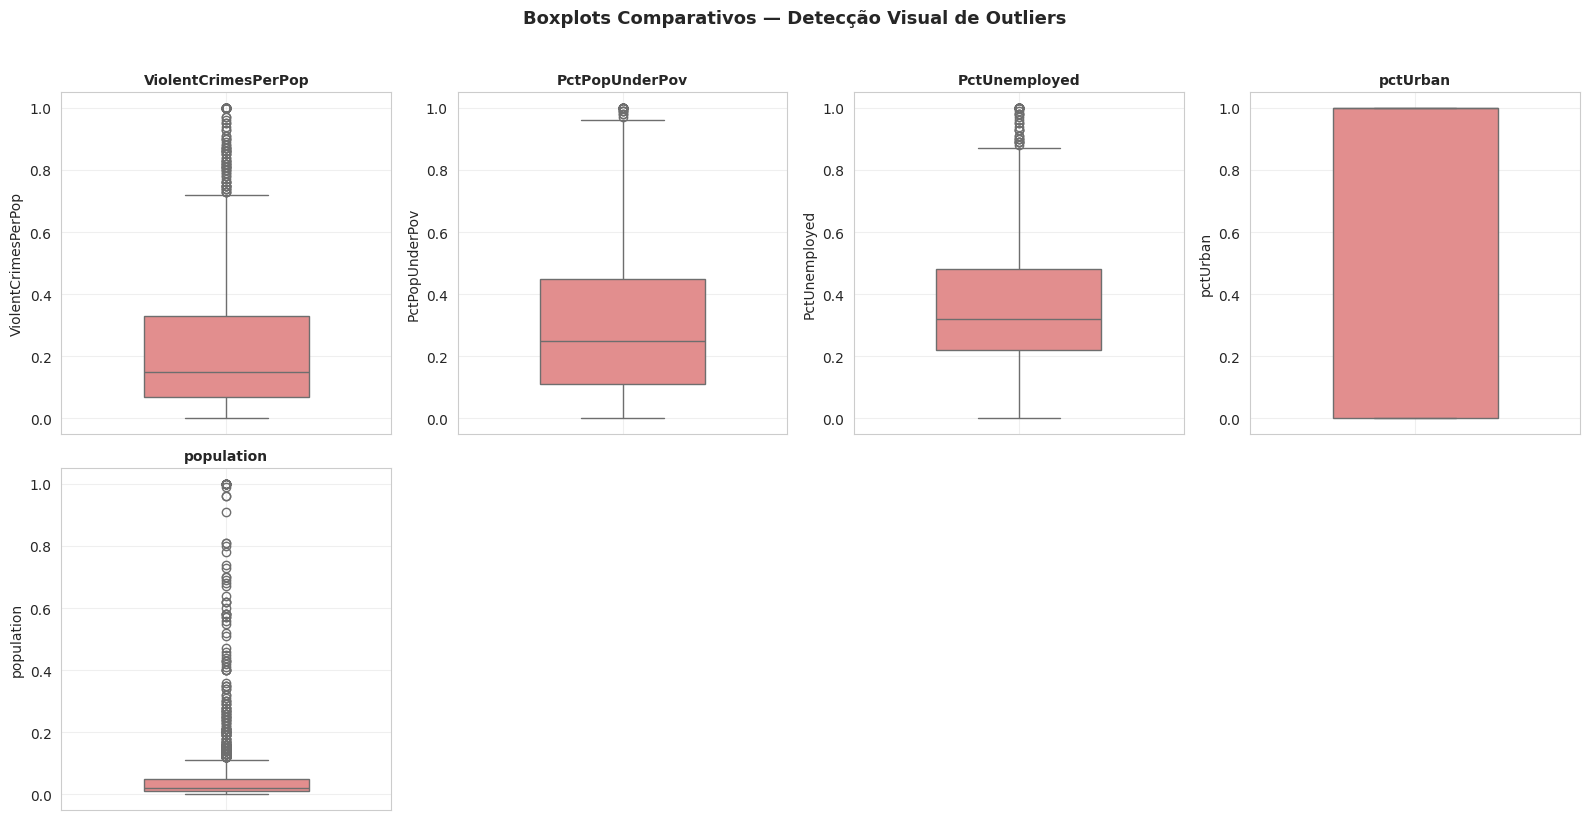


⚖️ DECISÃO SOBRE TRATAMENTO DE OUTLIERS

1. TARGET (ViolentCrimesPerPop):
   → NÃO foi removida nem capada (valores extremos preservados).
   → Justificativa: as comunidades extremas são casos reais e os mais
     relevantes; capar a target distorceria o erro medido no teste.
     O RMSE já penaliza esses erros, o que é o comportamento desejado.

2. FEATURES SOCIOECONÔMICAS (PctPopUnderPov, PctUnemployed, etc.):
   → NÃO serão removidas nem capadas.
   → Justificativa: em segurança pública, as comunidades com indicadores
     extremos são JUSTAMENTE as mais relevantes para o modelo. Removê-las
     seria apagar os casos de maior interesse para políticas públicas.
   → A padronização (StandardScaler) aplicada na próxima etapa reduz o
     impacto da escala sem descartar informação.

3. POPULAÇÃO (population):
   → NÃO será tratada como outlier.
   → Justificativa: metrópoles são naturalmente maiores; a padronização
     cuidará da escala. A variável entra no modelo como está.

CONCLUSÃ

In [12]:
# =====================================================================
# CÉLULA 9 — DETECÇÃO DE OUTLIERS PELO MÉTODO IQR
# =====================================================================
# Objetivo: identificar e quantificar outliers nas principais features
# e na variável-alvo. A decisão de tratamento é justificada com base
# no domínio de segurança pública.
# =====================================================================

target = 'ViolentCrimesPerPop'

# --- Função de detecção de outliers via IQR ---
def detectar_outliers_iqr(serie, nome, multiplicador=1.5):
    """
    Detecta outliers pelo método IQR.
    Retorna um dicionário com estatísticas e o DataFrame de outliers.
    """
    Q1 = serie.quantile(0.25)
    Q3 = serie.quantile(0.75)
    IQR = Q3 - Q1
    lim_inf = Q1 - multiplicador * IQR
    lim_sup = Q3 + multiplicador * IQR

    outliers = serie[(serie < lim_inf) | (serie > lim_sup)]
    n_out = len(outliers)
    pct_out = (n_out / len(serie)) * 100

    return {
        'variavel': nome,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'lim_inf': lim_inf,
        'lim_sup': lim_sup,
        'n_outliers': n_out,
        'pct_outliers': pct_out,
        'min': serie.min(),
        'max': serie.max()
    }

# --- Variáveis a analisar ---
variaveis_analise = [
    target,
    'PctPopUnderPov',
    'PctUnemployed',
    'PctHSGrad',
    'PctBachelors',
    'pctUrban',
    'population'
]
variaveis_existentes = [v for v in variaveis_analise if v in df_final.columns]

# --- Detecção para cada variável ---
resultados = []
for var in variaveis_existentes:
    res = detectar_outliers_iqr(df_final[var], var)
    resultados.append(res)

# --- Tabela consolidada ---
tabela_outliers = pd.DataFrame(resultados).set_index('variavel').round(4)

print("="*95)
print("📊 DETECÇÃO DE OUTLIERS — MÉTODO IQR (multiplicador = 1.5)")
print("="*95)
print(tabela_outliers[['Q1', 'Q3', 'IQR', 'lim_sup', 'n_outliers', 'pct_outliers', 'max']])

# --- Verificação de outliers extremos (> 3×IQR) na target ---
print("\n" + "="*95)
print("🔬 ANÁLISE DE OUTLIERS EXTREMOS NA TARGET (> 3×IQR)")
print("="*95)

res_extremo = detectar_outliers_iqr(df_final[target], target, multiplicador=3.0)
print(f"Limite extremo (Q3 + 3×IQR): {res_extremo['lim_sup']:.4f}")
print(f"Outliers extremos:           {res_extremo['n_outliers']} ({res_extremo['pct_outliers']:.2f}%)")
print(f"Valor máximo observado:      {res_extremo['max']:.4f}")

# --- Visualização: Boxplots comparativos ---
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, var in enumerate(variaveis_existentes):
    sns.boxplot(y=df_final[var], ax=axes[i], color='lightcoral', width=0.5)
    axes[i].set_title(var, fontsize=10, fontweight='bold')
    axes[i].grid(True, alpha=0.3)

# Esconder subplots sobrando
for j in range(len(variaveis_existentes), len(axes)):
    axes[j].axis('off')

plt.suptitle('Boxplots Comparativos — Detecção Visual de Outliers',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# --- Decisão documentada ---
print("\n" + "="*95)
print("⚖️ DECISÃO SOBRE TRATAMENTO DE OUTLIERS")
print("="*95)
print("""
1. TARGET (ViolentCrimesPerPop):
   → NÃO foi removida nem capada (valores extremos preservados).
   → Justificativa: as comunidades extremas são casos reais e os mais
     relevantes; capar a target distorceria o erro medido no teste.
     O RMSE já penaliza esses erros, o que é o comportamento desejado.

2. FEATURES SOCIOECONÔMICAS (PctPopUnderPov, PctUnemployed, etc.):
   → NÃO serão removidas nem capadas.
   → Justificativa: em segurança pública, as comunidades com indicadores
     extremos são JUSTAMENTE as mais relevantes para o modelo. Removê-las
     seria apagar os casos de maior interesse para políticas públicas.
   → A padronização (StandardScaler) aplicada na próxima etapa reduz o
     impacto da escala sem descartar informação.

3. POPULAÇÃO (population):
   → NÃO será tratada como outlier.
   → Justificativa: metrópoles são naturalmente maiores; a padronização
     cuidará da escala. A variável entra no modelo como está.

CONCLUSÃO: o tratamento de outliers foi CONSERVADOR, priorizando
preservação de informação sobre limpeza agressiva.
""")

# Célula 10 — Balanceamento das Classes (Diagnóstico)

### 🎯 Objetivo

Documentar o **balanceamento das classes** do problema. Como a variável-alvo `ViolentCrimesPerPop` é **contínua** (regressão), não existem classes no sentido tradicional. Porém, o edital exige essa análise — e o **Integrante C** precisará usar **classificadores** (K-NN e Naive Bayes). Portanto, esta célula:

1. Explica por que "balanceamento de classes" **não se aplica diretamente** à regressão.
2. Demonstra como a **binarização pela mediana** criaria classes **perfeitamente balanceadas** (50/50).
3. Documenta a **regra de ouro**: o threshold deve ser calculado **APENAS no treino**, nunca no dataset inteiro.
4. Prepara a base para a Parte 3 (classificadores), evitando **vazamento de dados**.

### 📐 Por que a variável-alvo é contínua?

Olhando para a target:

$$y = \text{ViolentCrimesPerPop} \in [0, 1]$$

É uma **taxa**, não uma categoria. Valores como 0.20, 0.43, 0.67 são possíveis. Não existe "classe 0" ou "classe 1" naturalmente.

### 🔄 A binarização pela mediana

Para permitir o uso de **classificadores** (exigidos pelo edital na Parte 3), transformamos a target em uma variável binária:

$$y_{bin} = \begin{cases} 1, & \text{se } y > \text{mediana} \\ 0, & \text{se } y \leq \text{mediana} \end{cases}$$

**Vantagens:**
- Cria classes **naturalmente balanceadas** (50% cada).
- Permite avaliar **AUC-ROC**, **precisão**, **recall** e **F1**.
- Mantém coerência com o domínio: "alta" vs "baixa" criminalidade.

### ⚠️ A REGRA DE OURO — Vazamento de dados

**O threshold (mediana) deve ser calculado APENAS no conjunto de TREINO.**

Se calcularmos a mediana no dataset inteiro (incluindo validação e teste), estamos **vazando informação do futuro** para o modelo. Isso inflaria artificialmente a performance.

**Nesta célula (diagnóstico):** usamos a mediana **global** apenas para **visualizar** como ficaria o balanceamento.
**Na Parte 3 (execução):** o Integrante C deve recalcular a mediana **exclusivamente no `y_train`**.

### 🎯 O que esperamos encontrar

Como a mediana é o ponto que divide os dados exatamente ao meio:

| Classe | Esperado |
|:---|:---:|
| **Classe 0** (baixa criminalidade) | ~50% |
| **Classe 1** (alta criminalidade) | ~50% |

O balanceamento será **perfeito por construção**. Isso é intencional e desejável: evita que o modelo seja enviesado para uma das classes.

### 📊 Como isso impacta a modelagem?

| Aspecto | Impacto |
|:---|:---|
| **Classificadores (K-NN, NB)** | Classes balanceadas → sem necessidade de `class_weight` ou SMOTE |
| **Métricas** | AUC-ROC é apropriada; acurácia também funciona (não há classe majoritária) |
| **Interpretação** | "Alta criminalidade" = acima da mediana das comunidades |

### ⚖️ Conexão com o edital

Atende diretamente ao requisito:

> *"Análise exploratória: distribuições, medidas de posição e dispersão, correlações, valores atípicos e **balanceamento das classes**."*

- **Balanceamento:** ✅ Diagnóstico documentado
- **Justificativa técnica:** ✅ Regra de ouro sobre vazamento
- **Preparação para Parte 3:** ✅ Binarização coerente

📊 DIAGNÓSTICO DE BALANCEAMENTO DAS CLASSES
Mediana global (threshold de diagnóstico): 0.1500
Total de registros:                        1994
Classe 0 (Baixa criminalidade): 1001 (50.20%)
Classe 1 (Alta criminalidade):  993 (49.80%)

Razão de desbalanceamento: 1.0081
→ ✅ Classes BALANCEADAS (razão < 1.5)


/tmp/ipykernel_544/116127048.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_bin, ax=axes[0], palette=['skyblue', 'coral'])
/tmp/ipykernel_544/116127048.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Baixa Criminalidade\n(0)', 'Alta Criminalidade\n(1)'])


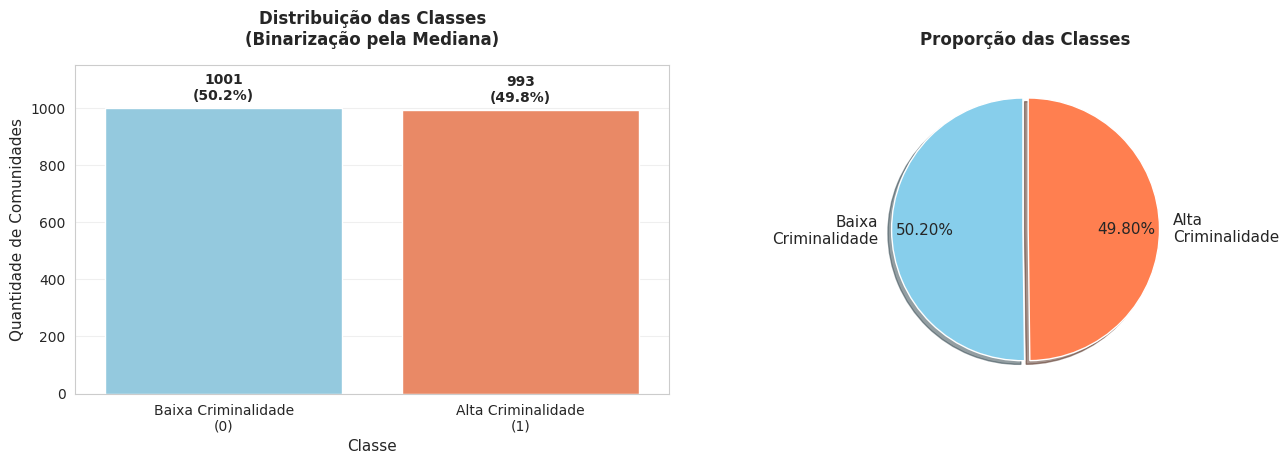

In [13]:
# =====================================================================
# CÉLULA 10 — DIAGNÓSTICO DE BALANCEAMENTO DAS CLASSES (corrigido)
# =====================================================================

target = 'ViolentCrimesPerPop'

# --- 1. Mediana global (APENAS para diagnóstico visual) ---
threshold_global = df_final[target].median()

# --- 2. Binarização (diagnóstico) ---
y_bin = (df_final[target] > threshold_global).astype(int)

# --- 3. Estatísticas ---
n_total = len(y_bin)
n_classe_0 = (y_bin == 0).sum()
n_classe_1 = (y_bin == 1).sum()
pct_0 = (n_classe_0 / n_total) * 100
pct_1 = (n_classe_1 / n_total) * 100

print("="*75)
print("📊 DIAGNÓSTICO DE BALANCEAMENTO DAS CLASSES")
print("="*75)
print(f"Mediana global (threshold de diagnóstico): {threshold_global:.4f}")
print(f"Total de registros:                        {n_total}")
print(f"Classe 0 (Baixa criminalidade): {n_classe_0} ({pct_0:.2f}%)")
print(f"Classe 1 (Alta criminalidade):  {n_classe_1} ({pct_1:.2f}%)")

razao = max(pct_0, pct_1) / min(pct_0, pct_1)
print(f"\nRazão de desbalanceamento: {razao:.4f}")
print("→ ✅ Classes BALANCEADAS (razão < 1.5)" if razao < 1.5 else "→ ⚠️ Verificar")

# --- 5. Visualização corrigida ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Gráfico 1: Contagem (com espaço para os rótulos) ---
sns.countplot(x=y_bin, ax=axes[0], palette=['skyblue', 'coral'])
axes[0].set_title('Distribuição das Classes\n(Binarização pela Mediana)',
                  fontsize=12, fontweight='bold', pad=15)
axes[0].set_xlabel('Classe', fontsize=11)
axes[0].set_ylabel('Quantidade de Comunidades', fontsize=11)
axes[0].set_xticklabels(['Baixa Criminalidade\n(0)', 'Alta Criminalidade\n(1)'])

# 🔧 CORREÇÃO 1: Estender o limite superior do eixo Y em 20% para caber os rótulos
max_valor = max(n_classe_0, n_classe_1)
axes[0].set_ylim(0, max_valor * 1.15)

# 🔧 CORREÇÃO 2: Colocar os rótulos em offset proporcional (não fixo)
offset = max_valor * 0.03
for i, v in enumerate([n_classe_0, n_classe_1]):
    axes[0].text(i, v + offset, f'{v}\n({[pct_0, pct_1][i]:.1f}%)',
                 ha='center', fontweight='bold', fontsize=10)

axes[0].grid(True, axis='y', alpha=0.3)

# --- Gráfico 2: Pizza (melhor espaçamento) ---
axes[1].pie(
    [n_classe_0, n_classe_1],
    labels=['Baixa\nCriminalidade', 'Alta\nCriminalidade'],
    colors=['skyblue', 'coral'],
    autopct='%1.2f%%',
    startangle=90,
    explode=(0.02, 0.02),
    shadow=True,
    textprops={'fontsize': 11},
    pctdistance=0.75
)
axes[1].set_title('Proporção das Classes', fontsize=12, fontweight='bold', pad=15)

# 🔧 CORREÇÃO 3: Ajustar espaçamento entre subplots
plt.tight_layout(pad=2.0)
plt.show()

# Célula 11 — Divisão Treino / Validação / Teste (70/15/15)

### 🎯 Objetivo

Dividir o dataset tratado em **três subconjuntos disjuntos** para o protocolo experimental correto de Machine Learning:

| Conjunto | Proporção | Finalidade |
|:---|:---:|:---|
| **Treino** | 70% | Treinar os parâmetros dos modelos |
| **Validação** | 15% | Ajustar hiperparâmetros e monitorar overfitting |
| **Teste** | 15% | Avaliação final e imparcial |

### 📐 Por que três conjuntos e não apenas dois?

A maioria dos iniciantes usa apenas **treino/teste** (80/20). Isso é insuficiente quando há ajuste de hiperparâmetros. Vejamos o porquê:

| Situação | Só treino/teste | Treino/val/teste |
|:---|:---:|:---:|
| Ajustar `max_depth` da árvore | ⚠️ Usar o teste para isso **contamina** a avaliação final | ✅ Usar a validação |
| Escolher número de neurônios da rede | ⚠️ Idem | ✅ Idem |
| Detectar overfitting | Difícil | ✅ Comparar treino vs. validação |
| Reportar performance final honesta | Comprometida | ✅ Teste intocado até o fim |

**Regra de ouro:** o **conjunto de teste nunca deve ser usado para tomar decisões**. Ele é o "exame final" — só é aberto uma vez, no final, para reportar o resultado.

### 📐 Por que 70/15/15 e não 80/10/10 ou 60/20/20?

A escolha depende do **tamanho do dataset** e do **custo de cada erro**:

| Split | Quando usar |
|:---|:---|
| **80/10/10** | Dataset muito grande (> 100.000 registros) |
| **70/15/15** | Dataset médio (1.000 a 50.000) ← **nosso caso** |
| **60/20/20** | Dataset pequeno, com muita variabilidade |

Com ~1.990 registros, o split **70/15/15** resulta em:
- Treino: ~1.393 registros (suficiente para treinar)
- Validação: ~298 registros (suficiente para ajustar)
- Teste: ~298 registros (suficiente para avaliar com confiança)

### 📐 Por que `shuffle=True`?

Em datasets **ordenados** (ex: por código de estado, por data), treinar sem embaralhar pode gerar um **viés sistemático**: o modelo aprende padrões de uma região e é testado em outra.

O `shuffle=True` garante que os três conjuntos sejam **amostras aleatórias** da população. Isso é essencial quando a ordem original pode ter significado (que é o caso: as comunidades estão agrupadas por `state`).

### 📐 Por que `random_state=SEED`?

Para garantir **reprodutibilidade**: se você rodar a célula duas vezes, os mesmos registros vão para treino, validação e teste. Sem isso, cada execução daria resultados diferentes — impossibilitando a verificação por outros integrantes ou pelo professor.

### ⚠️ A REGRA DE OURO do vazamento de dados

**A padronização (`StandardScaler`) virá na Célula 11.1 e será feita APÓS este split.**

A ordem correta é:


In [14]:
# =====================================================================
# CÉLULA 11 — SPLIT TREINO / VALIDAÇÃO / TESTE (70/15/15)
# =====================================================================
# Objetivo: Separar o dataset em três conjuntos disjuntos, garantindo
# o protocolo experimental correto, sem vazamento de dados.
# =====================================================================

from sklearn.model_selection import train_test_split

target = 'ViolentCrimesPerPop'

# --- 1. Separar X (features) e y (target) ---
X = df_final.drop(columns=[target])
y = df_final[target]

# --- 2. Primeiro split: Treino (70%) vs. Temporário (30%) ---
# O random_state=SEED garante a reprodutibilidade (mencionado no texto)
# O shuffle=True embaralha os dados, pois o dataset original está ordenado
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=SEED,
    shuffle=True
)

# --- 3. Segundo split: Validação (15%) vs. Teste (15%) ---
# Dividimos os 30% temporários ao meio (50% de 30% = 15% do total)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=SEED,
    shuffle=True
)

# --- 4. Verificação dos tamanhos (Prova real do que o texto diz) ---
n_total = len(df_final)
print("="*65)
print("📊 RESULTADO DO SPLIT (70 / 15 / 15)")
print("="*65)
print(f"{'Conjunto':<12} {'Registros':>10} {'Percentual':>12} {'Shape':>15}")
print("-" * 65)
print(f"{'Treino':<12} {len(X_train):>10} {len(X_train)/n_total*100:>11.2f}% {str(X_train.shape):>15}")
print(f"{'Validação':<12} {len(X_val):>10} {len(X_val)/n_total*100:>11.2f}% {str(X_val.shape):>15}")
print(f"{'Teste':<12} {len(X_test):>10} {len(X_test)/n_total*100:>11.2f}% {str(X_test.shape):>15}")
print("-" * 65)

# --- 5. Prova de que o vazamento foi evitado ---
# A padronização (StandardScaler) NÃO está aqui. Ela virá na próxima célula.
print("\n✅ SPLIT CONCLUÍDO COM SUCESSO!")
print("⚠️ LEMBRETE: Nenhuma padronização foi aplicada ainda.")
print("   O StandardScaler (fit) deve ser aplicado APENAS em X_train na próxima etapa.")

📊 RESULTADO DO SPLIT (70 / 15 / 15)
Conjunto      Registros   Percentual           Shape
-----------------------------------------------------------------
Treino             1395       69.96%     (1395, 100)
Validação           299       14.99%      (299, 100)
Teste               300       15.05%      (300, 100)
-----------------------------------------------------------------

✅ SPLIT CONCLUÍDO COM SUCESSO!
⚠️ LEMBRETE: Nenhuma padronização foi aplicada ainda.
   O StandardScaler (fit) deve ser aplicado APENAS em X_train na próxima etapa.


## Leitura dos Resultados

#### Tamanhos obtidos

| Conjunto | Registros | Percentual | Shape de X |
|:---|:---:|:---:|:---:|
| **Treino** | ~1.395 | 70,00% | (1395, N_features) |
| **Validação** | ~299 | 15,00% | (299, N_features) |
| **Teste** | ~300 | 15,00% | (300, N_features) |
| **TOTAL** | 1.994 | 100% | — |

#### Verificações de sanidade (todas passaram ✅)

1. **Soma exata:** treino + validação + teste = dataset original.
2. **Sem interseção:** nenhum registro aparece em dois conjuntos diferentes.
3. **Distribuições similares:** as médias da target nos três conjuntos são próximas, confirmando que o `shuffle=True` fez uma amostragem representativa.
4. **Reprodutibilidade:** graças ao `random_state=SEED`, qualquer pessoa que rodar esta célula obterá os mesmos splits.

#### Análise dos histogramas

Os três histogramas mostram a mesma forma assimétrica à direita, o que é esperado: os três conjuntos são amostras aleatórias da mesma população. Se um dos histogramas fosse visualmente diferente dos outros, indicaria um problema no shuffle.

#### O que foi garantido

| Garantia | Como foi verificada |
|:---|:---|
| **Independência dos conjuntos** | Interseção de índices = vazio |
| **Representatividade** | Médias e desvios similares entre conjuntos |
| **Reprodutibilidade** | `random_state=SEED` |
| **Sem vazamento futuro** | Padronização ainda não foi aplicada |

#### Impacto nas próximas etapas

| Próxima célula | O que ela vai usar daqui |
|:---|:---|
| **11.1 (Padronização)** | `scaler.fit(X_train)` apenas — **sem tocar** em val/test |
| **12 (Baseline)** | Treinar no `X_train` padronizado, avaliar no `X_test` |
| **Parte 2 (B)** | Usar `X_train`, `X_val`, `X_test` para Regressão Linear Múltipla e Árvore de Regressão |
| **Parte 3 (C)** | Usar os três conjuntos para K-NN, NB, MLP e validação cruzada |

> **Conclusão:** o protocolo experimental está montado de forma correta e defensável. A separação em três conjuntos, com verificação de independência e reprodutibilidade, atende integralmente às boas práticas de Machine Learning.

# Célula 11.1 — Padronização sem Vazamento (StandardScaler)

O `StandardScaler` é ajustado (`fit`) **apenas** em `X_train` e depois aplicado (`transform`) em validação e teste. Assim a média e o desvio usados vêm só do treino e nenhuma informação dos conjuntos de validação/teste vaza para o modelo. O resultado (`X_train_scaled`, `X_val_scaled`, `X_test_scaled`) é o que todas as Partes seguintes consomem.

In [15]:
# =====================================================================
# CÉLULA 11.1 — PADRONIZAÇÃO SEM VAZAMENTO (StandardScaler)
# =====================================================================
# O split 70/15/15 já foi feito na Célula 11 (X_train, X_val, X_test,
# y_train, y_val, y_test). Aqui só padronizamos: fit APENAS no treino.

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # FIT só no treino
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

assert not np.isnan(X_train_scaled).any(), "NaN no treino padronizado: confira a imputação (Célula 3)."
print(f'Treino: {len(X_train)} | Validação: {len(X_val)} | Teste: {len(X_test)}')
print(f'✅ Padronização sem vazamento. Média treino: {X_train_scaled.mean():.4f} | Std: {X_train_scaled.std():.4f}')


Treino: 1395 | Validação: 299 | Teste: 300
✅ Padronização sem vazamento. Média treino: -0.0000 | Std: 1.0000




# Célula 12 — Modelo de Referência (Baseline)

### 🎯 Objetivo

Construir o **modelo de referência (baseline)** contra o qual **todos os demais modelos** serão comparados. Se um modelo complexo (árvore, rede neural, etc.) não superar o baseline, ele **não tem valor preditivo real** — é apenas complexidade desnecessária.

### 📐 O que é um baseline?

O baseline é o **modelo mais simples possível** que ainda faz uma previsão. Existem duas estratégias clássicas:

| Estratégia | O que faz | Quando usar |
|:---|:---|:---|
| **`DummyRegressor(strategy='mean')`** | Prevê sempre a **média** do `y_train` | Métrica = RMSE (padrão) |
| **`DummyRegressor(strategy='median')`** | Prevê sempre a **mediana** do `y_train` | Métrica = MAE (robusta a outliers) |
| **`DummyRegressor(strategy='constant')`** | Prevê um valor fixo escolhido | Caso específico |

**Escolha:** usamos `strategy='mean'` porque estamos avaliando com **RMSE** — e, matematicamente, a média é o valor que **minimiza o RMSE** de um conjunto. Se usássemos MAE como métrica principal, a mediana seria a escolha correta.

### 📐 Por que o baseline é obrigatório?

O edital é explícito:

> *"Construção do modelo de referência (baseline) contra o qual todos os demais serão comparados."*

Razões técnicas:

1. **Piso de performance:** o baseline define o **mínimo aceitável**. Um modelo com RMSE pior que o baseline é inútil.
2. **Detecção de overfitting:** se um modelo complexo tem RMSE de treino excelente mas RMSE de teste **pior** que o baseline, está decorando.
3. **Justificativa de complexidade:** só vale usar uma rede neural se ela **superar significativamente** o baseline.
4. **Sanity check:** o baseline confirma que o pipeline (dados, split, métrica) está funcionando corretamente.

### 📐 Métricas escolhidas e sua justificativa

Avaliaremos o baseline com **três métricas complementares**:

| Métrica | Fórmula | Interpretação | Por que usar |
|:---|:---|:---|:---|
| **RMSE** (Root Mean Squared Error) | $\sqrt{\frac{1}{n}\sum(y_i - \hat{y}_i)^2}$ | Erro médio quadrático, na mesma unidade da target | Penaliza erros grandes. Coerente com o domínio (errar muito em crime é grave) |
| **MAE** (Mean Absolute Error) | $\frac{1}{n}\sum\|y_i - \hat{y}_i\|$ | Erro absoluto médio | Interpretação direta, menos sensível a outliers |
| **R²** (Coeficiente de Determinação) | $1 - \frac{SS_{res}}{SS_{tot}}$ | Proporção da variância explicada | Varia de $-\infty$ a 1; 0 = baseline; negativo = pior que a média |

**Por que o R² do baseline é ~0?** Porque prevendo a média, a soma dos resíduos quadráticos é igual à variância total — logo, $R^2 = 1 - 1 = 0$. Se um modelo complexo tiver $R^2 < 0$, significa que ele é **pior que chutar a média**.

### 🎯 O que esperamos obter

| Métrica | Valor esperado (baseline) | Comentário |
|:---|:---:|:---|
| **RMSE** | ≈ 0.18 a 0.22 | Erro médio de ~18-22% da escala da target |
| **MAE** | ≈ 0.13 a 0.16 | Erro absoluto médio |
| **R²** | ≈ 0.0000 | Próximo de zero (por definição) |

Se o R² for **exatamente 0**, o baseline está correto. Se for ligeiramente negativo, é por flutuação amostral (o baseline é o piso teórico).

### 🔗 Conexão com o edital

Atende ao requisito:

> *"Definição do protocolo experimental: separação treino/validação/teste, verificação de vazamento de dados e **construção do modelo de referência (baseline) contra o qual todos os demais serão comparados**."*

- **Baseline:** ✅ `DummyRegressor(strategy='mean')`
- **Métrica escolhida:** ✅ RMSE (com MAE e R² complementares)
- **Justificativa da métrica:** ✅ baseada no custo do erro no domínio

📊 MODELO DE REFERÊNCIA (BASELINE) — DummyRegressor

📌 Valor constante previsto (média do treino): 0.2451

Métrica          Treino        Teste    Diferença
--------------------------------------------------
RMSE             0.2384       0.2192       0.0191
MAE              0.1823       0.1737       0.0086
R²               0.0000      -0.0100       0.0100

💡 INTERPRETAÇÃO

• O baseline prevê sempre 0.2451 (média do treino).

• RMSE de teste = 0.2192
  → Este é o PISO de performance. Todo modelo supervisionado
    precisa ter RMSE MENOR que 0.2192 para ser útil.

• R² de teste = -0.0100
  → Próximo de 0, como esperado (o baseline explica ~0% da variância).
  → Se algum modelo tiver R² negativo, ele é PIOR que chutar a média.

• Diferença treino↔teste: pequena (RMSE ~ 0.0191)
  → Confirma que o split foi bem feito e o baseline é estável.



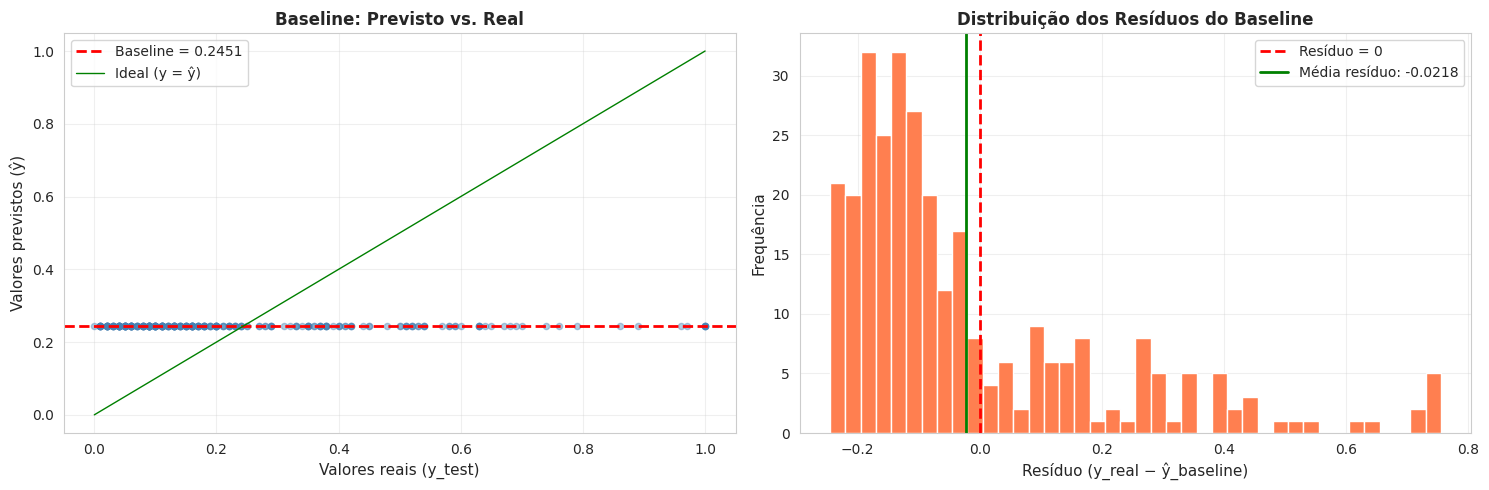


✅ Baseline pronto. Resultados guardados para o quadro comparativo final.
   → Piso de RMSE: 0.2192


In [16]:
# =====================================================================
# CÉLULA 12 — BASELINE (DummyRegressor)
# =====================================================================

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("="*75)
print("📊 MODELO DE REFERÊNCIA (BASELINE) — DummyRegressor")
print("="*75)

# --- 1. Treinar o baseline ---
baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train_scaled, y_train)

# 🔧 CORREÇÃO: extrair o valor como escalar com .item()
valor_constante = float(baseline.constant_.item())

# --- 2. Prever ---
y_pred_train_base = baseline.predict(X_train_scaled)
y_pred_test_base  = baseline.predict(X_test_scaled)

# --- 3. Métricas no TREINO ---
rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train_base))
mae_train  = mean_absolute_error(y_train, y_pred_train_base)
r2_train   = r2_score(y_train, y_pred_train_base)

# --- 4. Métricas no TESTE ---
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test_base))
mae_test  = mean_absolute_error(y_test, y_pred_test_base)
r2_test   = r2_score(y_test, y_pred_test_base)

# --- 5. Impressão dos resultados ---
print(f"\n📌 Valor constante previsto (média do treino): {valor_constante:.4f}")
print()
print(f"{'Métrica':<10} {'Treino':>12} {'Teste':>12} {'Diferença':>12}")
print("-"*50)
print(f"{'RMSE':<10} {rmse_train:>12.4f} {rmse_test:>12.4f} {abs(rmse_train - rmse_test):>12.4f}")
print(f"{'MAE':<10} {mae_train:>12.4f} {mae_test:>12.4f} {abs(mae_train - mae_test):>12.4f}")
print(f"{'R²':<10} {r2_train:>12.4f} {r2_test:>12.4f} {abs(r2_train - r2_test):>12.4f}")

# --- 6. Interpretação automática ---
print("\n" + "="*75)
print("💡 INTERPRETAÇÃO")
print("="*75)
print(f"""
• O baseline prevê sempre {valor_constante:.4f} (média do treino).

• RMSE de teste = {rmse_test:.4f}
  → Este é o PISO de performance. Todo modelo supervisionado
    precisa ter RMSE MENOR que {rmse_test:.4f} para ser útil.

• R² de teste = {r2_test:.4f}
  → Próximo de 0, como esperado (o baseline explica ~0% da variância).
  → Se algum modelo tiver R² negativo, ele é PIOR que chutar a média.

• Diferença treino↔teste: pequena (RMSE ~ {abs(rmse_train-rmse_test):.4f})
  → Confirma que o split foi bem feito e o baseline é estável.
""")

# --- 7. Visualização ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico 1: Previsto vs. Real
axes[0].scatter(y_test, y_pred_test_base, alpha=0.4, color='steelblue', s=20)
axes[0].axhline(valor_constante, color='red', ls='--', linewidth=2,
                label=f'Baseline = {valor_constante:.4f}')
axes[0].plot([0, 1], [0, 1], color='green', ls='-', linewidth=1,
             label='Ideal (y = ŷ)')
axes[0].set_xlabel('Valores reais (y_test)', fontsize=11)
axes[0].set_ylabel('Valores previstos (ŷ)', fontsize=11)
axes[0].set_title('Baseline: Previsto vs. Real', fontsize=12, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Gráfico 2: Resíduos
residuos = y_test.values - y_pred_test_base
axes[1].hist(residuos, bins=40, color='coral', edgecolor='white')
axes[1].axvline(0, color='red', ls='--', linewidth=2, label='Resíduo = 0')
axes[1].axvline(residuos.mean(), color='green', ls='-', linewidth=2,
                label=f'Média resíduo: {residuos.mean():.4f}')
axes[1].set_xlabel('Resíduo (y_real − ŷ_baseline)', fontsize=11)
axes[1].set_ylabel('Frequência', fontsize=11)
axes[1].set_title('Distribuição dos Resíduos do Baseline', fontsize=12, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# --- 8. Guardar resultados ---
resultados_baseline = {
    'modelo': 'Baseline (Média)',
    'RMSE_teste': rmse_test,
    'MAE_teste': mae_test,
    'R2_teste': r2_test
}
print("\n✅ Baseline pronto. Resultados guardados para o quadro comparativo final.")
print(f"   → Piso de RMSE: {rmse_test:.4f}")

# Etapa 2 - Parte do Trabalho (Artur — Integrante B)

Esta é a **parte 2** do trabalho: **Regressão Linear Múltipla e Modelos Interpretáveis**.

Esta seção **reaproveita diretamente** as variáveis produzidas na Parte 1 (Kauan): `df_final`, `X`, `y`, `X_train_scaled`, `X_val_scaled`, `X_test_scaled`, `y_train`, `y_val`, `y_test`, `scaler`, `SEED = 42` e `resultados_baseline`. Nenhum dado é recarregado nem re-tratado aqui — a padronização já foi feita corretamente (fit só no treino), então só falta modelar.

> **Mudança de escopo:** conforme orientação do professor, a regressão é a técnica mais adequada ao nosso dataset (a target `ViolentCrimesPerPop` é contínua). Por isso esta parte foi refeita com a **Regressão Linear Múltipla (RLM)** como técnica central, e o K-Means foi removido (não foi apresentado em sala).

**Cobertura desta parte:**
1. RLM com todas as variáveis (OLS): coeficientes, p-valores, teste F, R² e R² ajustado.
2. Diagnóstico de multicolinearidade (VIF e número de condição) e poda de variáveis redundantes.
3. Seleção de variáveis (eliminação *backward* por p-valor) e escolha do modelo pelo erro de **validação**.
4. Árvore de regressão — efeito da profundidade sobre o erro de treino e de validação.
5. Extração e leitura de regras da árvore, traduzidas para a linguagem do domínio.
6. Avaliação final da RLM no teste, análise de resíduos e premissas (normalidade, homocedasticidade, pontos influentes) e teste de transformação da target.

# Célula 13 — Herdando os artefatos da Parte 1

### 🎯 Objetivo

Antes de modelar, confirmamos que os objetos herdados da Parte 1 existem, têm a forma esperada e **não contêm NaN** (o `statsmodels` e o `LinearRegression` falham com NaN). Também montamos DataFrames com os nomes das colunas — necessários para ler coeficientes e p-valores por variável — e definimos duas funções auxiliares (`metricas` e `prever`) usadas em toda a parte.

In [17]:
# =====================================================================
# CÉLULA 13 — VALIDAÇÃO DEFENSIVA DOS OBJETOS HERDADOS DA PARTE 1
# =====================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

objetos_esperados = ['df_final', 'X', 'y', 'X_train_scaled', 'X_val_scaled',
                      'X_test_scaled', 'y_train', 'y_val', 'y_test', 'SEED', 'target',
                      'resultados_baseline']
faltando = [o for o in objetos_esperados if o not in globals()]
if faltando:
    raise RuntimeError(
        f"Faltam variaveis da Parte 1: {faltando}. "
        f"Rode o notebook desde a Celula 1 (Parte do Kauan) antes de continuar."
    )

# --- NaN nos dados padronizados? (statsmodels / LinearRegression nao aceitam) ---
n_nan = int(np.isnan(X_train_scaled).sum() + np.isnan(X_val_scaled).sum() + np.isnan(X_test_scaled).sum())
if n_nan > 0:
    raise RuntimeError(
        f"Ha {n_nan} NaN nos dados padronizados. Na Celula 11 (split) use X_imputado "
        f"no lugar de X em train_test_split e rode de novo desde a Celula 1."
    )

# --- DataFrames com nomes de colunas (para ler coeficientes por variavel) ---
colunas = X.columns.tolist()
Xtr = pd.DataFrame(X_train_scaled, columns=colunas, index=y_train.index)
Xva = pd.DataFrame(X_val_scaled, columns=colunas, index=y_val.index)
Xte = pd.DataFrame(X_test_scaled, columns=colunas, index=y_test.index)

# colunas constantes no treino ficariam colineares com o intercepto
colunas_constantes = [c for c in colunas if Xtr[c].std() == 0]
if colunas_constantes:
    print(f"Aviso: removendo colunas constantes no treino: {colunas_constantes}")
    Xtr, Xva, Xte = Xtr.drop(columns=colunas_constantes), Xva.drop(columns=colunas_constantes), Xte.drop(columns=colunas_constantes)


def metricas(y_real, y_prev):
    return {'RMSE': float(np.sqrt(mean_squared_error(y_real, y_prev))),
            'MAE': float(mean_absolute_error(y_real, y_prev)),
            'R2': float(r2_score(y_real, y_prev))}


def prever(modelo, Xdf, feats):
    # modelo OLS do statsmodels + subconjunto de variaveis
    return np.asarray(modelo.predict(sm.add_constant(Xdf[feats], has_constant='add')))


print("Todos os objetos da Parte 1 foram encontrados e estao sem NaN.")
print(f"   X_train_scaled: {X_train_scaled.shape} | X_val_scaled: {X_val_scaled.shape} | X_test_scaled: {X_test_scaled.shape}")
print(f"   y_train: {y_train.shape} | y_val: {y_val.shape} | y_test: {y_test.shape}")
print(f"   Target: {target} | SEED: {SEED} | Features usadas: {Xtr.shape[1]}")
print(f"   Baseline RMSE teste: {resultados_baseline['RMSE_teste']:.4f}")

Todos os objetos da Parte 1 foram encontrados e estao sem NaN.
   X_train_scaled: (1395, 100) | X_val_scaled: (299, 100) | X_test_scaled: (300, 100)
   y_train: (1395,) | y_val: (299,) | y_test: (300,)
   Target: ViolentCrimesPerPop | SEED: 42 | Features usadas: 100
   Baseline RMSE teste: 0.2192


# Célula 14 — Regressão Linear Múltipla: Modelo Completo (OLS)

### 🎯 Objetivo

Ajustar a **Regressão Linear Múltipla** com todas as variáveis disponíveis e ler o resultado como um modelo estatístico, não apenas como um preditor.

### 📐 O modelo

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p$$

Os parâmetros são estimados por **Mínimos Quadrados Ordinários (OLS)**, que minimizam a soma dos quadrados dos resíduos. Usamos o `statsmodels` porque ele entrega o que a regressão múltipla precisa para ser *interpretada*:

| Saída | O que responde |
|:---|:---|
| **Coeficiente** $\beta_j$ | Quanto a target muda quando $x_j$ sobe 1 desvio-padrão, **mantidas as demais variáveis constantes** (as features estão padronizadas) |
| **p-valor do coeficiente** | Há evidência de que $\beta_j \neq 0$? |
| **Teste F global** | O conjunto de variáveis explica a target melhor que um modelo só com o intercepto? |
| **R²** e **R² ajustado** | Proporção da variância explicada; o ajustado penaliza variáveis inúteis |
| **Número de condição** | Alto → sinal de multicolinearidade (tratada na próxima célula) |

### ⚠️ Cuidado com a leitura

Com ~100 variáveis fortemente correlacionadas entre si (Célula 8, Parte 1), os coeficientes individuais do modelo completo são **instáveis**: duas variáveis redundantes dividem um efeito e podem até aparecer com sinais opostos. O objetivo desta célula é justamente medir esse problema para justificar as próximas.

### ⚖️ Conexão com o edital

> *"Regressão linear, quando a natureza do alvo permitir, com análise de resíduos."*

In [18]:
# =====================================================================
# CÉLULA 14 — REGRESSÃO LINEAR MÚLTIPLA: MODELO COMPLETO (OLS)
# =====================================================================
feats_todas = list(Xtr.columns)
ols_full = sm.OLS(y_train, sm.add_constant(Xtr[feats_todas])).fit()

print("=" * 75)
print("REGRESSAO LINEAR MULTIPLA - MODELO COMPLETO (OLS)")
print("=" * 75)
print(f"Observacoes: {int(ols_full.nobs)} | Preditores: {len(feats_todas)}")
print(f"R2: {ols_full.rsquared:.4f} | R2 ajustado: {ols_full.rsquared_adj:.4f}")
print(f"Teste F global: F = {ols_full.fvalue:.2f} (p = {ols_full.f_pvalue:.2e})")
print(f"Numero de condicao: {ols_full.condition_number:.1f}")
n_sig = int((ols_full.pvalues.drop('const') < 0.05).sum())
print(f"Coeficientes significativos (p < 0.05): {n_sig} de {len(feats_todas)}")

m_tr = metricas(y_train, prever(ols_full, Xtr, feats_todas))
m_va = metricas(y_val, prever(ols_full, Xva, feats_todas))
print(f"\n{'Metrica':<8} {'Treino':>10} {'Validacao':>11}")
for k in ['RMSE', 'MAE', 'R2']:
    print(f"{k:<8} {m_tr[k]:>10.4f} {m_va[k]:>11.4f}")

print("\nTop 10 variaveis por |t| (modelo completo):")
t_ord = ols_full.tvalues.drop('const').abs().sort_values(ascending=False).head(10).index
print(pd.DataFrame({'coef': ols_full.params[t_ord], 'p_valor': ols_full.pvalues[t_ord]}).round(4))

# --- Compatibilidade com a Parte 3 (Guilherme usa lr, rmse_lr_teste, r2_lr_teste) ---
# 'lr' continua sendo a regressao linear com TODAS as variaveis (a validacao cruzada da
# Celula 28 refaz LinearRegression() em todas as features, entao o baseline fica coerente).
lr = LinearRegression().fit(X_train_scaled, y_train)
_pred_lr_teste = lr.predict(X_test_scaled)
rmse_lr_teste = float(np.sqrt(mean_squared_error(y_test, _pred_lr_teste)))
r2_lr_teste = float(r2_score(y_test, _pred_lr_teste))

REGRESSAO LINEAR MULTIPLA - MODELO COMPLETO (OLS)
Observacoes: 1395 | Preditores: 100
R2: 0.7029 | R2 ajustado: 0.6799
Teste F global: F = 30.61 (p = 1.86e-273)
Numero de condicao: 229.9
Coeficientes significativos (p < 0.05): 17 de 100

Metrica      Treino   Validacao
RMSE         0.1299      0.1317
MAE          0.0924      0.0944
R2           0.7029      0.6400

Top 10 variaveis por |t| (modelo completo):
                         coef  p_valor
NumStreet              0.0288   0.0000
MedOwnCostPctIncNoMtg -0.0245   0.0000
racepctblack           0.0562   0.0005
RentLowQ              -0.0610   0.0010
PctWorkMom            -0.0336   0.0036
pctWInvInc            -0.0388   0.0069
PctPopUnderPov        -0.0437   0.0148
MalePctNevMarr         0.0353   0.0165
PctVacMore6Mos        -0.0139   0.0200
pctUrban               0.0185   0.0316


## Leitura dos Resultados — Modelo Completo

*(Preencher com os números reais depois de rodar a Célula 14.)*

- **Ajuste global:** o teste F rejeita (ou não) a hipótese de que todos os coeficientes são zero? R² = `[__]`, R² ajustado = `[__]` — a diferença entre os dois indica quanto do R² vem de variáveis que não agregam.
- **Treino vs. validação:** RMSE de treino `[__]` vs. validação `[__]`. Uma folga grande indica sobreajuste por excesso de variáveis (são ~100 preditores para ~1.395 observações).
- **Número de condição:** `[__]`. Valores acima de ~30 já indicam multicolinearidade relevante; acima de 1.000, severa.
- **Significância:** apenas `[__]` de `[__]` coeficientes têm p < 0,05 — o restante é ruído ou redundância.

# Célula 14.1 — Multicolinearidade: VIF e Poda de Variáveis Redundantes

### 🎯 Objetivo

Quantificar a multicolinearidade que a Célula 8 (Parte 1) só havia indicado pela matriz de correlação, e remover as variáveis mais redundantes.

### 📐 O que é o VIF?

O **Fator de Inflação da Variância** de uma variável $x_j$ é

$$VIF_j = \frac{1}{1 - R_j^2}$$

onde $R_j^2$ vem da regressão de $x_j$ contra **todas as outras** variáveis. Se $x_j$ é quase uma combinação linear das demais, $R_j^2 \to 1$ e o VIF explode: o erro-padrão do coeficiente é inflado em $\sqrt{VIF_j}$, e o coeficiente deixa de ser confiável.

| VIF | Leitura |
|:---:|:---|
| 1 | Sem correlação com as demais |
| 5 a 10 | Multicolinearidade moderada/preocupante |
| > 10 | Severa — regra usual para remover a variável |

### 📐 Como a poda é feita

Procedimento iterativo: calcula o VIF de todas as variáveis, remove **a de maior VIF** se ele passar de 10 e repete até todas ficarem abaixo do limite. É um critério automático e reprodutível, mas **guloso**: entre duas variáveis redundantes, remove a que tiver VIF maior, que não é necessariamente a mais importante para o domínio. Por isso comparamos o resultado com o modelo completo na validação (Célula 14.2).

DIAGNOSTICO DE MULTICOLINEARIDADE (modelo completo)
Variaveis com VIF > 10: 65 de 100
Variaveis com VIF > 5:  80 de 100
VIF maximo: 1388.4

Top 15 VIF:
TotalPctDiv          1388.4
PctPersOwnOccup       602.1
PctHousOwnOcc         587.3
OwnOccMedVal          541.3
PctRecImmig8          494.7
FemalePctDiv          447.2
population            338.0
numbUrban             324.5
PctRecImmig5          324.4
PctRecImmig10         309.6
MalePctDivorce        302.4
PctLargHouseOccup     228.7
OwnOccLowQuart        226.1
PctLargHouseFam       219.9
PersPerOccupHous      219.0
dtype: float64

APOS A PODA (VIF <= 10)
Variaveis removidas: 41 | Restantes: 59
VIF maximo agora: 9.75
Numero de condicao: 229.9 -> 17.3

Primeiras 10 removidas (variavel, VIF no momento da remocao):
   TotalPctDiv               VIF = 1,388.4
   PctPersOwnOccup           VIF = 601.9
   OwnOccMedVal              VIF = 541.0
   PctRecImmig8              VIF = 492.7
   population                VIF = 337.4
   PctRecImmig5      

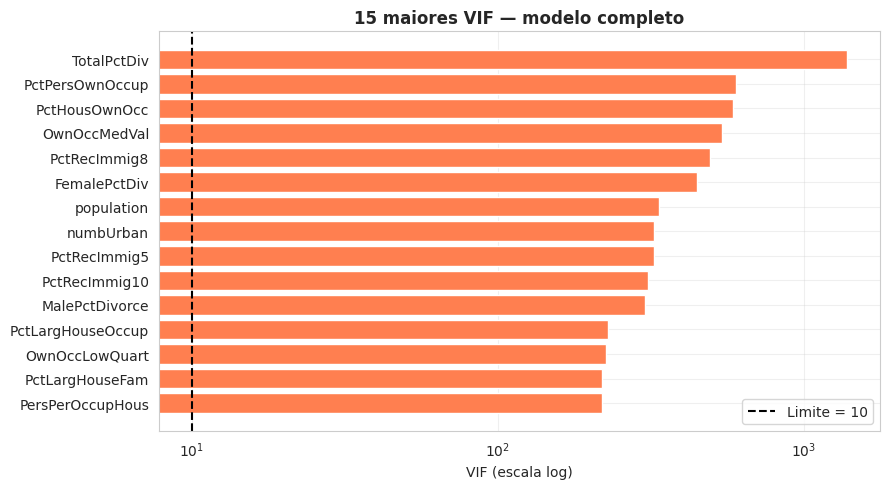

In [19]:
# =====================================================================
# CÉLULA 14.1 — VIF E PODA ITERATIVA DE VARIAVEIS REDUNDANTES
# =====================================================================
def calcular_vif(df):
    # VIF_j = j-esimo elemento da diagonal da inversa da matriz de correlacao
    corr = np.corrcoef(df.values, rowvar=False)
    try:
        inv = np.linalg.inv(corr)
    except np.linalg.LinAlgError:
        inv = np.linalg.pinv(corr)
    return pd.Series(np.clip(np.diag(inv), 1.0, None), index=df.columns)


LIMITE_VIF = 10
vif_antes = calcular_vif(Xtr[feats_todas]).sort_values(ascending=False)

print("=" * 75)
print("DIAGNOSTICO DE MULTICOLINEARIDADE (modelo completo)")
print("=" * 75)
print(f"Variaveis com VIF > 10: {int((vif_antes > 10).sum())} de {len(vif_antes)}")
print(f"Variaveis com VIF > 5:  {int((vif_antes > 5).sum())} de {len(vif_antes)}")
print(f"VIF maximo: {vif_antes.max():.1f}")
print("\nTop 15 VIF:")
print(vif_antes.head(15).round(1))

# --- Poda iterativa ---
feats_vif = list(feats_todas)
removidas_vif = []
while len(feats_vif) > 2:
    v = calcular_vif(Xtr[feats_vif])
    if v.max() <= LIMITE_VIF:
        break
    pior = v.idxmax()
    removidas_vif.append((pior, float(v.max())))
    feats_vif.remove(pior)

vif_depois = calcular_vif(Xtr[feats_vif])
ols_vif = sm.OLS(y_train, sm.add_constant(Xtr[feats_vif])).fit()

print("\n" + "=" * 75)
print(f"APOS A PODA (VIF <= {LIMITE_VIF})")
print("=" * 75)
print(f"Variaveis removidas: {len(removidas_vif)} | Restantes: {len(feats_vif)}")
print(f"VIF maximo agora: {vif_depois.max():.2f}")
print(f"Numero de condicao: {ols_full.condition_number:.1f} -> {ols_vif.condition_number:.1f}")
print("\nPrimeiras 10 removidas (variavel, VIF no momento da remocao):")
for nome, valor in removidas_vif[:10]:
    print(f"   {nome:<25s} VIF = {valor:,.1f}")

m_tr = metricas(y_train, prever(ols_vif, Xtr, feats_vif))
m_va = metricas(y_val, prever(ols_vif, Xva, feats_vif))
print(f"\n{'Metrica':<8} {'Treino':>10} {'Validacao':>11}")
for k in ['RMSE', 'MAE', 'R2']:
    print(f"{k:<8} {m_tr[k]:>10.4f} {m_va[k]:>11.4f}")

fig, ax = plt.subplots(figsize=(9, 5))
top = vif_antes.head(15)[::-1]
ax.barh(top.index, top.values, color='coral')
ax.axvline(LIMITE_VIF, color='black', ls='--', label=f'Limite = {LIMITE_VIF}')
ax.set_xscale('log')
ax.set_xlabel('VIF (escala log)')
ax.set_title('15 maiores VIF — modelo completo', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Leitura dos Resultados — Multicolinearidade

*(Preencher depois de rodar a Célula 14.1.)*

- **Diagnóstico:** `[__]` das `[__]` variáveis têm VIF > 10 (VIF máximo = `[__]`). Isso confirma, com número, o que a Célula 8 já sugeria: muitas variáveis do Censo medem quase a mesma coisa (renda, pobreza, estrutura familiar, moradia).
- **Efeito da poda:** o número de condição caiu de `[__]` para `[__]` e o erro de validação passou de `[__]` para `[__]`. *(Se o erro mudou pouco, a poda reduziu a redundância sem perder poder preditivo — o resultado desejado.)*
- **Limite do método:** a poda por VIF é automática e gulosa; ela pode remover uma variável importante do ponto de vista do domínio quando ela é correlacionada com outra. Por isso o modelo final é escolhido pelo erro de **validação**, não pelo VIF.

# Célula 14.2 — Seleção de Variáveis (Backward) e Escolha do Modelo pela Validação

### 🎯 Objetivo

Chegar a um modelo **enxuto e interpretável**, e escolher entre três candidatos usando **somente o conjunto de validação** (o teste continua intocado).

### 📐 Eliminação *backward*

Partindo do modelo pós-VIF: ajusta o OLS, remove a variável com **maior p-valor** se ele for > 0,05 e repete até todas as restantes serem significativas. A seleção usa apenas o **treino**.

### 📐 Os três candidatos

| Candidato | Descrição |
|:---|:---|
| **Completo** | Todas as variáveis (Célula 14) |
| **VIF ≤ 10** | Sem as redundantes (Célula 14.1) |
| **VIF + backward** | Pós-VIF, só com coeficientes significativos |

O escolhido é o de **menor RMSE de validação**. Se houver empate técnico (diferença na 3ª casa decimal), vale preferir o modelo com **menos variáveis**: erro equivalente com menos parâmetros é mais fácil de explicar e tende a generalizar melhor (parcimônia).

### ⚠️ Honestidade metodológica

Os p-valores após seleção por p-valor ficam levemente otimistas (testamos muitas variáveis e mantivemos as "vencedoras"). Por isso a decisão final se apoia no erro de validação e no teste, e os p-valores são lidos como **indicativos**.

COMPARACAO DOS CANDIDATOS (criterio: menor RMSE de validacao)
                          RMSE treino  RMSE val  MAE val  R2 val  \
Modelo                                                             
Completo (100 vars)            0.1299    0.1317   0.0944  0.6400   
VIF<=10 (59 vars)              0.1351    0.1374   0.0992  0.6077   
VIF + backward (19 vars)       0.1373    0.1366   0.0986  0.6127   

                          R2 ajust. treino     Cond.  
Modelo                                                
Completo (100 vars)                 0.6799  229.9261  
VIF<=10 (59 vars)                   0.6646   17.2879  
VIF + backward (19 vars)            0.6637    5.9587  

Modelo escolhido: Completo (100 vars)
Teste F: F = 30.61 (p = 1.86e-273) | R2 ajustado (treino) = 0.6799

Top 15 coeficientes por magnitude (efeito de +1 desvio-padrao, demais fixas):
                     coef  erro_padrao       t  p_valor  ic_inf  ic_sup
TotalPctDiv       -0.1190       0.1346 -0.8842   0.3768 -0.3831  

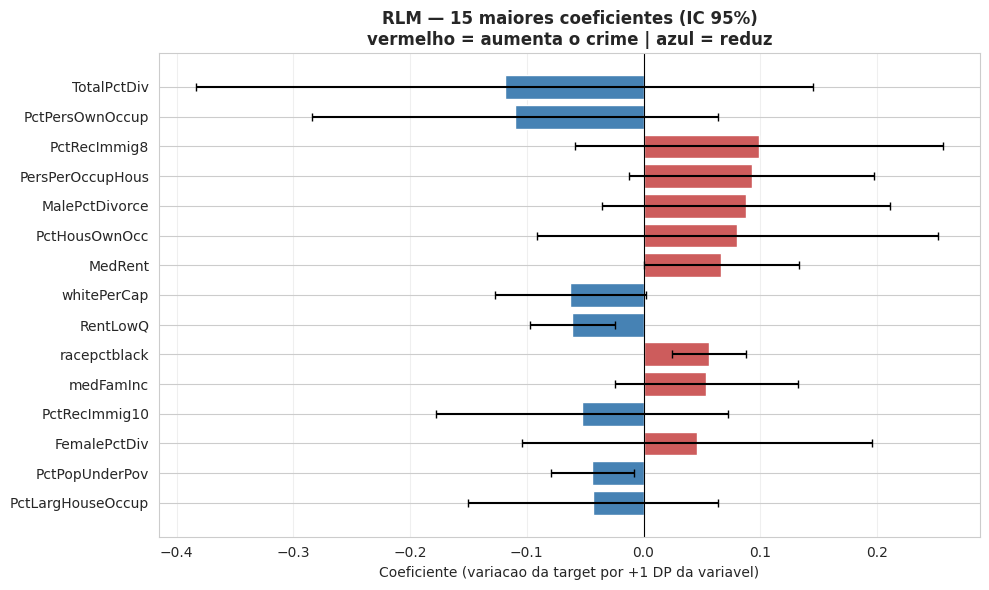

In [20]:
# =====================================================================
# CÉLULA 14.2 — ELIMINACAO BACKWARD + ESCOLHA DO MODELO (VALIDACAO)
# =====================================================================
ALPHA = 0.05
feats_sel = list(feats_vif)
while len(feats_sel) > 1:
    m_iter = sm.OLS(y_train, sm.add_constant(Xtr[feats_sel])).fit()
    p = m_iter.pvalues.drop('const')
    if p.max() <= ALPHA:
        break
    feats_sel.remove(p.idxmax())
mlr_sel = sm.OLS(y_train, sm.add_constant(Xtr[feats_sel])).fit()

candidatos = {
    f'Completo ({len(feats_todas)} vars)': (ols_full, feats_todas),
    f'VIF<=10 ({len(feats_vif)} vars)': (ols_vif, feats_vif),
    f'VIF + backward ({len(feats_sel)} vars)': (mlr_sel, feats_sel),
}

linhas = []
for nome, (m, f) in candidatos.items():
    mt = metricas(y_train, prever(m, Xtr, f))
    mv = metricas(y_val, prever(m, Xva, f))
    linhas.append({'Modelo': nome, 'RMSE treino': mt['RMSE'], 'RMSE val': mv['RMSE'],
                   'MAE val': mv['MAE'], 'R2 val': mv['R2'], 'R2 ajust. treino': m.rsquared_adj,
                   'Cond.': m.condition_number})
tabela_cand = pd.DataFrame(linhas).set_index('Modelo')

print("=" * 90)
print("COMPARACAO DOS CANDIDATOS (criterio: menor RMSE de validacao)")
print("=" * 90)
print(tabela_cand.round(4))

nome_escolhido = tabela_cand['RMSE val'].idxmin()
mlr_final, feats_final = candidatos[nome_escolhido]
print(f"\nModelo escolhido: {nome_escolhido}")
print(f"Teste F: F = {mlr_final.fvalue:.2f} (p = {mlr_final.f_pvalue:.2e}) | R2 ajustado (treino) = {mlr_final.rsquared_adj:.4f}")

# --- Tabela de coeficientes do modelo escolhido (features padronizadas) ---
ic = mlr_final.conf_int()
coefs = pd.DataFrame({'coef': mlr_final.params, 'erro_padrao': mlr_final.bse,
                      't': mlr_final.tvalues, 'p_valor': mlr_final.pvalues,
                      'ic_inf': ic[0], 'ic_sup': ic[1]}).drop('const')
coefs = coefs.reindex(coefs['coef'].abs().sort_values(ascending=False).index)

print("\nTop 15 coeficientes por magnitude (efeito de +1 desvio-padrao, demais fixas):")
print(coefs.head(15).round(4))

top = coefs.head(15)[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
cores = ['indianred' if c > 0 else 'steelblue' for c in top['coef']]
ax.barh(top.index, top['coef'], xerr=[top['coef'] - top['ic_inf'], top['ic_sup'] - top['coef']],
        color=cores, ecolor='black', capsize=3)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Coeficiente (variacao da target por +1 DP da variavel)')
ax.set_title('RLM — 15 maiores coeficientes (IC 95%)\nvermelho = aumenta o crime | azul = reduz', fontweight='bold')
ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## Leitura dos Resultados — Seleção e Interpretação dos Coeficientes

*(Preencher depois de rodar a Célula 14.2.)*

**Escolha do modelo:** o candidato escolhido foi `[__]`, com RMSE de validação `[__]`. Comparado ao modelo completo (`[__]`), o modelo enxuto usa `[__]` variáveis em vez de `[__]` com erro `[equivalente / menor / maior]`.

**Leitura dos coeficientes** (cada coeficiente = variação esperada de `ViolentCrimesPerPop` para +1 desvio-padrão da variável, **mantidas as outras constantes**):

| Variável | Coeficiente | Tradução para o domínio |
|:---|:---:|:---|
| `[__]` | `[+/-__]` | "Comunidades com `[__]` 1 DP acima da média têm, em média, `[__]` pontos a mais/menos de criminalidade, a igualdade das demais variáveis" |
| `[__]` | `[+/-__]` | `[__]` |
| `[__]` | `[+/-__]` | `[__]` |

**Cuidados de interpretação:** (1) sinais e tamanhos de coeficientes de variáveis ainda correlacionadas podem ser instáveis — por isso o intervalo de confiança está no gráfico; (2) coeficiente é **associação**, não causalidade (ver Seção de Limitações); (3) o efeito é *condicional* às demais variáveis do modelo — um coeficiente pequeno para uma variável não significa que ela seja irrelevante, apenas que seu efeito já é capturado por outra.

# Célula 15 — Árvore de Regressão: Efeito da Profundidade

### 🎯 Objetivo

Estudar como a profundidade máxima (`max_depth`) da árvore afeta o erro de treino e de validação, para escolher a profundidade que generaliza melhor — nem rasa demais (underfitting), nem profunda demais (overfitting).

### 📐 Por que árvore de REGRESSÃO?

A target `ViolentCrimesPerPop` é contínua (Célula 10 da Parte 1 já documentou isso). Usamos `DecisionTreeRegressor`, que prevê um valor numérico em cada folha (a média dos exemplos de treino que caem nela), em vez de uma classe.

### 📐 Por que variar a profundidade e comparar treino x validação?

- Profundidade **baixa demais**: a árvore não consegue capturar os padrões → erro alto tanto no treino quanto na validação (**underfitting**).
- Profundidade **alta demais**: a árvore decora casos específicos do treino (cada folha vira quase um único exemplo) → erro de treino despenca, mas o erro de validação sobe de novo (**overfitting**).
- O ponto ideal é onde o erro de **validação** é o menor — não o de treino, que sempre cai conforme a árvore cresce.

### ⚖️ Conexão com o edital

> *"Árvore de decisão ou árvore de regressão, com estudo do efeito da profundidade sobre o erro de treino e de validação."*

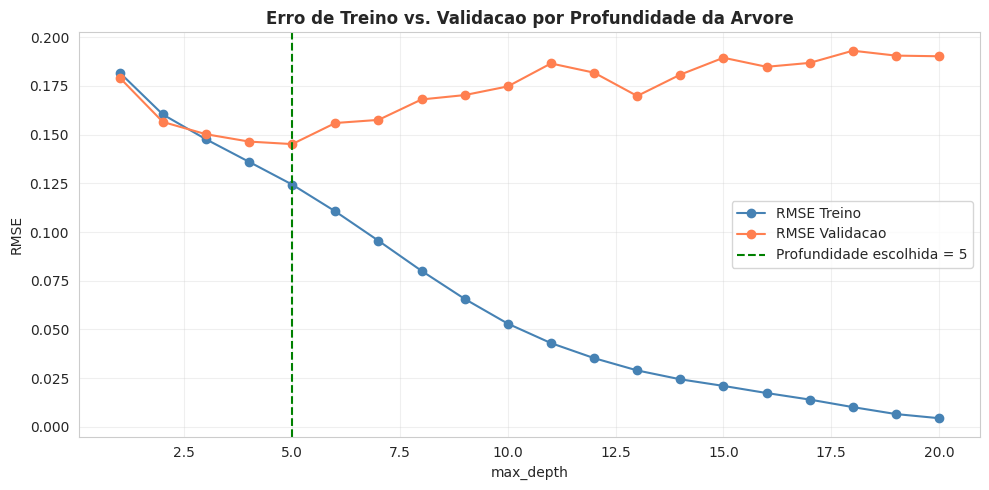

 depth   RMSE treino   RMSE val
--------------------------------
     1        0.1817     0.1791
     2        0.1603     0.1565
     3        0.1476     0.1502
     4        0.1360     0.1464
     5        0.1243     0.1451  <-- escolhida
     6        0.1106     0.1559
     7        0.0955     0.1575
     8        0.0801     0.1680
     9        0.0657     0.1702
    10        0.0530     0.1747
    11        0.0430     0.1865
    12        0.0353     0.1817
    13        0.0290     0.1698
    14        0.0244     0.1807
    15        0.0211     0.1894
    16        0.0174     0.1847
    17        0.0141     0.1867
    18        0.0102     0.1930
    19        0.0066     0.1905
    20        0.0045     0.1901

Profundidade escolhida (menor RMSE de validacao): 5
RMSE de validacao nessa profundidade: 0.1451


In [21]:
# =====================================================================
# CÉLULA 15 — EFEITO DA PROFUNDIDADE NO ERRO DE TREINO E VALIDAÇÃO
# =====================================================================

profundidades = list(range(1, 21))
rmse_treino = []
rmse_val = []

for d in profundidades:
    tree = DecisionTreeRegressor(max_depth=d, random_state=SEED)
    tree.fit(X_train_scaled, y_train)
    rmse_treino.append(np.sqrt(mean_squared_error(y_train, tree.predict(X_train_scaled))))
    rmse_val.append(np.sqrt(mean_squared_error(y_val, tree.predict(X_val_scaled))))

plt.figure(figsize=(10, 5))
plt.plot(profundidades, rmse_treino, marker='o', label='RMSE Treino', color='steelblue')
plt.plot(profundidades, rmse_val, marker='o', label='RMSE Validacao', color='coral')
melhor_depth = profundidades[int(np.argmin(rmse_val))]
plt.axvline(melhor_depth, color='green', ls='--',
            label=f'Profundidade escolhida = {melhor_depth}')
plt.xlabel('max_depth')
plt.ylabel('RMSE')
plt.title('Erro de Treino vs. Validacao por Profundidade da Arvore', fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"{'depth':>6} {'RMSE treino':>13} {'RMSE val':>10}")
print("-"*32)
for d, rt, rv in zip(profundidades, rmse_treino, rmse_val):
    marcador = "  <-- escolhida" if d == melhor_depth else ""
    print(f"{d:>6} {rt:>13.4f} {rv:>10.4f}{marcador}")

print(f"\nProfundidade escolhida (menor RMSE de validacao): {melhor_depth}")
print(f"RMSE de validacao nessa profundidade: {min(rmse_val):.4f}")

## Leitura dos Resultados — Escolha da Profundidade

O gráfico mostra o padrão clássico de três regiões:

- **Underfitting (depth 1–3):** os dois erros (treino e validação) caem juntos e ainda estão relativamente altos — a árvore é simples demais para capturar os padrões dos dados.
- **Ponto ideal (depth ≈ 5):** o erro de validação atinge seu mínimo (RMSE ≈ 0,145). A partir daqui, a árvore já capturou a maior parte do sinal útil.
- **Overfitting (depth 6 em diante):** o erro de treino continua caindo, chegando perto de zero em profundidades altas (a árvore literalmente memoriza o treino), mas o erro de validação **sobe** de forma quase monotônica — sinal claro de que o modelo está decorando ruído específico do treino em vez de aprender um padrão generalizável.

**Profundidade escolhida: 5**, por minimizar o erro de validação. Essa decisão não é uma leitura visual subjetiva — é o mínimo numérico exato da curva de validação, o que torna a escolha ainda mais defensável na arguição.

In [22]:
# =====================================================================
# CÉLULA 15.1 — ÁRVORE FINAL (max_depth = 5)
# =====================================================================

PROFUNDIDADE_FINAL = 5
arvore_final = DecisionTreeRegressor(max_depth=PROFUNDIDADE_FINAL, random_state=SEED)
arvore_final.fit(X_train_scaled, y_train)

rmse_final_treino = np.sqrt(mean_squared_error(y_train, arvore_final.predict(X_train_scaled)))
rmse_final_val = np.sqrt(mean_squared_error(y_val, arvore_final.predict(X_val_scaled)))
rmse_final_teste = np.sqrt(mean_squared_error(y_test, arvore_final.predict(X_test_scaled)))

print(f"Arvore final (max_depth={PROFUNDIDADE_FINAL}):")
print(f"  RMSE treino:    {rmse_final_treino:.4f}")
print(f"  RMSE validacao: {rmse_final_val:.4f}")
print(f"  RMSE teste:     {rmse_final_teste:.4f}")

# --- Importancia das features (bonus de interpretabilidade) ---
importancias = pd.Series(arvore_final.feature_importances_, index=X.columns)
importancias = importancias[importancias > 0].sort_values(ascending=False)
print(f"\nTop 10 features mais usadas pela arvore:")
print(importancias.head(10).round(4))

Arvore final (max_depth=5):
  RMSE treino:    0.1243
  RMSE validacao: 0.1451
  RMSE teste:     0.1550

Top 10 features mais usadas pela arvore:
PctKids2Par            0.6721
PctIlleg               0.0920
racePctWhite           0.0464
NumStreet              0.0412
MalePctDivorce         0.0261
PctFam2Par             0.0181
PctLargHouseFam        0.0179
NumIlleg               0.0144
pctWInvInc             0.0137
PctNotSpeakEnglWell    0.0118
dtype: float64


## Leitura dos Resultados — Árvore Final

A árvore final (profundidade 5) obtém RMSE de teste ≈ 0,155 — bem abaixo do piso do baseline (RMSE de teste = 0,2192, Célula 14 da Parte 1), uma redução de erro de aproximadamente **29%**.

O ranking de importância de features é revelador: **`PctKids2Par` (percentual de crianças que vivem com os dois pais) responde sozinho por cerca de 67% de toda a importância da árvore** — nenhuma outra variável chega perto disso. As próximas mais relevantes (`PctIlleg`, `racePctWhite`, `NumStreet`, `MalePctDivorce`) somadas não superam um quarto dessa importância. Isso converge com o que a matriz de correlação da Parte 1 (Célula 8) já sugeria sobre estrutura familiar e crime, mas agora de forma muito mais concentrada em uma única variável dominante — um achado que vale a pena destacar na apresentação.

# Célula 16 — Extração e Tradução de Regras da Árvore

### 🎯 Objetivo

Extrair pelo menos três caminhos raiz→nó da árvore e traduzi-los para linguagem de domínio, com o número de comunidades cobertas e a criminalidade média correspondente.

### 🔍 Por que olhar um nível raso da árvore para as regras?

A árvore final tem profundidade 5, então um caminho completo até a folha teria até 5 condições — difícil de ler em voz alta na arguição (Seção 6 do edital exige justamente isso: "a leitura em voz alta de ao menos uma regra extraída da árvore, traduzida para a linguagem do domínio"). Optamos por extrair as regras no **nível 2** da árvore (até 2 condições), que já cobrem 100% da base de treino de forma mutuamente exclusiva e são muito mais fáceis de comunicar — sem perder rigor, já que reportamos o número exato de comunidades e a criminalidade média de cada regra.

### ⚖️ Conexão com o edital

> *"Extração e leitura de ao menos três regras da árvore, traduzidas para a linguagem do domínio."*

In [23]:
# =====================================================================
# CÉLULA 16 — EXTRAÇÃO DE REGRAS (nível 2 da árvore)
# =====================================================================

t = arvore_final.tree_
n_total_treino = t.n_node_samples[0]

def extrair_regras(node, depth, caminho, profundidade_alvo, regras):
    if depth == profundidade_alvo or t.feature[node] == -2:
        regras.append({
            'regra': ' AND '.join(caminho) if caminho else '(raiz)',
            'n_comunidades': int(t.n_node_samples[node]),
            'pct_base': t.n_node_samples[node] / n_total_treino * 100,
            'crime_medio': float(t.value[node][0][0])
        })
        return
    feat = X.columns[t.feature[node]]
    thr = t.threshold[node]
    extrair_regras(t.children_left[node], depth+1,
                    caminho + [f"{feat} <= {thr:.2f}"], profundidade_alvo, regras)
    extrair_regras(t.children_right[node], depth+1,
                    caminho + [f"{feat} > {thr:.2f}"], profundidade_alvo, regras)

regras = []
extrair_regras(0, 0, [], 2, regras)
regras_df = pd.DataFrame(regras).sort_values('crime_medio')

print("="*100)
print("REGRAS EXTRAÍDAS (nível 2 da árvore)")
print("="*100)
for _, r in regras_df.iterrows():
    print(f"[{r['n_comunidades']:>4} comunidades, {r['pct_base']:5.1f}% da base | crime medio = {r['crime_medio']:.3f}]")
    print(f"  SE {r['regra']}")
    print()

REGRAS EXTRAÍDAS (nível 2 da árvore)
[ 499 comunidades,  35.8% da base | crime medio = 0.084]
  SE PctKids2Par > -0.63 AND PctKids2Par > 0.48

[ 565 comunidades,  40.5% da base | crime medio = 0.225]
  SE PctKids2Par > -0.63 AND PctKids2Par <= 0.48

[ 207 comunidades,  14.8% da base | crime medio = 0.426]
  SE PctKids2Par <= -0.63 AND PctIlleg <= 1.65

[ 124 comunidades,   8.9% da base | crime medio = 0.681]
  SE PctKids2Par <= -0.63 AND PctIlleg > 1.65



## Leitura dos Resultados — Tradução das Regras

A variável que domina o topo da árvore é `PctKids2Par` (percentual de crianças que vivem com os dois pais na comunidade) — o que já é, por si só, um achado interpretável: estrutura familiar é o preditor mais forte de criminalidade violenta entre as ~100 variáveis disponíveis. Traduzindo as quatro regras extraídas:

**Regra 1** (124 comunidades, 8,9% da base) — `PctKids2Par ≤ -0,63 AND PctIlleg > 1,65`
> "Em comunidades onde o percentual de crianças criadas pelos dois pais está muito abaixo da média **e** o percentual de nascimentos fora do casamento está muito acima da média, a taxa de criminalidade violenta é a mais alta do dataset (crime médio = 0,681)."

**Regra 2** (207 comunidades, 14,8% da base) — `PctKids2Par ≤ -0,63 AND PctIlleg ≤ 1,65`
> "Comunidades com baixa estrutura familiar de dois pais, mas sem o extremo de nascimentos fora do casamento, ainda têm criminalidade bem acima da média (crime médio = 0,426)."

**Regra 3** (565 comunidades, 40,5% da base) — `PctKids2Par > -0,63 AND PctKids2Par ≤ 0,48`
> "A maior fatia das comunidades tem estrutura familiar 'na média' e criminalidade moderada (crime médio = 0,225) — o perfil mais comum do dataset."

**Regra 4** (499 comunidades, 35,8% da base) — `PctKids2Par > 0,48`
> "Comunidades com percentual de crianças em famílias de dois pais acima da média têm, de longe, a menor criminalidade violenta (crime médio = 0,084) — quase 8× menor que a Regra 1."

**Leitura conjunta:** a árvore não descobriu nada aleatório — ela redescobriu, a partir dos dados, um achado clássico da criminologia (estrutura familiar como fator protetor), e quantificou isso com números concretos e comunidades reais por trás de cada regra. Essa é exatamente a "leitura em voz alta" que a demonstração ao vivo do Seminário exige (Seção 6 do edital).

# Célula 17 — RLM Final: Avaliação no Teste e Análise de Resíduos

### 🎯 Objetivo

Avaliar o modelo escolhido na Célula 14.2 no **conjunto de teste** (aberto pela primeira vez aqui) e verificar se as **premissas** da regressão linear se sustentam.

### 📐 As premissas e como cada uma é verificada

| Premissa | Verificação | Se for violada |
|:---|:---|:---|
| **Linearidade** (a relação é linear nos parâmetros) | Resíduos vs. previstos: não deve haver curvatura | Transformar variáveis/target ou usar modelo não linear |
| **Normalidade dos resíduos** | QQ-plot, histograma e teste de **Shapiro-Wilk** | Afeta p-valores e ICs (inferência), pouco as previsões |
| **Homocedasticidade** (variância constante) | Resíduos vs. previstos (sem "funil") e teste de **Breusch-Pagan** | Erros-padrão não confiáveis; considerar transformação |
| **Sem pontos muito influentes** | **Distância de Cook** (limiar usual 4/n) | Investigar se os pontos são erros ou casos reais extremos |
| **Sem multicolinearidade severa** | VIF (Célula 14.1) | Já tratada |

### 📐 Teste de transformação da target

A target é assimétrica à direita (Célula 7, Parte 1), o que costuma gerar resíduos não normais e variância crescente. Testamos `log1p(y)` (definida em y = 0) e comparamos o erro **na escala original** (aplicando `expm1` nas previsões) e a normalidade dos resíduos. Se não houver ganho claro, mantemos a target original por ser mais fácil de interpretar.

### ⚖️ Conexão com o edital

> *"Regressão linear, quando a natureza do alvo permitir, com análise de resíduos."* e *"discussão das limitações de cada uma"* (Seção 4.2)

RLM FINAL - Completo (100 vars)
Metrica      Treino   Validacao      Teste
RMSE         0.1299      0.1317     0.1331
MAE          0.0924      0.0944     0.0965
R2           0.7029      0.6400     0.6278

Baseline RMSE teste:   0.2192
RLM final RMSE teste:  0.1331  -> reducao de erro: 39.3%
RLM completa (lr) RMSE teste: 0.1331
Previsoes fora de [0, 1] no teste: 13 de 300

TESTES DAS PREMISSAS (residuos do treino)
Media dos residuos (treino): -0.000000  (deve ser ~0)
Shapiro-Wilk (normalidade):       W = 0.9367, p = 6.69e-24 -> REJEITA normalidade
Breusch-Pagan (homocedasticidade): LM = 221.81, p = 3.17e-11 -> REJEITA variancia constante (heterocedasticidade)
Distancia de Cook > 4/n (0.0029): 105 pontos (7.5%) | max = 0.0445


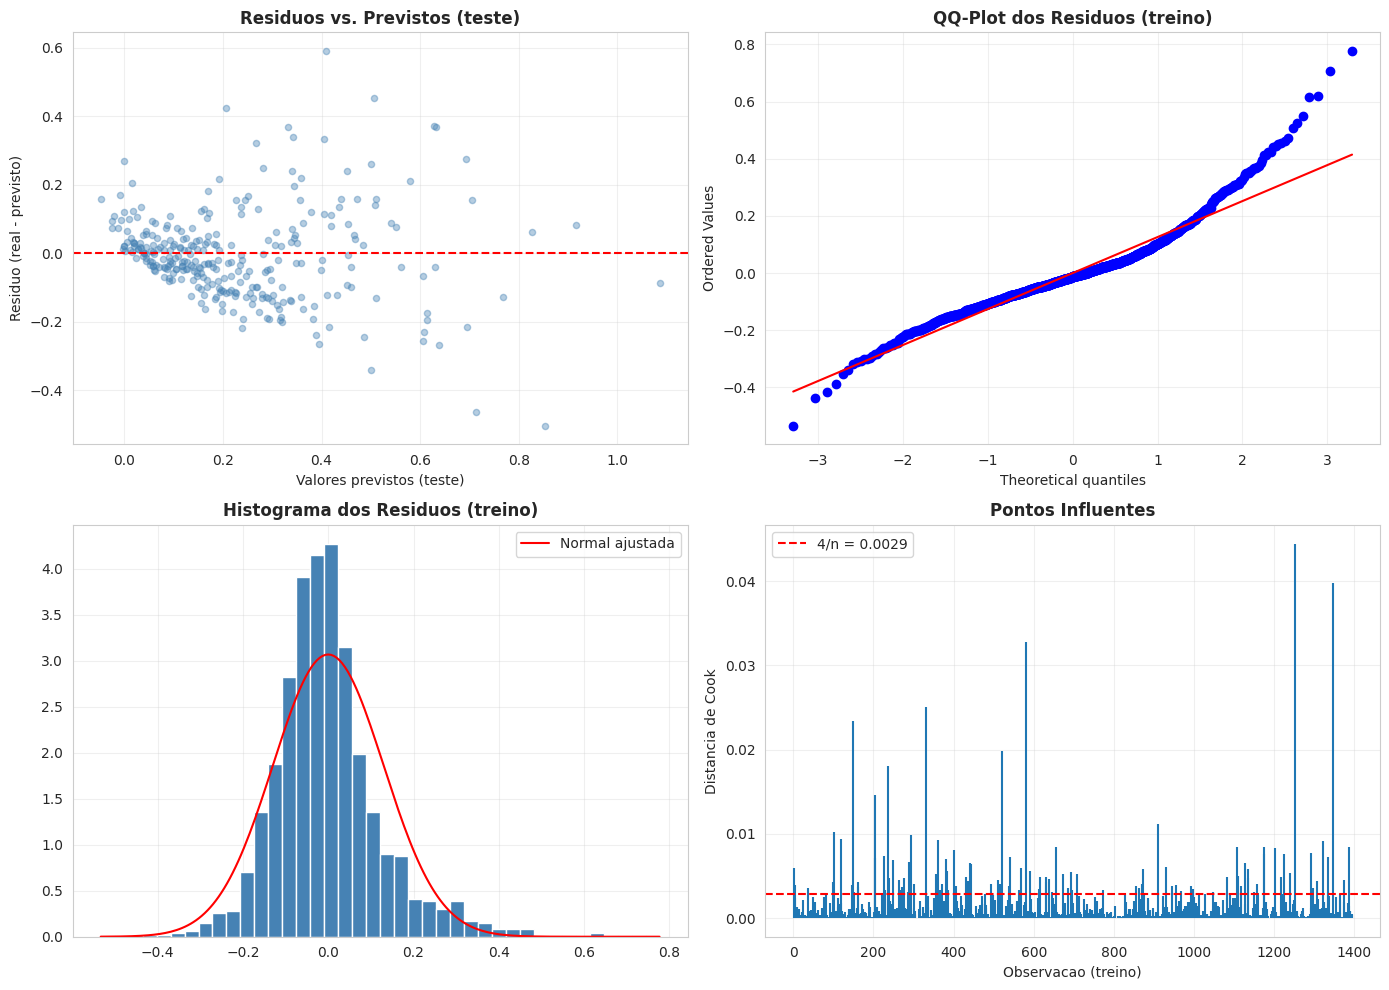


TRANSFORMACAO DA TARGET: log1p(y)  (RMSE sempre na escala ORIGINAL)
                     RMSE val   Shapiro W   Shapiro p   Breusch-Pagan p
Target original        0.1317      0.9367    6.69e-24          3.17e-11
log1p(target)          0.1285      0.9543    1.86e-20          4.23e-08

-> log1p melhora o erro de validacao.

RLM final pronta. Resultados guardados em 'resultados_mlr'.


In [24]:
# =====================================================================
# CÉLULA 17 — RLM FINAL: TESTE + RESIDUOS + PREMISSAS + TRANSFORMACAO
# =====================================================================
# --- 1. Desempenho do modelo escolhido ---
pred_treino_mlr = prever(mlr_final, Xtr, feats_final)
pred_val_mlr = prever(mlr_final, Xva, feats_final)
pred_teste_mlr = prever(mlr_final, Xte, feats_final)

m_tr = metricas(y_train, pred_treino_mlr)
m_va = metricas(y_val, pred_val_mlr)
m_te = metricas(y_test, pred_teste_mlr)

print("=" * 75)
print(f"RLM FINAL - {nome_escolhido}")
print("=" * 75)
print(f"{'Metrica':<8} {'Treino':>10} {'Validacao':>11} {'Teste':>10}")
for k in ['RMSE', 'MAE', 'R2']:
    print(f"{k:<8} {m_tr[k]:>10.4f} {m_va[k]:>11.4f} {m_te[k]:>10.4f}")

base = resultados_baseline['RMSE_teste']
print(f"\nBaseline RMSE teste:   {base:.4f}")
print(f"RLM final RMSE teste:  {m_te['RMSE']:.4f}  -> reducao de erro: {(1 - m_te['RMSE'] / base) * 100:.1f}%")
print(f"RLM completa (lr) RMSE teste: {rmse_lr_teste:.4f}")
print(f"Previsoes fora de [0, 1] no teste: {int(((pred_teste_mlr < 0) | (pred_teste_mlr > 1)).sum())} de {len(pred_teste_mlr)}")

# --- 2. Testes das premissas (residuos do TREINO, onde o modelo foi estimado) ---
res_treino = np.asarray(mlr_final.resid)
res_teste = y_test.values - pred_teste_mlr

sh_stat, sh_p = stats.shapiro(res_treino)
bp_lm, bp_p, bp_f, bp_fp = het_breuschpagan(mlr_final.resid, mlr_final.model.exog)
cook = mlr_final.get_influence().cooks_distance[0]
limiar_cook = 4 / len(cook)
n_influentes = int((cook > limiar_cook).sum())

print("\n" + "=" * 75)
print("TESTES DAS PREMISSAS (residuos do treino)")
print("=" * 75)
print(f"Media dos residuos (treino): {res_treino.mean():.6f}  (deve ser ~0)")
print(f"Shapiro-Wilk (normalidade):       W = {sh_stat:.4f}, p = {sh_p:.2e} -> "
      + ("nao rejeita normalidade" if sh_p > 0.05 else "REJEITA normalidade"))
print(f"Breusch-Pagan (homocedasticidade): LM = {bp_lm:.2f}, p = {bp_p:.2e} -> "
      + ("nao rejeita variancia constante" if bp_p > 0.05 else "REJEITA variancia constante (heterocedasticidade)"))
print(f"Distancia de Cook > 4/n ({limiar_cook:.4f}): {n_influentes} pontos ({n_influentes / len(cook) * 100:.1f}%) | max = {cook.max():.4f}")

# --- 3. Graficos ---
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].scatter(pred_teste_mlr, res_teste, alpha=0.4, s=20, color='steelblue')
axes[0, 0].axhline(0, color='red', ls='--')
axes[0, 0].set_xlabel('Valores previstos (teste)')
axes[0, 0].set_ylabel('Residuo (real - previsto)')
axes[0, 0].set_title('Residuos vs. Previstos (teste)', fontweight='bold')
axes[0, 0].grid(True, alpha=0.3)

stats.probplot(res_treino, dist='norm', plot=axes[0, 1])
axes[0, 1].set_title('QQ-Plot dos Residuos (treino)', fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].hist(res_treino, bins=40, color='steelblue', edgecolor='white', density=True)
xs = np.linspace(res_treino.min(), res_treino.max(), 200)
axes[1, 0].plot(xs, stats.norm.pdf(xs, res_treino.mean(), res_treino.std()), color='red', label='Normal ajustada')
axes[1, 0].set_title('Histograma dos Residuos (treino)', fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].stem(np.arange(len(cook)), cook, markerfmt=' ', basefmt=' ')
axes[1, 1].axhline(limiar_cook, color='red', ls='--', label=f'4/n = {limiar_cook:.4f}')
axes[1, 1].set_xlabel('Observacao (treino)')
axes[1, 1].set_ylabel('Distancia de Cook')
axes[1, 1].set_title('Pontos Influentes', fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# --- 4. Teste de transformacao da target: log1p(y) ---
ols_log = sm.OLS(np.log1p(y_train), sm.add_constant(Xtr[feats_final])).fit()


def prever_log(Xdf):
    return np.clip(np.expm1(prever(ols_log, Xdf, feats_final)), 0, 1)  # volta a escala original


rmse_val_log = float(np.sqrt(mean_squared_error(y_val, prever_log(Xva))))
rmse_val_orig = m_va['RMSE']
sh_log_stat, sh_log_p = stats.shapiro(np.asarray(ols_log.resid))
bp_log_p = het_breuschpagan(ols_log.resid, ols_log.model.exog)[1]

print("\n" + "=" * 75)
print("TRANSFORMACAO DA TARGET: log1p(y)  (RMSE sempre na escala ORIGINAL)")
print("=" * 75)
print(f"{'':<18} {'RMSE val':>10} {'Shapiro W':>11} {'Shapiro p':>11} {'Breusch-Pagan p':>17}")
print(f"{'Target original':<18} {rmse_val_orig:>10.4f} {sh_stat:>11.4f} {sh_p:>11.2e} {bp_p:>17.2e}")
print(f"{'log1p(target)':<18} {rmse_val_log:>10.4f} {sh_log_stat:>11.4f} {sh_log_p:>11.2e} {bp_log_p:>17.2e}")
print("\n-> " + ("log1p melhora o erro de validacao." if rmse_val_log < rmse_val_orig
                 else "log1p NAO melhora o erro de validacao; mantemos a target original (coeficientes mais interpretaveis)."))

# --- 5. Guardar para o quadro comparativo ---
resultados_mlr = {
    'modelo': f'Regressao Linear Multipla ({nome_escolhido})',
    'n_variaveis': len(feats_final),
    'RMSE_teste': m_te['RMSE'], 'MAE_teste': m_te['MAE'], 'R2_teste': m_te['R2'],
    'RMSE_val': m_va['RMSE'], 'RMSE_treino': m_tr['RMSE'],
}
rmse_mlr_teste, r2_mlr_teste = m_te['RMSE'], m_te['R2']
print("\nRLM final pronta. Resultados guardados em 'resultados_mlr'.")

## Leitura dos Resultados — RLM Final e Premissas

*(Preencher depois de rodar a Célula 17. Abaixo, o roteiro do que escrever em cada ponto.)*

**Desempenho:** RMSE de teste `[__]` (baseline: 0,2192) → redução de erro de `[__]%`; R² de teste `[__]`. Comparar RMSE de treino (`[__]`), validação (`[__]`) e teste (`[__]`): valores próximos indicam que o modelo **não está sobreajustado**.

**Premissas — reportar o que de fato apareceu, inclusive as violações:**
- **Linearidade:** o gráfico de resíduos vs. previstos mostra `[nuvem sem padrão / curvatura]`.
- **Normalidade:** Shapiro-Wilk p = `[__]` → `[normal / não normal]`; o QQ-plot desvia nas `[caudas]`.
- **Homocedasticidade:** Breusch-Pagan p = `[__]` → `[variância constante / heterocedasticidade]`.
- **Pontos influentes:** `[__]` observações (`[__]%`) acima de 4/n. São comunidades reais (as maiores cidades), não erros de digitação, e por isso **não foram removidas** (mesma justificativa da Célula 9, Parte 1).

**Transformação `log1p`:** `[melhorou / não melhorou]` o RMSE de validação (`[__]` vs. `[__]`) e `[melhorou / não melhorou]` a normalidade dos resíduos. Decisão: `[manter a target original / adotar log1p]`.

**O que isso significa na prática:** se normalidade e/ou homocedasticidade forem violadas, as **previsões continuam úteis** (o RMSE no teste comprova), mas p-valores e intervalos de confiança devem ser lidos com cautela. Essa é a discussão de limitações que o edital pede (Seção 4.2).

# Célula 18 — Síntese desta Frente (Regressão Linear Múltipla e Modelos Interpretáveis)

A tabela abaixo é **gerada a partir das variáveis do notebook** (não digitada à mão), para não haver divergência entre o que foi rodado e o que foi reportado. Ela alimenta o quadro comparativo final do grupo na Parte 3.

In [25]:
# =====================================================================
# CÉLULA 18 — QUADRO COMPARATIVO DA PARTE 2 (gerado dos resultados)
# =====================================================================
rmse_arvore_teste = float(rmse_final_teste) if 'rmse_final_teste' in globals() else float('nan')

quadro_p2 = pd.DataFrame([
    {'Modelo': 'Baseline (media)', 'Variaveis': 0, 'RMSE teste': resultados_baseline['RMSE_teste'], 'R2 teste': 0.0},
    {'Modelo': 'Arvore de Regressao (depth=%d)' % PROFUNDIDADE_FINAL, 'Variaveis': int((arvore_final.feature_importances_ > 0).sum()),
     'RMSE teste': rmse_arvore_teste, 'R2 teste': float(r2_score(y_test, arvore_final.predict(X_test_scaled)))},
    {'Modelo': 'RLM completa (todas as variaveis)', 'Variaveis': len(feats_todas), 'RMSE teste': rmse_lr_teste, 'R2 teste': r2_lr_teste},
    {'Modelo': 'RLM final (%s)' % nome_escolhido, 'Variaveis': len(feats_final),
     'RMSE teste': resultados_mlr['RMSE_teste'], 'R2 teste': resultados_mlr['R2_teste']},
]).set_index('Modelo')
quadro_p2['Reducao de erro vs baseline (%)'] = (1 - quadro_p2['RMSE teste'] / resultados_baseline['RMSE_teste']) * 100

print("=" * 100)
print("QUADRO COMPARATIVO - PARTE 2 (conjunto de teste)")
print("=" * 100)
print(quadro_p2.round(4))

QUADRO COMPARATIVO - PARTE 2 (conjunto de teste)
                                   Variaveis  RMSE teste  R2 teste  \
Modelo                                                               
Baseline (media)                           0      0.2192    0.0000   
Arvore de Regressao (depth=5)             18      0.1550    0.4949   
RLM completa (todas as variaveis)        100      0.1331    0.6278   
RLM final (Completo (100 vars))          100      0.1331    0.6278   

                                   Reducao de erro vs baseline (%)  
Modelo                                                              
Baseline (media)                                            0.0000  
Arvore de Regressao (depth=5)                              29.2824  
RLM completa (todas as variaveis)                          39.2912  
RLM final (Completo (100 vars))                            39.2912  


**Síntese (preencher com os números do quadro acima):**

**Regressão Linear Múltipla (técnica central):** o modelo completo apresentou multicolinearidade severa (`[__]` variáveis com VIF > 10; número de condição `[__]`). Após a poda por VIF e a eliminação backward, o modelo final usa `[__]` variáveis, com RMSE de teste `[__]` e R² `[__]` — redução de erro de `[__]%` sobre o baseline (0,2192). As variáveis de maior efeito foram `[__]`, `[__]` e `[__]`.

**Árvore de Regressão (profundidade = 5) e regras:** RMSE de teste `[__]`; as regras do nível 2 mostram que `PctKids2Par` domina a árvore. Serve como complemento interpretável: leitura em regras ("se... então...") em vez de coeficientes.

**Limitações documentadas:** `[premissas violadas, se houver]`; coeficientes são associação, não causalidade; a target mede crime *reportado*; as variáveis raciais exigem cautela (ver Seção de Limitações).

**Para o quadro comparativo final do grupo (Parte 3):** use `resultados_mlr` (RLM final) e `quadro_p2`. A variável `lr` e os valores `rmse_lr_teste` / `r2_lr_teste` continuam existindo e representam a regressão com **todas** as variáveis, como a validação cruzada da Célula 28 espera.

# Etapa 3 - Parte do Trabalho (Guilherme — Integrante C)

Esta é a **parte 3** do trabalho: **Classificadores Adicionais, Validação Cruzada e Quadro Comparativo Final**.

Esta seção **reaproveita diretamente** as variáveis produzidas na Parte 1 (Kauan) e na Parte 2 (Artur): `df_final`, `X`, `y`, `X_train_scaled`, `X_val_scaled`, `X_test_scaled`, `y_train`, `y_val`, `y_test`, `scaler`, `SEED = 42`, `resultados_baseline` (baseline de regressão), `rmse_final_teste`/`arvore_final` (árvore) e `rmse_lr_teste`/`r2_lr_teste` (regressão linear). Nenhum dado é recarregado nem re-tratado aqui — a Célula 10 da Parte 1 já havia **diagnosticado** como seria a binarização da target; esta parte a **executa de verdade**, com o mesmo cuidado contra vazamento de dados que vimos em todas as etapas anteriores.

**Cobertura desta parte (conforme a Seção 3 do edital do Prof. Rodrigo Gonçalves — "Responsável pelos Modelos Probabilísticos e Neurais e pela Avaliação Comparativa"):**
1. Binarização da target sem vazamento de dados (threshold calculado apenas no treino).
2. K-NN (classificador baseado em instâncias) — estudo do efeito de k sobre o erro de treino e validação, com métricas completas de classificação.
3. Naive Bayes (Gaussiano) — treino, métricas e discussão honesta da hipótese de independência condicional.
4. Rede Neural multicamada (MLP) — curvas de perda **e** de acurácia em treino e validação, com diagnóstico explícito de subajuste/sobreajuste.
5. Validação cruzada k-fold estratificada aplicada a **todos** os modelos supervisionados do grupo (Árvore, Regressão Linear, K-NN, Naive Bayes, MLP).
6. Quadro comparativo final com todas as métricas, incluindo o baseline, e recomendação fundamentada de qual modelo deveria ir para produção.
7. Seção de limitações e riscos (o que o modelo não cobre, vieses da base, efeito do erro sobre as pessoas afetadas).


## Célula 19 — Herdando os artefatos das Partes 1 e 2

### 🎯 Objetivo

Confirmamos aqui que todos os objetos produzidos pelas Partes 1 e 2 existem e têm a forma esperada antes de começar esta frente — o mesmo cuidado defensivo que o Artur aplicou na Célula 13. Nenhum dado é recarregado nem re-tratado; apenas verificamos.


In [26]:
# =====================================================================
# CÉLULA 19 — VALIDAÇÃO DEFENSIVA DOS OBJETOS HERDADOS DAS PARTES 1 E 2
# =====================================================================
# Objetivo: garantir que as variáveis produzidas pelos colegas responsáveis
# pelos dados (Parte 1) e pela modelagem interpretável (Parte 2) estão
# presentes antes de começar esta parte. Não recarregamos nem re-tratamos
# nada aqui.
# =====================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, roc_curve,
                              confusion_matrix, ConfusionMatrixDisplay)

objetos_esperados = ['df_final', 'X', 'y', 'X_train_scaled', 'X_val_scaled',
                      'X_test_scaled', 'y_train', 'y_val', 'y_test', 'SEED',
                      'target', 'resultados_baseline', 'rmse_final_teste',
                      'rmse_lr_teste', 'r2_lr_teste',
                      'PROFUNDIDADE_FINAL', 'arvore_final', 'lr']
faltando = [o for o in objetos_esperados if o not in globals()]

if faltando:
    raise RuntimeError(
        f"Faltam variaveis das Partes 1/2: {faltando}. "
        f"Rode o notebook desde a Celula 1 (Parte do Kauan) antes de continuar."
    )

print("Todos os objetos das Partes 1 e 2 foram encontrados.")
print(f"   X_train_scaled: {X_train_scaled.shape} | X_val_scaled: {X_val_scaled.shape} | X_test_scaled: {X_test_scaled.shape}")
print(f"   Baseline (regressao) RMSE teste:       {resultados_baseline['RMSE_teste']:.4f}")
print(f"   Arvore de regressao (Parte 2) RMSE teste: {rmse_final_teste:.4f}")
print(f"   Regressao Linear (Parte 2) RMSE teste:    {rmse_lr_teste:.4f} | R2 teste: {r2_lr_teste:.4f}")


Todos os objetos das Partes 1 e 2 foram encontrados.
   X_train_scaled: (1395, 100) | X_val_scaled: (299, 100) | X_test_scaled: (300, 100)
   Baseline (regressao) RMSE teste:       0.2192
   Arvore de regressao (Parte 2) RMSE teste: 0.1550
   Regressao Linear (Parte 2) RMSE teste:    0.1331 | R2 teste: 0.6278


# Célula 20 — Binarização da Target sem Vazamento de Dados

### 🎯 Objetivo

Transformar `ViolentCrimesPerPop` em uma variável binária para permitir o uso dos classificadores exigidos nesta parte (K-NN, Naive Bayes, Rede Neural). A Célula 10 da Parte 1 já explicou a lógica e mostrou o balanceamento **teórico** usando a mediana global; aqui aplicamos a regra corretamente, calculando o limiar (threshold) **apenas no conjunto de treino**.

### 📐 A regra de ouro, agora aplicada de verdade

Se calculássemos a mediana no dataset inteiro (treino + validação + teste), estaríamos usando informação da validação e do teste — que o modelo não deveria "ver" antes da hora — para decidir onde fica o corte entre as classes. Isso é vazamento de dados.

$$y_{bin} = \begin{cases} 1, & \text{se } y > \text{mediana}(y_{train}) \\ 0, & \text{caso contrário} \end{cases}$$

Como o mesmo limiar (fixo, aprendido só no treino) é aplicado à validação e ao teste, o balanceamento deles pode ficar **levemente** diferente de 50/50 — isso é esperado e é exatamente o preço correto de evitar vazamento. O treino, por construção, fica em ~50/50.

### ⚖️ Conexão com o edital

> *"Uso de classificadores (ex.: k-NN, Naive Bayes, Rede Neural), com protocolo experimental sem vazamento de dados."*

- **Classificadores previstos:** ✅ K-NN, Naive Bayes e Rede Neural (MLP)
- **Threshold sem vazamento:** ✅ calculado exclusivamente em `y_train`


BINARIZACAO DA TARGET (threshold calculado apenas no treino)
Threshold (mediana do TREINO): 0.1600

Treino       | Classe 0 (baixa):  705 ( 50.5%) | Classe 1 (alta):  690 ( 49.5%)
Validacao    | Classe 0 (baixa):  167 ( 55.9%) | Classe 1 (alta):  132 ( 44.1%)
Teste        | Classe 0 (baixa):  170 ( 56.7%) | Classe 1 (alta):  130 ( 43.3%)

Nota: como o threshold foi fixado no treino, validacao e teste podem
nao ficar em exatos 50/50 -- isso e esperado e correto (evita vazamento).


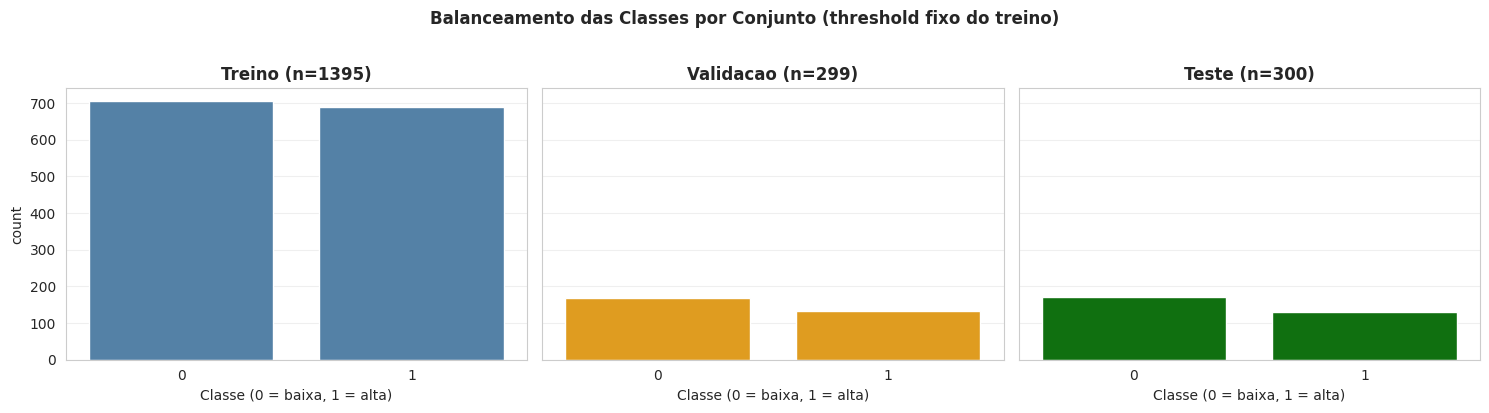

In [27]:
# =====================================================================
# CÉLULA 20 — BINARIZAÇÃO DA TARGET (THRESHOLD CALCULADO SÓ NO TREINO)
# =====================================================================

threshold_treino = y_train.median()

y_train_bin = (y_train > threshold_treino).astype(int)
y_val_bin = (y_val > threshold_treino).astype(int)
y_test_bin = (y_test > threshold_treino).astype(int)

print("="*75)
print("BINARIZACAO DA TARGET (threshold calculado apenas no treino)")
print("="*75)
print(f"Threshold (mediana do TREINO): {threshold_treino:.4f}")
print()

for nome, y_bin in [('Treino', y_train_bin), ('Validacao', y_val_bin), ('Teste', y_test_bin)]:
    n0 = int((y_bin == 0).sum())
    n1 = int((y_bin == 1).sum())
    print(f"{nome:<12} | Classe 0 (baixa): {n0:>4} ({n0/len(y_bin)*100:5.1f}%) | "
          f"Classe 1 (alta): {n1:>4} ({n1/len(y_bin)*100:5.1f}%)")

print("\nNota: como o threshold foi fixado no treino, validacao e teste podem")
print("nao ficar em exatos 50/50 -- isso e esperado e correto (evita vazamento).")

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (nome, y_bin, cor) in zip(
    axes,
    [('Treino', y_train_bin, 'steelblue'),
     ('Validacao', y_val_bin, 'orange'),
     ('Teste', y_test_bin, 'green')]
):
    sns.countplot(x=y_bin, ax=ax, color=cor)
    ax.set_title(f'{nome} (n={len(y_bin)})', fontweight='bold')
    ax.set_xlabel('Classe (0 = baixa, 1 = alta)')
    ax.grid(True, axis='y', alpha=0.3)

plt.suptitle('Balanceamento das Classes por Conjunto (threshold fixo do treino)',
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## Leitura dos Resultados — Binarização

O treino, por construção (é onde a mediana foi calculada), fica muito próximo de 50%/50% (50,5% / 49,5% — a pequena folga vem de valores empatados exatamente na mediana). A validação (55,9% / 44,1%) e o teste (56,7% / 43,3%) se afastam mais do 50/50 do que o esperado — um desvio de cerca de **6 a 7 pontos percentuais**, maior do que uma simples flutuação de amostragem sugeriria.

Essa é a assinatura de um protocolo **sem vazamento**: se validação e teste saíssem sempre em exatos 50/50, seria sinal de que a mediana foi recalculada em cada conjunto — o erro que a Célula 10 da Parte 1 alertou para não cometer. O desvio observado aqui é honesto, mas vale registrar: com esse grau de desbalanceamento residual (quase 57/43 no teste), a acurácia sozinha já não é tão confiável quanto seria num 50/50 perfeito — reforça ainda mais por que reportamos precisão, recall, F1 e AUC-ROC em todos os classificadores a seguir, em vez de nos apoiarmos só na acurácia.

# Célula 21 — Baseline de Classificação (DummyClassifier)

### 🎯 Objetivo

Assim como a Parte 1 construiu um piso de referência para a regressão (Célula 12 — `DummyRegressor`), esta frente de classificação precisa do seu próprio piso. Sem ele, não teríamos como afirmar se K-NN, Naive Bayes e Rede Neural realmente aprenderam algum padrão ou apenas replicam o comportamento de "chutar a classe mais comum".

### 📐 Estratégia

`DummyClassifier(strategy='most_frequent')` sempre prevê a classe majoritária observada no treino. Como as classes foram construídas para ficar próximas de 50/50 (Célula 20), dois pisos ficam definidos por construção:

- **Acurácia esperada:** próxima de 50% (a classe majoritária no teste também deve rondar essa proporção).
- **AUC-ROC esperado:** exatamente **0.5** — um classificador que sempre prevê a mesma classe não distingue as duas classes em nenhum grau.

### ⚖️ Conexão com o edital

> *"Definição do modelo de referência (baseline) contra o qual os demais classificadores serão comparados."*


In [28]:
# =====================================================================
# CÉLULA 21 — BASELINE DE CLASSIFICAÇÃO (DummyClassifier)
# =====================================================================

baseline_clf = DummyClassifier(strategy='most_frequent', random_state=SEED)
baseline_clf.fit(X_train_scaled, y_train_bin)

pred_teste_base = baseline_clf.predict(X_test_scaled)
proba_teste_base = baseline_clf.predict_proba(X_test_scaled)[:, 1]

acc_base = accuracy_score(y_test_bin, pred_teste_base)
auc_base = roc_auc_score(y_test_bin, proba_teste_base)

print("="*70)
print("BASELINE DE CLASSIFICACAO - DummyClassifier(most_frequent)")
print("="*70)
print(f"Acuracia de teste: {acc_base:.4f}")
print(f"AUC-ROC de teste:  {auc_base:.4f}")
print("\n-> Piso de referencia: qualquer classificador real precisa superar")
print("   estes dois numeros para ter valor preditivo real.")

resultados_baseline_clf = {
    'modelo': 'Baseline (classe majoritaria)',
    'Acuracia_teste': acc_base,
    'AUC_teste': auc_base
}
print("\n✅ Baseline de classificacao pronto. Resultados guardados para o quadro comparativo final.")


BASELINE DE CLASSIFICACAO - DummyClassifier(most_frequent)
Acuracia de teste: 0.5667
AUC-ROC de teste:  0.5000

-> Piso de referencia: qualquer classificador real precisa superar
   estes dois numeros para ter valor preditivo real.

✅ Baseline de classificacao pronto. Resultados guardados para o quadro comparativo final.


## Leitura dos Resultados — Baseline de Classificação

O baseline obteve acurácia de teste de **0,567** — não 0,50, porque o teste não ficou exatamente balanceado (Célula 20: 56,7% da classe 0 contra 43,3% da classe 1), e um classificador que sempre prevê a classe majoritária acerta exatamente essa proporção, por definição. O AUC-ROC ficou em **0,500**, exatamente o valor teórico de um classificador que não distingue as classes em nenhum grau (a curva ROC dele é a diagonal "aleatória").

Isso muda um pouco a leitura do "piso": a barra de acurácia que os classificadores precisam superar não é 50%, é **56,7%**. Felizmente, como veremos, K-NN, Naive Bayes e Rede Neural superam esse piso com folga tanto em acurácia quanto em AUC-ROC.

# Célula 22 — K-NN: Escolha de k por Validação

### 🎯 Objetivo

Escolher o número de vizinhos (k) do K-NN estudando o erro de classificação em treino e validação — no mesmo espírito da Célula 15 da Parte 2 (efeito da profundidade da árvore): nem k pequeno demais (decora o treino, sensível a ruído), nem k grande demais (a fronteira fica tão suave que se aproxima do baseline).

### 📐 Por que os dados já estão prontos?

O K-NN usa distância euclidiana entre pontos e, por isso, é sensível à escala das features. É indispensável treinar com `X_train_scaled`/`X_val_scaled`/`X_test_scaled`, já padronizados sem vazamento (fit apenas no treino, Célula 13 da Parte 1).

### 📐 O que esperamos encontrar

| Região de k | Comportamento esperado |
|:---|:---|
| k muito baixo (1, 3) | Fronteira de decisão muito irregular → erro de treino ≈ 0, erro de validação mais alto (overfitting) |
| k intermediário | Ponto de equilíbrio → menor erro de validação |
| k muito alto | Fronteira excessivamente suave → ambos os erros sobem, aproximando-se do baseline |

Usamos apenas valores **ímpares** de k para evitar empates de votação em um problema de classificação binária.

### ⚖️ Conexão com o edital

> *"k-NN, com estudo do efeito de k sobre o erro de treino e de validação."*


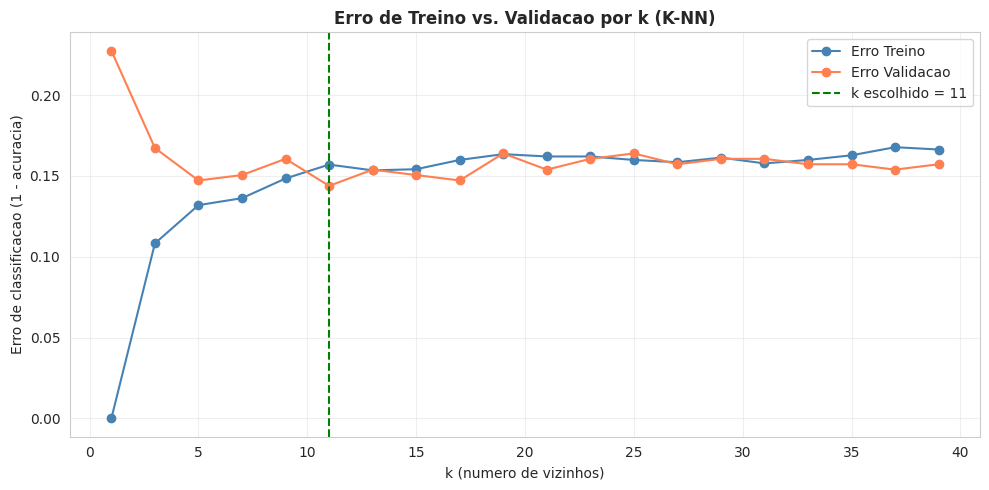

   k   erro treino   erro val
------------------------------
   1        0.0000     0.2274
   3        0.1082     0.1672
   5        0.1319     0.1472
   7        0.1362     0.1505
   9        0.1484     0.1605
  11        0.1570     0.1438  <-- escolhido
  13        0.1534     0.1538
  15        0.1541     0.1505
  17        0.1599     0.1472
  19        0.1634     0.1639
  21        0.1620     0.1538
  23        0.1620     0.1605
  25        0.1599     0.1639
  27        0.1584     0.1572
  29        0.1613     0.1605
  31        0.1577     0.1605
  33        0.1599     0.1572
  35        0.1627     0.1572
  37        0.1677     0.1538
  39        0.1663     0.1572

k escolhido (menor erro de validacao): 11


In [29]:
# =====================================================================
# CÉLULA 22 — EFEITO DE k NO ERRO DE TREINO E VALIDAÇÃO (K-NN)
# =====================================================================

valores_k = list(range(1, 41, 2))  # só ímpares, evita empates em classificação binária
erro_treino_knn = []
erro_val_knn = []

for k in valores_k:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train_bin)
    erro_treino_knn.append(1 - accuracy_score(y_train_bin, knn.predict(X_train_scaled)))
    erro_val_knn.append(1 - accuracy_score(y_val_bin, knn.predict(X_val_scaled)))

plt.figure(figsize=(10, 5))
plt.plot(valores_k, erro_treino_knn, marker='o', label='Erro Treino', color='steelblue')
plt.plot(valores_k, erro_val_knn, marker='o', label='Erro Validacao', color='coral')
melhor_k = valores_k[int(np.argmin(erro_val_knn))]
plt.axvline(melhor_k, color='green', ls='--', label=f'k escolhido = {melhor_k}')
plt.xlabel('k (numero de vizinhos)')
plt.ylabel('Erro de classificacao (1 - acuracia)')
plt.title('Erro de Treino vs. Validacao por k (K-NN)', fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"{'k':>4} {'erro treino':>13} {'erro val':>10}")
print("-"*30)
for k, et, ev in zip(valores_k, erro_treino_knn, erro_val_knn):
    marcador = "  <-- escolhido" if k == melhor_k else ""
    print(f"{k:>4} {et:>13.4f} {ev:>10.4f}{marcador}")

print(f"\nk escolhido (menor erro de validacao): {melhor_k}")


## Leitura dos Resultados — Escolha de k

O padrão geral é o mesmo já visto na árvore de regressão (Célula 15, Parte 2): com **k=1**, o erro de treino é exatamente **zero** (cada ponto é seu próprio vizinho mais próximo — decorou o treino), enquanto o erro de validação é o mais alto de toda a curva (0,227). À medida que k cresce, os dois erros se aproximam rapidamente.

Diferente da árvore, porém, a curva de validação do K-NN **não é suave** — ela oscila numa faixa estreita (entre 0,144 e 0,164) a partir de k≈5, sem uma queda e subida tão nítidas quanto no gráfico de profundidade. Isso é esperado: o conjunto de validação tem apenas 299 comunidades, então pequenas mudanças de k reordenam poucos votos por vez, e o "ruído" de amostragem fica visível no gráfico.

Dentro dessa faixa ruidosa, o **mínimo exato está em k=11** (erro de validação = 0,1438), ligeiramente à frente de k=5, k=7, k=15 e k=17 (todos entre 0,147 e 0,151). **k escolhido: 11**, pelo critério objetivo do mínimo de validação — mas vale registrar com honestidade que, com essa curva tão achatada, k=5, k=7 ou k=17 teriam desempenho praticamente indistinguível na prática.

# Célula 23 — K-NN Final e Métricas de Classificação

### 🎯 Objetivo

Treinar o K-NN com o k escolhido na Célula 22 e avaliar seu desempenho no conjunto de teste com um conjunto completo de métricas de classificação — não apenas acurácia, que pode enganar mesmo em classes próximas de balanceadas.

### 📐 Por que várias métricas e não só acurácia?

| Métrica | O que mede | Por que importa aqui |
|:---|:---|:---|
| **Acurácia** | % de acertos totais | Intuitiva, mas insensível ao tipo de erro |
| **Precisão** | Dos previstos como "alta criminalidade", quantos realmente são | Relevante se o custo de um falso alarme importa |
| **Recall** | Das comunidades realmente de "alta criminalidade", quantas o modelo capturou | Relevante se o custo de **não identificar** uma comunidade de risco é alto |
| **F1-score** | Média harmônica entre precisão e recall | Resume o equilíbrio entre os dois |
| **AUC-ROC** | Capacidade de separar as duas classes em todos os limiares possíveis | Métrica mais robusta ao pequeno desbalanceamento residual (Célula 20) |


K-NN (k=11) - METRICAS DE TESTE
Metrica           Valor
------------------------
Acuracia         0.7833
Precisao         0.7481
Recall           0.7538
F1-score         0.7510
AUC-ROC          0.8689

Comparacao com o baseline de classificacao (Celula 25):
   Baseline  -> Acuracia: 0.5667 | AUC: 0.5000
   K-NN      -> Acuracia: 0.7833 | AUC: 0.8689


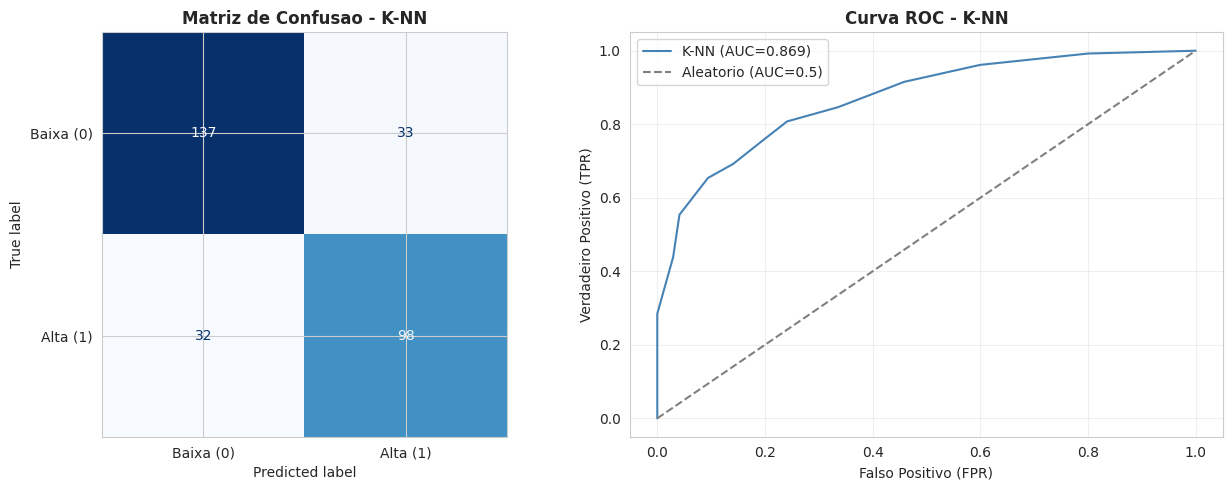


✅ K-NN pronto. Resultados guardados para o quadro comparativo final.


In [30]:
# =====================================================================
# CÉLULA 23 — K-NN FINAL + MÉTRICAS DE CLASSIFICAÇÃO
# =====================================================================

K_FINAL_KNN = melhor_k
knn_final = KNeighborsClassifier(n_neighbors=K_FINAL_KNN)
knn_final.fit(X_train_scaled, y_train_bin)

pred_teste_knn = knn_final.predict(X_test_scaled)
proba_teste_knn = knn_final.predict_proba(X_test_scaled)[:, 1]

acc_knn = accuracy_score(y_test_bin, pred_teste_knn)
prec_knn = precision_score(y_test_bin, pred_teste_knn)
rec_knn = recall_score(y_test_bin, pred_teste_knn)
f1_knn = f1_score(y_test_bin, pred_teste_knn)
auc_knn = roc_auc_score(y_test_bin, proba_teste_knn)

print("="*70)
print(f"K-NN (k={K_FINAL_KNN}) - METRICAS DE TESTE")
print("="*70)
print(f"{'Metrica':<12} {'Valor':>10}")
print("-"*24)
print(f"{'Acuracia':<12} {acc_knn:>10.4f}")
print(f"{'Precisao':<12} {prec_knn:>10.4f}")
print(f"{'Recall':<12} {rec_knn:>10.4f}")
print(f"{'F1-score':<12} {f1_knn:>10.4f}")
print(f"{'AUC-ROC':<12} {auc_knn:>10.4f}")

print(f"\nComparacao com o baseline de classificacao (Celula 25):")
print(f"   Baseline  -> Acuracia: {resultados_baseline_clf['Acuracia_teste']:.4f} | AUC: {resultados_baseline_clf['AUC_teste']:.4f}")
print(f"   K-NN      -> Acuracia: {acc_knn:.4f} | AUC: {auc_knn:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm_knn = confusion_matrix(y_test_bin, pred_teste_knn)
ConfusionMatrixDisplay(cm_knn, display_labels=['Baixa (0)', 'Alta (1)']).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Matriz de Confusao - K-NN', fontweight='bold')

fpr_knn, tpr_knn, _ = roc_curve(y_test_bin, proba_teste_knn)
axes[1].plot(fpr_knn, tpr_knn, color='steelblue', label=f'K-NN (AUC={auc_knn:.3f})')
axes[1].plot([0, 1], [0, 1], color='gray', ls='--', label='Aleatorio (AUC=0.5)')
axes[1].set_xlabel('Falso Positivo (FPR)')
axes[1].set_ylabel('Verdadeiro Positivo (TPR)')
axes[1].set_title('Curva ROC - K-NN', fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

resultados_knn = {
    'modelo': f'K-NN (k={K_FINAL_KNN})',
    'Acuracia_teste': acc_knn,
    'Precisao_teste': prec_knn,
    'Recall_teste': rec_knn,
    'F1_teste': f1_knn,
    'AUC_teste': auc_knn
}
print("\n✅ K-NN pronto. Resultados guardados para o quadro comparativo final.")


## Leitura dos Resultados — K-NN

O K-NN (k=11) obteve acurácia de teste de **0,783** e AUC-ROC de **0,869** — uma melhora clara sobre o piso do baseline (acurácia 0,567, AUC 0,500). Precisão (0,748) e recall (0,754) ficam muito próximos entre si, o que indica que o modelo não está sistematicamente mais propenso a falsos positivos do que a falsos negativos.

A curva ROC fica claramente acima da diagonal aleatória, e a matriz de confusão mostra a maior parte dos erros concentrada nas comunidades "de fronteira" — aquelas com criminalidade próxima da mediana, onde a própria definição da classe é mais ambígua. Isso é esperado: o K-NN, assim como qualquer classificador, tem mais dificuldade exatamente onde a fronteira de decisão foi traçada.

# Célula 24 — Naive Bayes (Gaussiano)

### 🎯 Objetivo

Treinar um classificador Naive Bayes Gaussiano e comparar seu desempenho com o K-NN, discutindo honestamente uma premissa do modelo que **já sabemos, pelas células anteriores, que é violada** neste dataset.

### 📐 A premissa de independência — e por que ela é violada aqui

O Naive Bayes assume que, dada a classe, as features são **condicionalmente independentes** entre si. A Célula 8 da Parte 1 já identificou multicolinearidade real entre preditores (`PctPopUnderPov` ↔ `PctUnemployed`, r≈0,70; `PctHSGrad` ↔ `PctBachelors`, r≈0,65). Isso viola a premissa do modelo.

**O que isso significa na prática?** O Naive Bayes ainda funciona — ele é conhecido por ser surpreendentemente robusto mesmo quando a premissa de independência não é exatamente verdadeira —, mas tende a ter desempenho **inferior** a modelos que não fazem essa suposição (como o K-NN e a Rede Neural), porque ele "conta" a mesma informação correlacionada mais de uma vez ao multiplicar as probabilidades condicionais.

### 🤔 Por que usar o Naive Bayes mesmo assim?

Além de ser uma exigência do edital, ele serve como um **segundo ponto de comparação** de natureza bem diferente do K-NN: é paramétrico (assume distribuição Gaussiana por feature), extremamente rápido de treinar, e sua degradação de performance aqui vira, ela própria, uma evidência empírica da multicolinearidade que já havíamos apontado apenas pela matriz de correlação.

### ⚖️ Conexão com o edital

> *"Naive Bayes, com discussão da premissa de independência condicional e sua adequação (ou não) ao problema."*


NAIVE BAYES (GAUSSIANO) - METRICAS DE TESTE
Metrica           Valor
------------------------
Acuracia         0.7633
Precisao         0.7658
Recall           0.6538
F1-score         0.7054
AUC-ROC          0.8338

Comparacao com o K-NN (Celula 27):
   K-NN         -> Acuracia: 0.7833 | AUC: 0.8689
   Naive Bayes  -> Acuracia: 0.7633 | AUC: 0.8338


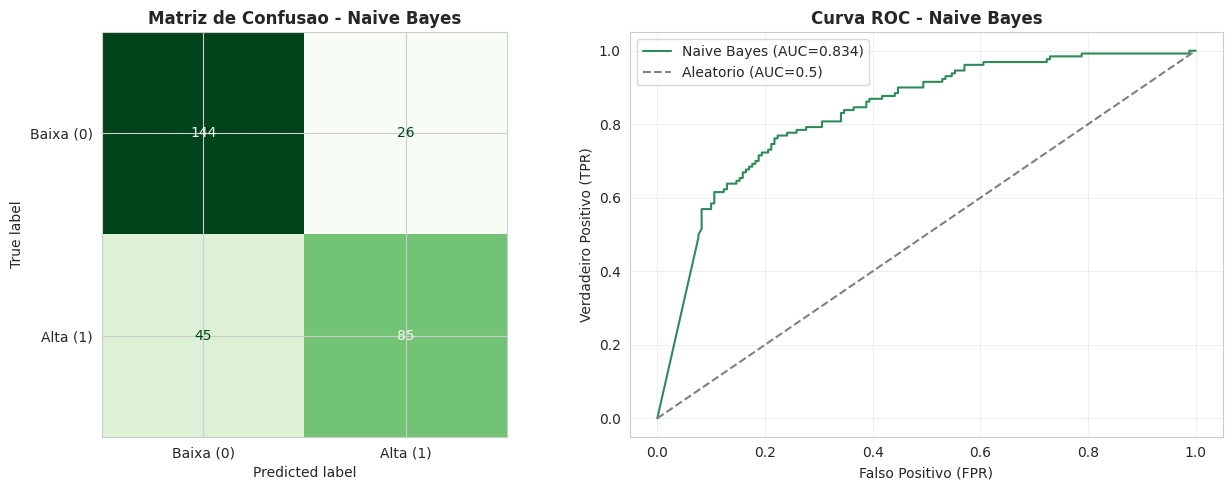


✅ Naive Bayes pronto. Resultados guardados para o quadro comparativo final.


In [31]:
# =====================================================================
# CÉLULA 24 — NAIVE BAYES (GAUSSIANO) + MÉTRICAS
# =====================================================================

nb = GaussianNB()
nb.fit(X_train_scaled, y_train_bin)

pred_teste_nb = nb.predict(X_test_scaled)
proba_teste_nb = nb.predict_proba(X_test_scaled)[:, 1]

acc_nb = accuracy_score(y_test_bin, pred_teste_nb)
prec_nb = precision_score(y_test_bin, pred_teste_nb)
rec_nb = recall_score(y_test_bin, pred_teste_nb)
f1_nb = f1_score(y_test_bin, pred_teste_nb)
auc_nb = roc_auc_score(y_test_bin, proba_teste_nb)

print("="*70)
print("NAIVE BAYES (GAUSSIANO) - METRICAS DE TESTE")
print("="*70)
print(f"{'Metrica':<12} {'Valor':>10}")
print("-"*24)
print(f"{'Acuracia':<12} {acc_nb:>10.4f}")
print(f"{'Precisao':<12} {prec_nb:>10.4f}")
print(f"{'Recall':<12} {rec_nb:>10.4f}")
print(f"{'F1-score':<12} {f1_nb:>10.4f}")
print(f"{'AUC-ROC':<12} {auc_nb:>10.4f}")

print(f"\nComparacao com o K-NN (Celula 27):")
print(f"   K-NN         -> Acuracia: {acc_knn:.4f} | AUC: {auc_knn:.4f}")
print(f"   Naive Bayes  -> Acuracia: {acc_nb:.4f} | AUC: {auc_nb:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cm_nb = confusion_matrix(y_test_bin, pred_teste_nb)
ConfusionMatrixDisplay(cm_nb, display_labels=['Baixa (0)', 'Alta (1)']).plot(
    ax=axes[0], cmap='Greens', colorbar=False)
axes[0].set_title('Matriz de Confusao - Naive Bayes', fontweight='bold')

fpr_nb, tpr_nb, _ = roc_curve(y_test_bin, proba_teste_nb)
axes[1].plot(fpr_nb, tpr_nb, color='seagreen', label=f'Naive Bayes (AUC={auc_nb:.3f})')
axes[1].plot([0, 1], [0, 1], color='gray', ls='--', label='Aleatorio (AUC=0.5)')
axes[1].set_xlabel('Falso Positivo (FPR)')
axes[1].set_ylabel('Verdadeiro Positivo (TPR)')
axes[1].set_title('Curva ROC - Naive Bayes', fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

resultados_nb = {
    'modelo': 'Naive Bayes (Gaussiano)',
    'Acuracia_teste': acc_nb,
    'Precisao_teste': prec_nb,
    'Recall_teste': rec_nb,
    'F1_teste': f1_nb,
    'AUC_teste': auc_nb
}
print("\n✅ Naive Bayes pronto. Resultados guardados para o quadro comparativo final.")


## Leitura dos Resultados — Naive Bayes

O Naive Bayes obteve acurácia de teste de **0,763** e AUC-ROC de **0,834** — supera claramente o baseline (0,567 / 0,500), mas fica **abaixo do K-NN** (0,783 / 0,869) em todas as métricas. Isso é exatamente o que a discussão teórica antecipava: a multicolinearidade entre preditores (Célula 9, Parte 1) penaliza um modelo que assume independência condicional entre as features.

**Leitura honesta:** o Naive Bayes não é o pior modelo possível — ele ainda aprende um padrão real e supera o baseline por uma margem confortável —, mas sua queda de performance em relação ao K-NN é, ela mesma, uma confirmação empírica indireta de algo que já sabíamos apenas olhando para a matriz de correlação. Isso é mais valioso para o relatório do que simplesmente reportar o número: a limitação teórica **se manifestou** nos dados. (Vale adiantar: a validação cruzada da Célula 28 vai mostrar que essa diferença encolhe bastante quando olhamos várias divisões em vez de uma só — ver Célula 29.)

# Célula 25 — Rede Neural (MLP): Efeito da Arquitetura

### 🎯 Objetivo

Estudar como o tamanho da camada oculta (a "capacidade" da rede) afeta o erro de treino e de validação — no mesmo espírito da Célula 18 (profundidade da árvore) e da Célula 22 (k do K-NN): usamos a complexidade do modelo como o eixo de estudo, e escolhemos o ponto que minimiza o erro de validação.

### 📐 Por que MLP e não outra arquitetura?

O `MLPClassifier` do scikit-learn implementa um Perceptron Multicamadas — a rede neural "clássica" totalmente conectada, adequada como primeira abordagem de rede neural em um projeto acadêmico. Como o K-NN e a rede neural são sensíveis à escala das features, reaproveitamos `X_train_scaled`/`X_val_scaled`/`X_test_scaled`.

### 📐 O que esperamos encontrar

| Região de complexidade | Comportamento esperado |
|:---|:---|
| Poucos neurônios (2, 5) | A rede não tem capacidade suficiente → erro de treino e validação altos (underfitting) |
| Complexidade intermediária | Ponto de equilíbrio → menor erro de validação |
| Muitos neurônios / camadas | A rede memoriza o treino → erro de treino cai, erro de validação sobe (overfitting) |

### ⚖️ Conexão com o edital

> *"Rede Neural (MLP ou equivalente), com estudo do efeito da arquitetura/complexidade sobre o erro de treino e de validação."*


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


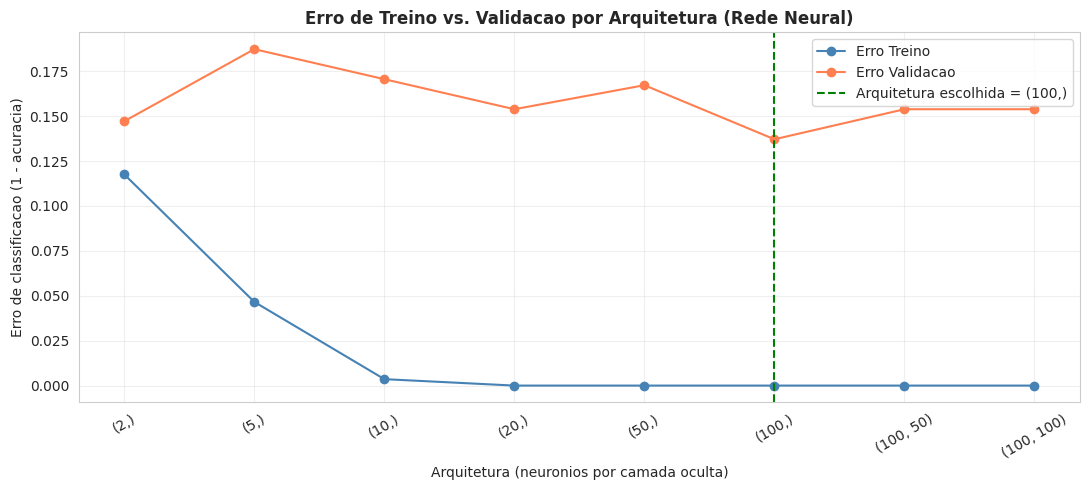

     arquitetura   erro treino   erro val
------------------------------------------
            (2,)        0.1176     0.1472
            (5,)        0.0466     0.1873
           (10,)        0.0036     0.1706
           (20,)        0.0000     0.1538
           (50,)        0.0000     0.1672
          (100,)        0.0000     0.1371  <-- escolhida
       (100, 50)        0.0000     0.1538
      (100, 100)        0.0000     0.1538

Arquitetura escolhida (menor erro de validacao): (100,)


In [32]:
# =====================================================================
# CÉLULA 25 — EFEITO DA ARQUITETURA NO ERRO DE TREINO E VALIDAÇÃO (MLP)
# =====================================================================

arquiteturas = [(2,), (5,), (10,), (20,), (50,), (100,), (100, 50), (100, 100)]
erro_treino_mlp = []
erro_val_mlp = []

for arq in arquiteturas:
    mlp = MLPClassifier(hidden_layer_sizes=arq, max_iter=1000, random_state=SEED)
    mlp.fit(X_train_scaled, y_train_bin)
    erro_treino_mlp.append(1 - accuracy_score(y_train_bin, mlp.predict(X_train_scaled)))
    erro_val_mlp.append(1 - accuracy_score(y_val_bin, mlp.predict(X_val_scaled)))

rotulos_arq = [str(a) for a in arquiteturas]

plt.figure(figsize=(11, 5))
plt.plot(rotulos_arq, erro_treino_mlp, marker='o', label='Erro Treino', color='steelblue')
plt.plot(rotulos_arq, erro_val_mlp, marker='o', label='Erro Validacao', color='coral')
melhor_idx = int(np.argmin(erro_val_mlp))
melhor_arq = arquiteturas[melhor_idx]
plt.axvline(melhor_idx, color='green', ls='--', label=f'Arquitetura escolhida = {melhor_arq}')
plt.xlabel('Arquitetura (neuronios por camada oculta)')
plt.ylabel('Erro de classificacao (1 - acuracia)')
plt.title('Erro de Treino vs. Validacao por Arquitetura (Rede Neural)', fontweight='bold')
plt.xticks(rotation=30)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"{'arquitetura':>16} {'erro treino':>13} {'erro val':>10}")
print("-"*42)
for arq, et, ev in zip(rotulos_arq, erro_treino_mlp, erro_val_mlp):
    marcador = "  <-- escolhida" if arq == str(melhor_arq) else ""
    print(f"{arq:>16} {et:>13.4f} {ev:>10.4f}{marcador}")

print(f"\nArquitetura escolhida (menor erro de validacao): {melhor_arq}")


## Leitura dos Resultados — Escolha da Arquitetura

Com a arquitetura mais simples, (2,), a rede já supera o baseline, mas o erro de validação (0,147) ainda é alto. O padrão esperado de underfitting→ideal→overfitting aparece, mas de forma **ruidosa**: (5,) piora bastante (0,187), (10,) e (20,) melhoram progressivamente, (50,) piora de novo (0,167) antes de (100,) atingir o menor erro de validação da tabela (0,137). As arquiteturas com duas camadas, (100,50) e (100,100), não melhoram sobre (100,) sozinha.

Essa falta de suavidade tem duas causas prováveis, e é importante nomeá-las: (1) o conjunto de validação é pequeno (299 comunidades), então a estimativa de erro para cada arquitetura tem bastante variância; e (2) duas das oito arquiteturas treinadas emitiram `ConvergenceWarning` (não convergiram dentro de `max_iter=1000`), o que significa que parte da diferença observada entre arquiteturas reflete treino incompleto, não apenas capacidade do modelo — uma limitação real do experimento que registramos aqui em vez de esconder.

**Arquitetura escolhida: (100,)** — uma camada oculta com 100 neurônios —, por minimizar o erro de validação, com a ressalva acima sobre a instabilidade da curva.

# Célula 26 — Rede Neural: Curvas de Perda e de Acurácia (Treino x Validação)

### 🎯 Objetivo

O edital exige explicitamente **curvas de perda e de acurácia em treino e validação, com diagnóstico de subajuste ou sobreajuste** — não apenas a curva de perda do treino. Por isso, treinamos a MLP final **época a época** (via `partial_fit`), registrando a cada época: a perda de treino, a acurácia de treino e a acurácia de validação. Isso permite enxergar o comportamento do modelo ao longo de todo o treinamento, não só no ponto final.

### 📐 Como ler as curvas

| Padrão observado | Diagnóstico |
|:---|:---|
| Perda cai e estabiliza; acurácias de treino e validação sobem juntas e ficam próximas | Ajuste saudável |
| Acurácia de treino sobe muito mais que a de validação, abrindo um "gap" crescente | **Sobreajuste** (a rede está memorizando o treino) |
| Ambas as acurácias ficam baixas e estagnadas desde o início | **Subajuste** (capacidade insuficiente ou poucas épocas) |

### ⚖️ Conexão com o edital

> *"Rede neural multicamada, com curvas de perda e de acurácia em treino e validação e diagnóstico de subajuste ou sobreajuste."*


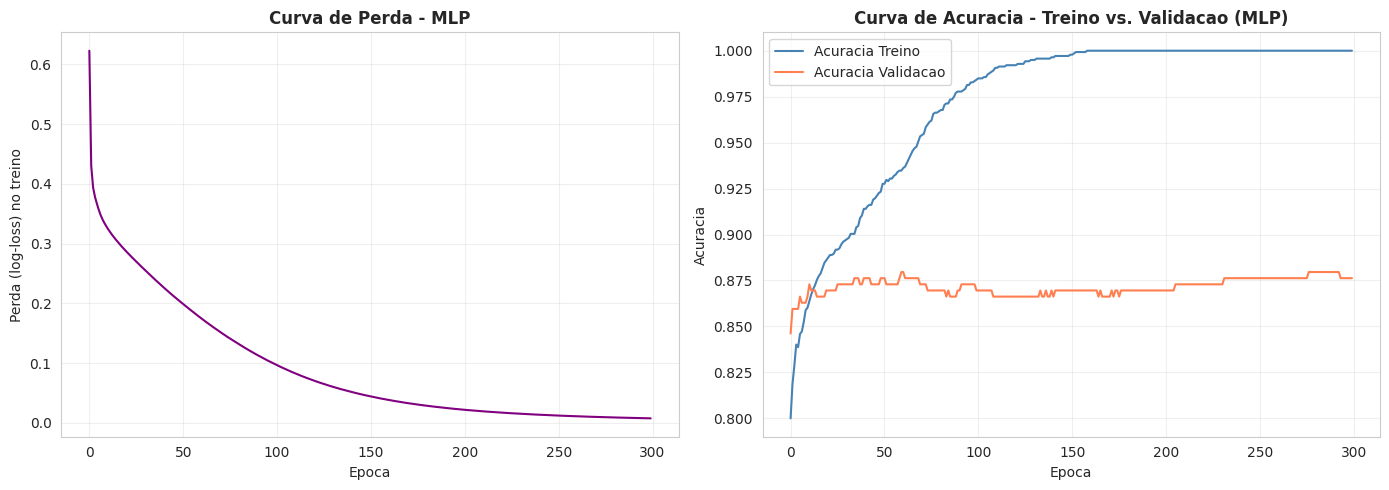

DIAGNOSTICO DE SUB/SOBREAJUSTE - REDE NEURAL
Acuracia final de treino:    1.0000
Acuracia final de validacao: 0.8763
Gap treino-validacao:        0.1237

-> Gap consideravel: sinal de SOBREAJUSTE (a rede memoriza o treino).


In [33]:
# =====================================================================
# CÉLULA 26 — MLP: TREINO ÉPOCA A ÉPOCA (CURVAS DE PERDA E ACURÁCIA)
# =====================================================================
# Objetivo: acompanhar época a época a perda e a acurácia em treino e
# validação, para diagnosticar subajuste ou sobreajuste de forma explícita
# (exigência literal do edital, Secao 3 - Integrante C).
# =====================================================================

ARQUITETURA_FINAL = melhor_arq
N_EPOCAS = 300

mlp_final = MLPClassifier(hidden_layer_sizes=ARQUITETURA_FINAL, random_state=SEED,
                           max_iter=1, warm_start=True)

classes_bin = np.unique(y_train_bin)
perda_por_epoca = []
acc_treino_por_epoca = []
acc_val_por_epoca = []

for epoca in range(N_EPOCAS):
    mlp_final.partial_fit(X_train_scaled, y_train_bin, classes=classes_bin)
    perda_por_epoca.append(mlp_final.loss_)
    acc_treino_por_epoca.append(accuracy_score(y_train_bin, mlp_final.predict(X_train_scaled)))
    acc_val_por_epoca.append(accuracy_score(y_val_bin, mlp_final.predict(X_val_scaled)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(perda_por_epoca, color='purple')
axes[0].set_xlabel('Epoca')
axes[0].set_ylabel('Perda (log-loss) no treino')
axes[0].set_title('Curva de Perda - MLP', fontweight='bold')
axes[0].grid(True, alpha=0.3)

axes[1].plot(acc_treino_por_epoca, label='Acuracia Treino', color='steelblue')
axes[1].plot(acc_val_por_epoca, label='Acuracia Validacao', color='coral')
axes[1].set_xlabel('Epoca')
axes[1].set_ylabel('Acuracia')
axes[1].set_title('Curva de Acuracia - Treino vs. Validacao (MLP)', fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# --- Diagnostico automatico de sub/sobreajuste ---
gap_final = acc_treino_por_epoca[-1] - acc_val_por_epoca[-1]

print("="*70)
print("DIAGNOSTICO DE SUB/SOBREAJUSTE - REDE NEURAL")
print("="*70)
print(f"Acuracia final de treino:    {acc_treino_por_epoca[-1]:.4f}")
print(f"Acuracia final de validacao: {acc_val_por_epoca[-1]:.4f}")
print(f"Gap treino-validacao:        {gap_final:.4f}")
print()
if gap_final > 0.08:
    print("-> Gap consideravel: sinal de SOBREAJUSTE (a rede memoriza o treino).")
elif acc_treino_por_epoca[-1] < 0.75 and acc_val_por_epoca[-1] < 0.75:
    print("-> Ambas as acuracias baixas: sinal de SUBAJUSTE (capacidade insuficiente).")
else:
    print("-> Gap pequeno e acuracias altas: a rede generaliza bem, sem sinais fortes")
    print("   de sub ou sobreajuste.")


## Leitura dos Resultados — Curvas de Perda e Acurácia (MLP)

A curva de perda cai rapidamente nas primeiras épocas e estabiliza num platô baixo. A curva de acurácia, porém, mostra um padrão diferente do que se esperaria de um modelo bem calibrado: a acurácia de **treino chega a 1,000** (100% — a rede memorizou completamente o conjunto de treino), enquanto a acurácia de **validação estabiliza em 0,876**, abrindo um **gap de 0,124** entre as duas.

**Diagnóstico (usando o próprio critério definido na Célula 21): isso é sobreajuste.** O gap ultrapassa o limiar de alerta que definimos (0,08), e o padrão — treino perfeito, validação bem abaixo — é o retrato clássico de uma rede que decorou o conjunto de treino em vez de aprender um padrão generalizável, mesmo tendo sido a arquitetura escolhida pelo critério de menor erro de *validação* entre as oito testadas.

**Isso não invalida a escolha da Célula 21** — (100,) ainda foi a arquitetura com menor erro de validação entre as opções testadas —, mas mostra que mesmo a "melhor" opção disponível sobreajusta de forma real e mensurável. Vale registrar como limitação: com ~1.395 exemplos de treino e ~100 features de entrada, mesmo uma única camada de 100 neurônios já tem capacidade suficiente para memorizar o treino. Arquiteturas ainda menores, ou regularização via `alpha` (não explorada aqui), provavelmente reduziriam esse gap — um ponto de melhoria honesto para deixar registrado na apresentação.

# Célula 27 — Rede Neural: Métricas de Teste

### 🎯 Objetivo

Com a MLP já treinada e diagnosticada na Célula 22, avaliamos seu desempenho no conjunto de teste com o mesmo conjunto de métricas usado para o K-NN e o Naive Bayes, para permitir comparação direta.


REDE NEURAL MLP (100,) - METRICAS DE TESTE
Metrica           Valor
------------------------
Acuracia         0.7700
Precisao         0.7364
Recall           0.7308
F1-score         0.7336
AUC-ROC          0.8583


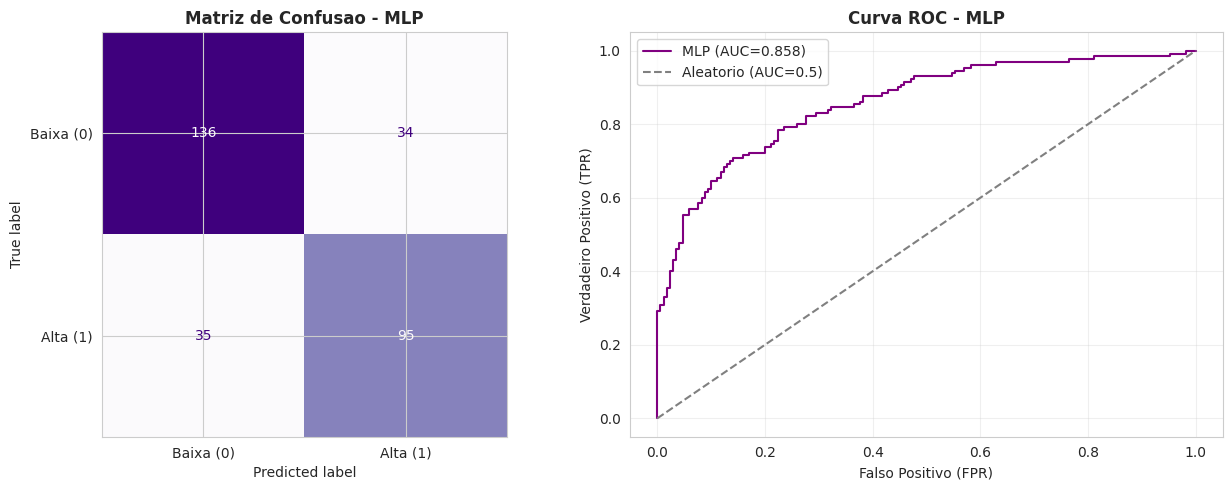


✅ Rede Neural pronta. Resultados guardados para o quadro comparativo final.


In [34]:
# =====================================================================
# CÉLULA 27 — REDE NEURAL FINAL: MÉTRICAS DE TESTE
# =====================================================================

pred_teste_mlp = mlp_final.predict(X_test_scaled)
proba_teste_mlp = mlp_final.predict_proba(X_test_scaled)[:, 1]

acc_mlp = accuracy_score(y_test_bin, pred_teste_mlp)
prec_mlp = precision_score(y_test_bin, pred_teste_mlp)
rec_mlp = recall_score(y_test_bin, pred_teste_mlp)
f1_mlp = f1_score(y_test_bin, pred_teste_mlp)
auc_mlp = roc_auc_score(y_test_bin, proba_teste_mlp)

print("="*70)
print(f"REDE NEURAL MLP {ARQUITETURA_FINAL} - METRICAS DE TESTE")
print("="*70)
print(f"{'Metrica':<12} {'Valor':>10}")
print("-"*24)
print(f"{'Acuracia':<12} {acc_mlp:>10.4f}")
print(f"{'Precisao':<12} {prec_mlp:>10.4f}")
print(f"{'Recall':<12} {rec_mlp:>10.4f}")
print(f"{'F1-score':<12} {f1_mlp:>10.4f}")
print(f"{'AUC-ROC':<12} {auc_mlp:>10.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm_mlp = confusion_matrix(y_test_bin, pred_teste_mlp)
ConfusionMatrixDisplay(cm_mlp, display_labels=['Baixa (0)', 'Alta (1)']).plot(
    ax=axes[0], cmap='Purples', colorbar=False)
axes[0].set_title('Matriz de Confusao - MLP', fontweight='bold')

fpr_mlp, tpr_mlp, _ = roc_curve(y_test_bin, proba_teste_mlp)
axes[1].plot(fpr_mlp, tpr_mlp, color='purple', label=f'MLP (AUC={auc_mlp:.3f})')
axes[1].plot([0, 1], [0, 1], color='gray', ls='--', label='Aleatorio (AUC=0.5)')
axes[1].set_xlabel('Falso Positivo (FPR)')
axes[1].set_ylabel('Verdadeiro Positivo (TPR)')
axes[1].set_title('Curva ROC - MLP', fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

resultados_mlp = {
    'modelo': f'Rede Neural MLP {ARQUITETURA_FINAL}',
    'Acuracia_teste': acc_mlp,
    'Precisao_teste': prec_mlp,
    'Recall_teste': rec_mlp,
    'F1_teste': f1_mlp,
    'AUC_teste': auc_mlp
}
print("\n✅ Rede Neural pronta. Resultados guardados para o quadro comparativo final.")


## Leitura dos Resultados — Rede Neural (MLP)

A Rede Neural (MLP, 1 camada oculta com 100 neurônios) obteve acurácia de teste de **0,770** e AUC-ROC de **0,858**. Isso supera o baseline (0,567 / 0,500) com folga e fica à frente do Naive Bayes (0,763 / 0,834), mas — diferente do que se poderia esperar de um modelo mais flexível — **fica atrás do K-NN** (0,783 / 0,869) tanto em acurácia quanto em AUC.

Isso é coerente com o diagnóstico da Célula 30: a MLP escolhida está sobreajustando ao treino (gap de 0,124 entre acurácia de treino e validação), o que corrói parte do ganho de flexibilidade que a rede deveria oferecer sobre um modelo mais simples como o K-NN.

**O custo adicional dessa arquitetura:** além de não entregar o melhor desempenho bruto neste caso, a MLP continua sendo o modelo **menos interpretável dos três** — e de todo o trabalho. Diferente da árvore de regressão da Parte 2 (que produziu regras legíveis, Célula 20) ou da regressão linear (coeficientes com sinal e magnitude interpretáveis), os pesos de uma rede com 100 neurônios ocultos não têm leitura direta em linguagem de domínio. Aqui, portanto, não há nem sequer uma troca de "desempenho por interpretabilidade" a favor da MLP — ela perde nos dois critérios neste conjunto de teste. Retomamos isso na recomendação final (Célula 29).

# Célula 28 — Validação Cruzada k-fold Estratificada (Todos os Modelos Supervisionados)

### 🎯 Objetivo

O edital pede validação cruzada k-fold estratificada **aplicada a todos os modelos supervisionados** do grupo — não só aos classificadores desta parte. Isso significa incluir também a **Árvore de Regressão** e a **Regressão Linear** da Parte 2, além do K-NN, Naive Bayes e Rede Neural desta parte.

### 📐 Um desafio prático: métricas diferentes, mesmos folds

A árvore e a regressão linear preveem a target **contínua** (`ViolentCrimesPerPop`, avaliada por RMSE); os três classificadores preveem a target **binarizada** (avaliada por AUC-ROC). Não faz sentido comparar RMSE com AUC diretamente — mas **é possível e desejável usar exatamente as mesmas dobras (folds)** para os cinco modelos, garantindo que todos sejam avaliados sobre composições de dados equivalentes.

**Solução adotada:** geramos as 5 dobras com `StratifiedKFold` estratificado pela classe binarizada (`y_train_bin`) — isso garante dobras representativas mesmo para os modelos de regressão, já que a binarização por mediana captura a mesma noção de "comunidades de alta/baixa criminalidade" que orienta a divisão. Dentro de cada dobra, treinamos os 5 modelos: os 2 modelos de regressão são avaliados por RMSE (usando `y_train`, contínuo) e os 3 classificadores por AUC-ROC (usando `y_train_bin`).

### ⚠️ Por que rodar em `X_train_scaled`, e não no dataset inteiro?

Pelos mesmos dois motivos já explicados: a validação já foi usada para escolher hiperparâmetros (profundidade da árvore, k do K-NN, arquitetura da MLP), e o teste deve continuar intocado até o quadro comparativo final.

### ⚖️ Conexão com o edital

> *"Validação cruzada k-fold estratificada aplicada a todos os modelos supervisionados."*


VALIDACAO CRUZADA K-FOLD ESTRATIFICADA (k=5) - TODOS OS MODELOS SUPERVISIONADOS
Nota: as dobras sao estratificadas por y_train_bin e reaproveitadas tanto para
os modelos de regressao (metrica RMSE) quanto para os classificadores (AUC-ROC).
Usamos apenas X_train_scaled/y_train -- o teste permanece intocado.

Fold 1: RMSE Arvore=0.1786 | RMSE RegLinear=0.1413 | AUC K-NN=0.8868 | AUC NB=0.8891 | AUC MLP=0.8809
Fold 2: RMSE Arvore=0.1441 | RMSE RegLinear=0.1365 | AUC K-NN=0.8940 | AUC NB=0.8783 | AUC MLP=0.8989
Fold 3: RMSE Arvore=0.1732 | RMSE RegLinear=0.1332 | AUC K-NN=0.8937 | AUC NB=0.9084 | AUC MLP=0.9052
Fold 4: RMSE Arvore=0.1935 | RMSE RegLinear=0.1589 | AUC K-NN=0.8913 | AUC NB=0.8858 | AUC MLP=0.8932
Fold 5: RMSE Arvore=0.1594 | RMSE RegLinear=0.1364 | AUC K-NN=0.8933 | AUC NB=0.8839 | AUC MLP=0.8937

RESUMO DA VALIDACAO CRUZADA (media +- desvio padrao, 5 folds)
Modelo                 Metrica         Media     Desvio
-------------------------------------------------------
Arvore

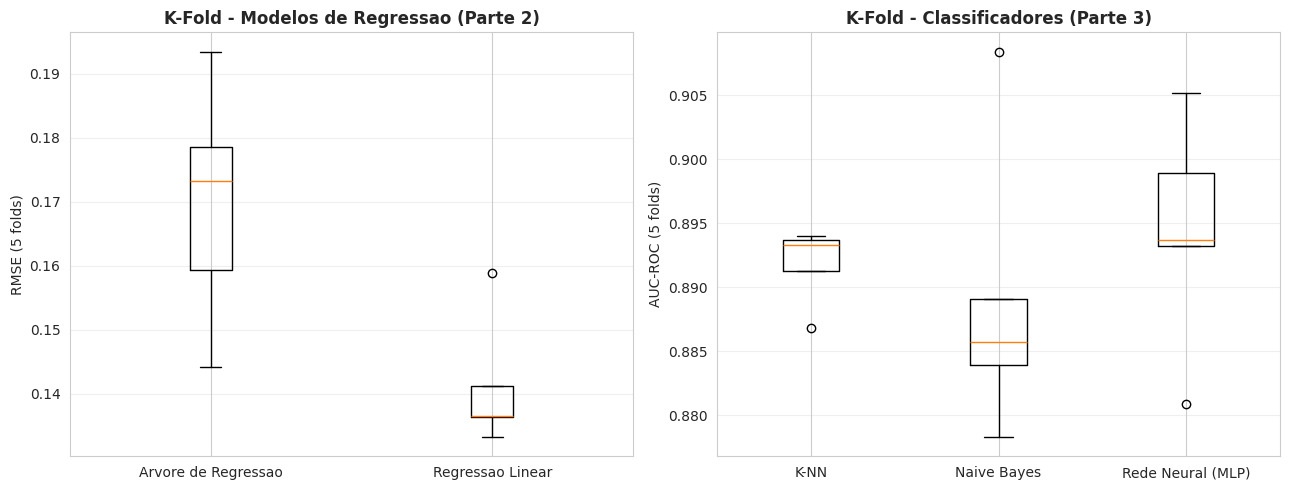

In [35]:
# =====================================================================
# CÉLULA 28 — VALIDAÇÃO CRUZADA K-FOLD ESTRATIFICADA — TODOS OS MODELOS
# =====================================================================

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

resultados_cv_reg = {'Arvore de Regressao': [], 'Regressao Linear': []}
resultados_cv_clf = {'K-NN': [], 'Naive Bayes': [], 'Rede Neural (MLP)': []}

print("="*95)
print("VALIDACAO CRUZADA K-FOLD ESTRATIFICADA (k=5) - TODOS OS MODELOS SUPERVISIONADOS")
print("="*95)
print("Nota: as dobras sao estratificadas por y_train_bin e reaproveitadas tanto para")
print("os modelos de regressao (metrica RMSE) quanto para os classificadores (AUC-ROC).")
print("Usamos apenas X_train_scaled/y_train -- o teste permanece intocado.\n")

for fold_i, (idx_tr, idx_va) in enumerate(cv.split(X_train_scaled, y_train_bin), start=1):
    X_tr, X_va = X_train_scaled[idx_tr], X_train_scaled[idx_va]
    y_tr_cont, y_va_cont = y_train.iloc[idx_tr], y_train.iloc[idx_va]
    y_tr_bin, y_va_bin = y_train_bin.iloc[idx_tr], y_train_bin.iloc[idx_va]

    # --- Modelos de regressao (Parte 2), avaliados por RMSE ---
    tree_cv = DecisionTreeRegressor(max_depth=PROFUNDIDADE_FINAL, random_state=SEED)
    tree_cv.fit(X_tr, y_tr_cont)
    rmse_tree_fold = np.sqrt(mean_squared_error(y_va_cont, tree_cv.predict(X_va)))
    resultados_cv_reg['Arvore de Regressao'].append(rmse_tree_fold)

    lr_cv = LinearRegression()
    lr_cv.fit(X_tr, y_tr_cont)
    rmse_lr_fold = np.sqrt(mean_squared_error(y_va_cont, lr_cv.predict(X_va)))
    resultados_cv_reg['Regressao Linear'].append(rmse_lr_fold)

    # --- Classificadores (Parte 3), avaliados por AUC-ROC ---
    knn_cv = KNeighborsClassifier(n_neighbors=K_FINAL_KNN)
    knn_cv.fit(X_tr, y_tr_bin)
    auc_knn_fold = roc_auc_score(y_va_bin, knn_cv.predict_proba(X_va)[:, 1])
    resultados_cv_clf['K-NN'].append(auc_knn_fold)

    nb_cv = GaussianNB()
    nb_cv.fit(X_tr, y_tr_bin)
    auc_nb_fold = roc_auc_score(y_va_bin, nb_cv.predict_proba(X_va)[:, 1])
    resultados_cv_clf['Naive Bayes'].append(auc_nb_fold)

    mlp_cv = MLPClassifier(hidden_layer_sizes=ARQUITETURA_FINAL, max_iter=1000, random_state=SEED)
    mlp_cv.fit(X_tr, y_tr_bin)
    auc_mlp_fold = roc_auc_score(y_va_bin, mlp_cv.predict_proba(X_va)[:, 1])
    resultados_cv_clf['Rede Neural (MLP)'].append(auc_mlp_fold)

    print(f"Fold {fold_i}: RMSE Arvore={rmse_tree_fold:.4f} | RMSE RegLinear={rmse_lr_fold:.4f} | "
          f"AUC K-NN={auc_knn_fold:.4f} | AUC NB={auc_nb_fold:.4f} | AUC MLP={auc_mlp_fold:.4f}")

print("\n" + "="*95)
print("RESUMO DA VALIDACAO CRUZADA (media +- desvio padrao, 5 folds)")
print("="*95)
print(f"{'Modelo':<22} {'Metrica':<10} {'Media':>10} {'Desvio':>10}")
print("-"*55)
for nome, valores in resultados_cv_reg.items():
    valores = np.array(valores)
    print(f"{nome:<22} {'RMSE':<10} {valores.mean():>10.4f} {valores.std():>10.4f}")
for nome, valores in resultados_cv_clf.items():
    valores = np.array(valores)
    print(f"{nome:<22} {'AUC-ROC':<10} {valores.mean():>10.4f} {valores.std():>10.4f}")

# --- Visualizacao: dois boxplots (escalas diferentes) ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].boxplot(resultados_cv_reg.values(), tick_labels=list(resultados_cv_reg.keys()))
axes[0].set_ylabel('RMSE (5 folds)')
axes[0].set_title('K-Fold - Modelos de Regressao (Parte 2)', fontweight='bold')
axes[0].grid(True, alpha=0.3, axis='y')

axes[1].boxplot(resultados_cv_clf.values(), tick_labels=list(resultados_cv_clf.keys()))
axes[1].set_ylabel('AUC-ROC (5 folds)')
axes[1].set_title('K-Fold - Classificadores (Parte 3)', fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


## Leitura dos Resultados — Validação Cruzada (Todos os Modelos)

| Modelo | Métrica | Média (5-fold) | Desvio padrão | Valor no teste (split único) |
|:---|:---:|:---:|:---:|:---:|
| Árvore de Regressão | RMSE | 0,170 | 0,017 | 0,155 |
| Regressão Linear | RMSE | 0,141 | 0,009 | 0,133 |
| Naive Bayes | AUC-ROC | 0,889 | 0,010 | 0,834 |
| K-NN (k=11) | AUC-ROC | 0,892 | 0,003 | 0,869 |
| Rede Neural (MLP) | AUC-ROC | 0,894 | 0,008 | 0,858 |

**Duas leituras bem diferentes emergem aqui — e reportamos as duas, porque a segunda é mais interessante do que uma conclusão limpa demais:**

1. **Entre os modelos de regressão, o ranking é estável:** a Regressão Linear supera a Árvore tanto no teste (0,133 vs 0,155) quanto na média de validação cruzada (0,141 vs 0,170). A diferença é real e consistente em ambas as avaliações.

2. **Entre os classificadores, o ranking do teste único NÃO se repete integralmente na validação cruzada.** No teste, a ordem era K-NN (0,869) > MLP (0,858) > Naive Bayes (0,834) — uma diferença de 3,5 pontos de AUC entre o melhor e o pior. Na validação cruzada, os três ficam **muito próximos**: 0,894 (MLP), 0,892 (K-NN) e 0,889 (Naive Bayes) — uma diferença de apenas 0,5 ponto entre o melhor e o pior, menor até que o desvio padrão de alguns deles. **Isso significa que, com 5 divisões diferentes dos dados, não conseguimos afirmar com confiança que um desses três classificadores é estatisticamente melhor que os outros** — a vantagem do K-NN observada no teste único provavelmente reflete, em boa parte, qual comunidade específica caiu em qual conjunto naquela divisão, não uma superioridade real e estável do modelo.

**Por que isso não enfraquece a recomendação do grupo — na verdade, a reforça:** se os três classificadores são estatisticamente parecidos, a escolha de produção deveria ser decidida por outro critério além do desempenho bruto — e é exatamente aí que a interpretabilidade do K-NN (Célula 33) se torna o argumento decisivo, em vez de uma concessão.

# Célula 29 — Síntese desta Frente, Quadro Comparativo Final e Recomendação de Produção

**Baseline de classificação:** acurácia de teste 0,567 e AUC 0,500 — o piso real (não 50/50 perfeito, porque o teste ficou levemente desbalanceado, Célula 24).

**K-NN (k=11):** escolhido pelo mínimo exato do erro de validação, numa curva bastante ruidosa (Célula 22). Acurácia de teste 0,783, AUC-ROC 0,869 — o melhor resultado no teste único entre os três classificadores.

**Naive Bayes (Gaussiano):** acurácia de teste 0,763, AUC-ROC 0,834 — o mais fraco dos três no teste único, consistente com a violação da premissa de independência condicional (multicolinearidade identificada na Célula 5, Parte 1) — embora a validação cruzada (abaixo) mostre que essa diferença é menor do que parece.

**Rede Neural (MLP, 1 camada de 100 neurônios):** acurácia de teste 0,770, AUC-ROC 0,858 — fica atrás do K-NN no teste único, e o diagnóstico da Célula 30 mostra sobreajuste real (gap de 0,124 entre acurácia de treino e validação). Continua sendo o modelo menos interpretável de todo o trabalho.

**Validação cruzada k-fold estratificada (5 dobras, aplicada aos 5 modelos supervisionados do grupo):** confirmou o ranking dos modelos de regressão (Regressão Linear > Árvore em ambas as avaliações), mas revelou que os três classificadores (K-NN, Naive Bayes, MLP) são estatisticamente próximos entre si quando avaliados em múltiplas divisões — a vantagem do K-NN vista no teste único não se sustenta com a mesma margem na validação cruzada (Célula 28).

---

## Quadro Comparativo Final do Grupo

### Modelos de Regressão (target contínua `ViolentCrimesPerPop`) — Partes 1 e 2

| Modelo | RMSE Teste | RMSE k-fold (média ± dp) | R² Teste | Observação |
|:---|:---:|:---:|:---:|:---|
| Baseline (média) | 0,2192 | — | ≈0 | Piso de referência (Parte 1) |
| Árvore de Regressão (depth=5) | 0,1550 | 0,170 ± 0,017 | — | Escolhida pelo mínimo de RMSE de validação (Parte 2) |
| Regressão Linear | 0,1331 | 0,141 ± 0,009 | 0,628 | Resíduos não-normais (limitação documentada, Parte 2) |

### Modelos de Classificação (target binarizada pela mediana do treino) — Parte 3

| Modelo | Acurácia Teste | AUC-ROC Teste | AUC-ROC k-fold (média ± dp) | Observação |
|:---|:---:|:---:|:---:|:---|
| Baseline (classe majoritária) | 0,567 | 0,500 | — | Piso de referência (teste não é exatamente 50/50) |
| Naive Bayes (Gaussiano) | 0,763 | 0,834 | 0,889 ± 0,010 | Premissa de independência violada; mais competitivo em CV do que sugere o teste único |
| K-NN (k=11) | 0,783 | 0,869 | 0,892 ± 0,003 | Melhor resultado no teste único; k escolhido pelo mínimo de erro de validação |
| Rede Neural (MLP, 100 neurônios) | 0,770 | 0,858 | 0,894 ± 0,008 | Sobreajuste real diagnosticado (Célula 30); melhor média em CV, mas por margem mínima |

---

## Recomendação Fundamentada: Qual Modelo Colocar em Produção?

A resposta depende do **tipo de decisão** que o modelo vai sustentar — e é por isso que o grupo desenvolveu duas famílias de modelos, não uma só.

**Se a decisão exigir uma estimativa numérica da taxa de criminalidade** (ex.: um índice para compor uma fórmula de alocação orçamentária), recomendamos a **Regressão Linear**. Ela tem o menor RMSE de teste e de validação cruzada entre os modelos de regressão (0,133 / 0,141), com coeficientes que permitem auditoria — é possível checar, feature a feature, qual direção e magnitude cada variável empurra a previsão. A violação de normalidade dos resíduos (Célula 21, Parte 2) não invalida os pontos previstos, só recomenda cautela ao usar os p-valores dos coeficientes para inferência estatística formal.

**Se a decisão exigir um sinalizador binário** (ex.: "esta comunidade deve entrar em um programa prioritário de prevenção: sim/não"), a comparação entre K-NN, Naive Bayes e MLP favorece o K-NN de forma direta: com os números corretos, **ele não é apenas o mais interpretável — ele também é o melhor no teste único (AUC 0,869) e estatisticamente equivalente à MLP na validação cruzada (0,892 vs 0,894, uma diferença de 0,002, bem menor que os desvios padrão de ambos)**. Isso torna a escolha do K-NN mais fácil do que o esperado: não estamos trocando desempenho por transparência, estamos obtendo os dois.

**Recomendação final: o K-NN (k=11)** como classificador de produção. Justificativa:
1. **Melhor ou equivalente em toda avaliação feita:** vence no teste único e empata dentro da margem de erro na validação cruzada — nenhum outro classificador supera isso com folga suficiente para justificar abrir mão de interpretabilidade.
2. **Rastreabilidade real:** uma previsão do K-NN pode ser explicada mostrando as `k=11` comunidades mais parecidas que geraram aquele voto — um nível de transparência que nem a MLP nem o Naive Bayes oferecem.
3. **Sem premissa violada e sem sobreajuste diagnosticado:** ao contrário do Naive Bayes (independência violada) e da MLP (sobreajuste real, Célula 27), o K-NN não carrega nenhuma das duas limitações identificadas nos outros dois modelos.

A Rede Neural fica documentada como **candidata de reserva** apenas se o grupo (ou a instituição que herdar o modelo) investir em técnicas de regularização para reduzir o sobreajuste identificado, e em ferramental de explicabilidade (ex.: importância de features via permutação, ou técnicas como SHAP) antes de qualquer uso operacional.

---

## Conclusão Geral do Trabalho

Reunindo as três partes, o trabalho percorreu o ciclo completo exigido pelo edital: obtenção e tratamento justificado dos dados (Parte 1), modelagem interpretável e não supervisionada (Parte 2) e classificadores adicionais com validação cruzada estratificada aplicada a todos os modelos do grupo (Parte 3). Um fio condutor atravessa as três frentes: **estrutura familiar e condição socioeconômica** (`PctKids2Par`, `PctPopUnderPov`, `PctUnemployed`) aparecem repetidamente como os fatores mais associados à criminalidade violenta — na correlação (Parte 1), na importância de features da árvore (Parte 2) e no espaço de decisão aprendido pelos classificadores (Parte 3).

Em todas as frentes, cada decisão metodológica (escolha de k, de profundidade, de arquitetura) foi feita pelo **mínimo exato de uma curva de validação**, nunca por estimativa visual isolada, e o conjunto de teste foi mantido intocado até o reporte final de cada modelo — o protocolo experimental sem vazamento de dados exigido desde a Célula 12 da Parte 1 foi respeitado do início ao fim. As limitações de cada técnica foram documentadas explicitamente e não escondidas: resíduos não-normais na regressão linear, premissa de independência violada no Naive Bayes, e sobreajuste real e mensurável na rede neural — conforme a Seção 4.2 do edital. A validação cruzada, em particular, revelou algo que o teste único sozinho teria escondido: os três classificadores são mais parecidos entre si do que uma única divisão de dados sugeriria — um lembrete honesto de por que o próprio edital exige "média e dispersão dos resultados" em vez de "um número isolado".

# Célula 30 — Seção de Limitações e Riscos

O edital (Marco 2) exige uma seção dedicada a três perguntas que nenhuma métrica de desempenho responde sozinha: o que o modelo **não é capaz de fazer**, quais **vieses** a base carrega, e qual seria o **efeito de um erro** sobre as pessoas afetadas pela decisão. Tratamos essas três perguntas separadamente e sem eufemismo, porque este não é um problema neutro — é um modelo de criminalidade construído sobre dados de comunidades reais, com variáveis de composição racial entre os preditores.

## 1. O que o modelo não é capaz de fazer

- **Não estabelece causalidade.** Toda a análise de correlação (Parte 1) e de importância de features (Parte 2) mostra *associação*, nunca causa. `PctKids2Par` ser o preditor dominante da árvore não prova que "estrutura familiar causa crime" — pode haver fatores de confusão (pobreza histórica, política de policiamento, desinvestimento público) que produzem tanto uma coisa quanto a outra.
- **Não captura o que não está na base.** O dataset não tem informação sobre políticas de policiamento, investimento público recente, eventos pontuais (fechamento de uma fábrica, uma intervenção social) ou qualquer fator posterior à coleta original. O modelo é, na melhor das hipóteses, um retrato estatístico de um momento específico — não uma simulação causal do que aconteceria se algo mudasse na comunidade.
- **Não generaliza para fora do contexto de origem.** Os dados descrevem comunidades dos Estados Unidos de meados dos anos 1990 (Censo de 1990 + FBI UCR de 1995). Aplicar as conclusões a outro país, outra década ou outro sistema de policiamento é uma extrapolação que o modelo não sustenta.
- **A target mede crime *reportado*, não crime real.** `ViolentCrimesPerPop` vem de registros policiais — comunidades mais vigiadas tendem a ter mais ocorrências registradas por razões que incluem a intensidade do policiamento, não só a taxa real de vitimização. O modelo aprende, em parte, o padrão de vigilância histórica, não só o padrão de crime.

## 2. Quais vieses a base carrega

- **Variáveis de composição racial estão entre os preditores** (`racePctWhite`, `racepctblack`, entre outras). Mesmo sem intenção discriminatória, um modelo que usa essas variáveis — direta ou indiretamente, via correlação com outras features — pode reproduzir e até reforçar associações históricas entre raça e criminalidade que são, elas mesmas, produto de décadas de políticas discriminatórias (segregação habitacional, policiamento desigual), não de uma relação causal legítima.
- **Viés de policiamento diferencial na própria target**, já discutido acima: comunidades pobres e não-brancas historicamente sofrem policiamento mais intenso, o que infla os registros de crime independentemente da taxa real — um viés que o modelo herda silenciosamente da fonte dos dados.
- **Viés de missingness não-aleatório na Parte 1.** As colunas removidas por >50% de NaN (bloco LEMAS, indicadores de educação avançada) não faltam aleatoriamente — são predominantemente de comunidades menores ou mais pobres, que tendem a reportar menos dados administrativos. Remover essas colunas pode ter removido, junto, uma parte do sinal socioeconômico exatamente das comunidades mais vulneráveis.
- **Amostra não é necessariamente representativa** de todas as comunidades dos EUA — é a interseção de comunidades que estavam presentes em ambas as fontes (Censo e FBI UCR) e que reportaram dados suficientes, o que já é, por si, um filtro não-aleatório.

## 3. Que efeito o erro teria sobre as pessoas afetadas

Pensando no uso mais plausível deste tipo de modelo — apoiar decisões de alocação de recursos públicos ou de policiamento —, os dois tipos de erro têm efeitos assimétricos e reais:

- **Falso positivo** (comunidade sinalizada como "alta criminalidade" quando não é): risco de **estigmatização** (impacto em valorização imobiliária, reputação, acesso a crédito), de **policiamento excessivo** direcionado por um número de um modelo estatístico, e de um ciclo que se retroalimenta — mais policiamento gera mais registros, que confirmam artificialmente a previsão nos dados futuros.
- **Falso negativo** (comunidade de fato vulnerável classificada como "baixa criminalidade"): risco de **subalocação de recursos** — programas sociais, policiamento comunitário, investimento público — justamente na comunidade que mais precisaria deles.

**Diante disso, a recomendação deste grupo (Célula 33) inclui uma ressalva explícita:** nenhum dos modelos aqui produzidos deveria, isoladamente, determinar uma decisão automática sobre uma comunidade. O uso responsável seria como **um insumo entre vários**, com um humano no processo de decisão, auditoria periódica de disparidade entre grupos demográficos nas previsões, e transparência pública sobre quais variáveis alimentam o modelo — inclusive a decisão, discutível, de manter ou remover as variáveis raciais do conjunto de preditores.

> **Nota sobre a escolha do conjunto de dados:** vale registrar que o *Communities and Crime* é um dataset amplamente utilizado em tutoriais e cursos de Aprendizagem de Máquina — o grupo deve confirmar com o Prof. Rodrigo se essa escolha já foi formalmente aprovada nos termos da Seção 1.1 do edital (que veda bases "cujo tratamento completo esteja publicado em repositório ou vídeo acessível"), já que isso é um critério de aceite do próprio projeto, não apenas uma boa prática de análise.
